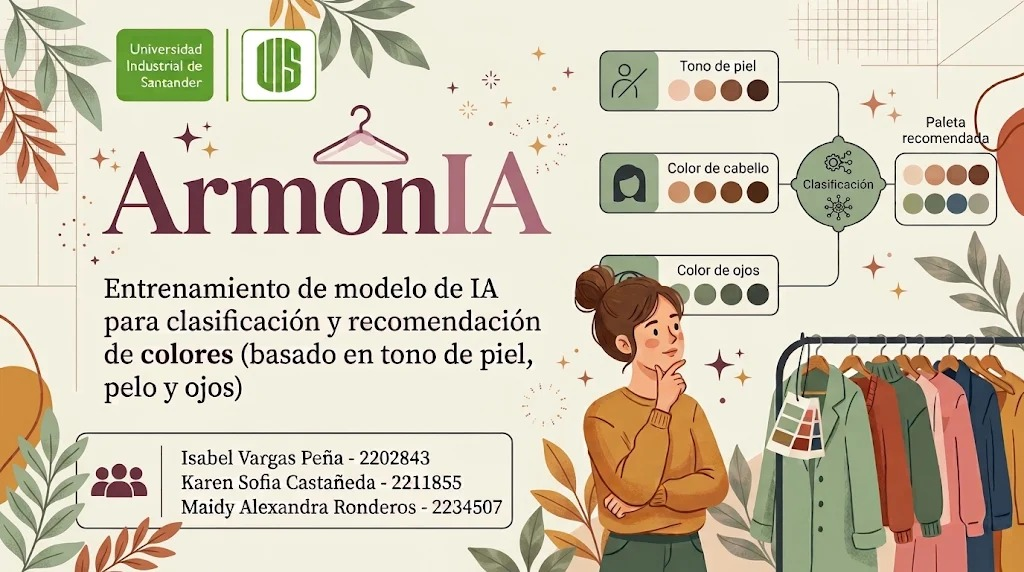

# **Sustentación Proyecto IA 1 / Grupo F1 - 2026-2**

###**ArmonIA** 💮

ArmonIA es un proyecto de inteligencia artificial que busca recomendar prendas de vestir personalizadas a partir de características como el color de cabello, ojos, tono de piel y proporción corporal, proporcionando sugerencias de colores, estilos y materiales que pueden favorecer a cada persona.

**Integrantes:**

1. Isabel Vargas Peña - 2202843
2. Karen Sofia Castañeda - 2211855
3. Maidy Alexandra Ronderos - 2234507

# *Tipo de problema: Clasificación*

Este proyecto corresponde a un problema de clasificación, porque a partir de características del usuario, como color de cabello, ojos y otras variables del dataset, el modelo busca recomendar categorías de ropa. La salida corresponde a clases o categorías definidas, no a un valor numérico continuo.

Por esta razón, no es un problema de regresión. En este proyecto se utiliza clasificación.

**Variable objetivo:** `Recommended Clothing Colors` (3 clases: paleta cálida, fría o neutra). Las entradas son las 4 características de color de la persona (pelo, ojos, piel y subtono); en la sección *0. Corrección* de la segunda entrega se explica por qué las demás columnas del dataset no se usan como entrada.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st


from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split


In [2]:
#Carga el archivo CSV y lo guarda en un DataFrame llamado df.
try:
    from google.colab import files
    files.upload()            # en Colab: seleccionar recommendations.csv
except ImportError:
    pass                      # en local: el CSV debe estar en la misma carpeta
#------------------------------------------------------
#Muestra las primeras 5 filas del dataset.
df = pd.read_csv('recommendations.csv', encoding='latin-1')
df.head()

,Hair Color,Eye Color,Skin Tone,Under Tone,Torso length,Body Proportion,Recommended Clothing Colors,Avoid Clothing Colors,Recommended Fitting Style,Recommended Materials,Recommended Patterns,Recommended Jewelry Metal,Recommended Shoes,Recommended Clothing Color Wheel Region,Avoid Clothing Color Wheel Region,Fabric Nature,Don't Exaggerate,Do Exaggerate
0,Black,Brown,Very Fair,Warm,Short Torso,Rectangle,"Earth Tones, Olive, Coral, Peach, Mustard, War...","Cool Blue, Icy Gray, Jewel Tones",Defined Waist,Structured Cotton,Curved Lines,Gold,Low Heels or Flats,"Warm colors (red, orange, yellow, warm greens)",Opposite on color wheel,Firm,Don't exaggerate straight lines,Exaggerate waistline
1,Black,Brown,Very Fair,Warm,Short Torso,Inverted Triangle,"Earth Tones, Olive, Coral, Peach, Mustard, War...","Cool Blue, Icy Gray, Jewel Tones",A-Line Bottoms,Flowy Fabric,Vertical Stripes,Gold,Low Heels or Flats,"Warm colors (red, orange, yellow, warm greens)",Opposite on color wheel,Flowy,Don't exaggerate shoulders,Exaggerate hips
2,Black,Brown,Very Fair,Warm,Short Torso,Triangle,"Earth Tones, Olive, Coral, Peach, Mustard, War...","Cool Blue, Icy Gray, Jewel Tones",Emphasize Top,Lightweight Cotton,Bright Tops,Gold,Low Heels or Flats,"Warm colors (red, orange, yellow, warm greens)",Opposite on color wheel,Light,Don't exaggerate hips,Exaggerate upper body
3,Black,Brown,Very Fair,Warm,Short Torso,Oval,"Earth Tones, Olive, Coral, Peach, Mustard, War...","Cool Blue, Icy Gray, Jewel Tones",Wraps and Empire,"Jersey, Knits",Diagonal Lines,Gold,Low Heels or Flats,"Warm colors (red, orange, yellow, warm greens)",Opposite on color wheel,Stretchy,Don't exaggerate midsection,Exaggerate neckline and legs
4,Black,Brown,Very Fair,Warm,Short Torso,Trapezoid,"Earth Tones, Olive, Coral, Peach, Mustard, War...","Cool Blue, Icy Gray, Jewel Tones",Balanced Fit,Soft Blends,Simple Solids,Gold,Low Heels or Flats,"Warm colors (red, orange, yellow, warm greens)",Opposite on color wheel,Soft,Don't exaggerate any feature,Balance upper and lower body


In [3]:
#Muestra estadísticas descriptivas de las variables numéricas.
df.describe()

,Hair Color,Eye Color,Skin Tone,Under Tone,Torso length,Body Proportion,Recommended Clothing Colors,Avoid Clothing Colors,Recommended Fitting Style,Recommended Materials,Recommended Patterns,Recommended Jewelry Metal,Recommended Shoes,Recommended Clothing Color Wheel Region,Avoid Clothing Color Wheel Region,Fabric Nature,Don't Exaggerate,Do Exaggerate
count,15120,15120,15120,15120,15120,15120,15120,15120,15120,15120,15120,15120,15120,15120,15120,15120,15120,15120
unique,5,8,6,3,3,7,3,3,7,7,7,3,3,3,2,6,7,7
top,Black,Brown,Very Fair,Warm,Short Torso,Rectangle,"Earth Tones, Olive, Coral, Peach, Mustard, War...","Cool Blue, Icy Gray, Jewel Tones",Defined Waist,Structured Cotton,Curved Lines,Gold,Low Heels or Flats,"Warm colors (red, orange, yellow, warm greens)",Opposite on color wheel,Stretchy,Don't exaggerate straight lines,Exaggerate waistline
freq,3024,1890,2520,5040,5040,2160,5040,5040,2160,2160,2160,5040,5040,5040,10080,4320,2160,2160


In [4]:
#Nombres de todas las columnas del dataset.
df.columns

Index(['Hair Color', 'Eye Color', 'Skin Tone', 'Under Tone', 'Torso length',
       'Body Proportion', 'Recommended Clothing Colors',
       'Avoid Clothing Colors', 'Recommended Fitting Style',
       'Recommended Materials', 'Recommended Patterns',
       'Recommended Jewelry Metal', 'Recommended Shoes',
       'Recommended Clothing Color Wheel Region',
       'Avoid Clothing Color Wheel Region', 'Fabric Nature',
       'Don't Exaggerate', 'Do Exaggerate'],
      dtype='str')

In [5]:
#Información general del dataset: columnas, tipos de datos y valores no nulos.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15120 entries, 0 to 15119
Data columns (total 18 columns):
 #   Column                                   Non-Null Count  Dtype
---  ------                                   --------------  -----
 0   Hair Color                               15120 non-null  str  
 1   Eye Color                                15120 non-null  str  
 2   Skin Tone                                15120 non-null  str  
 3   Under Tone                               15120 non-null  str  
 4   Torso length                             15120 non-null  str  
 5   Body Proportion                          15120 non-null  str  
 6   Recommended Clothing Colors              15120 non-null  str  
 7   Avoid Clothing Colors                    15120 non-null  str  
 8   Recommended Fitting Style                15120 non-null  str  
 9   Recommended Materials                    15120 non-null  str  
 10  Recommended Patterns                     15120 non-null  str  
 11  Recommended J

In [6]:
print("--- PREPROCESAMIENTO: CONVERSIÓN A NÚMEROS ---")
# Creamos una copia del dataset para transformarlo en números
df_numerico = df.copy()

for col in df_numerico.columns:
    # pd.factorize asigna un número único a cada categoría de texto
    df_numerico[col] = pd.factorize(df_numerico[col])[0]

print("\n--- CÁLCULO DE IQR Y LÍMITES PARA CADA COLUMNA ---")
for col in df_numerico.columns:
    Q1 = df_numerico[col].quantile(0.25)
    Q3 = df_numerico[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - (1.5 * IQR)
    limite_superior = Q3 + (1.5 * IQR)

    print(f"Columna: {col}")
    print(f"  IQR range = Q3 - Q1: {IQR}")
    print(f"  x < {limite_inferior} (Límite Inferior)")
    print(f"  x > {limite_superior} (Límite Superior)")
    print("-" * 40)

--- PREPROCESAMIENTO: CONVERSIÓN A NÚMEROS ---

--- CÁLCULO DE IQR Y LÍMITES PARA CADA COLUMNA ---
Columna: Hair Color
  IQR range = Q3 - Q1: 2.0
  x < -2.0 (Límite Inferior)
  x > 6.0 (Límite Superior)
----------------------------------------
Columna: Eye Color
  IQR range = Q3 - Q1: 3.5
  x < -3.5 (Límite Inferior)
  x > 10.5 (Límite Superior)
----------------------------------------
Columna: Skin Tone
  IQR range = Q3 - Q1: 3.0
  x < -3.5 (Límite Inferior)
  x > 8.5 (Límite Superior)
----------------------------------------
Columna: Under Tone
  IQR range = Q3 - Q1: 2.0
  x < -3.0 (Límite Inferior)
  x > 5.0 (Límite Superior)
----------------------------------------
Columna: Torso length
  IQR range = Q3 - Q1: 2.0
  x < -3.0 (Límite Inferior)
  x > 5.0 (Límite Superior)
----------------------------------------
Columna: Body Proportion
  IQR range = Q3 - Q1: 4.0
  x < -5.0 (Límite Inferior)
  x > 11.0 (Límite Superior)
----------------------------------------
Columna: Recommended Clo

--- Gráficas de Pastel (Pie) ---


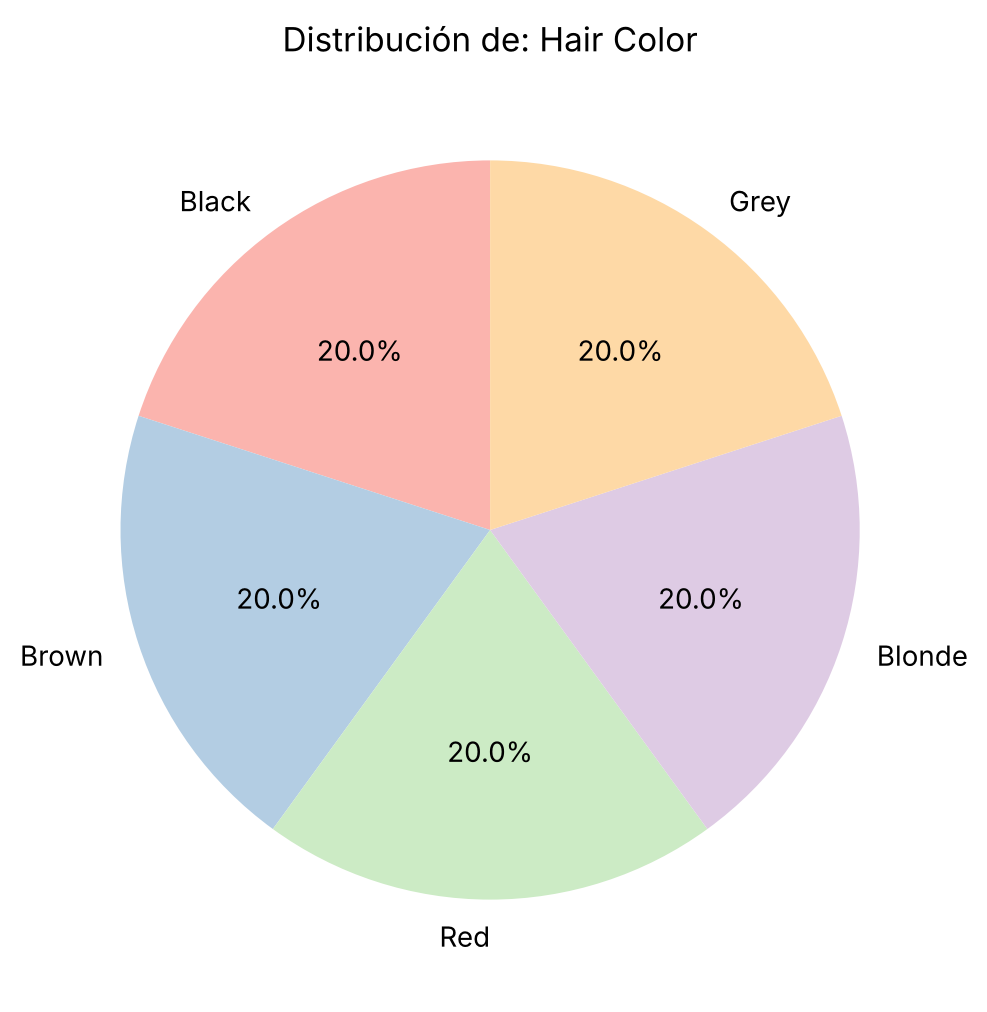

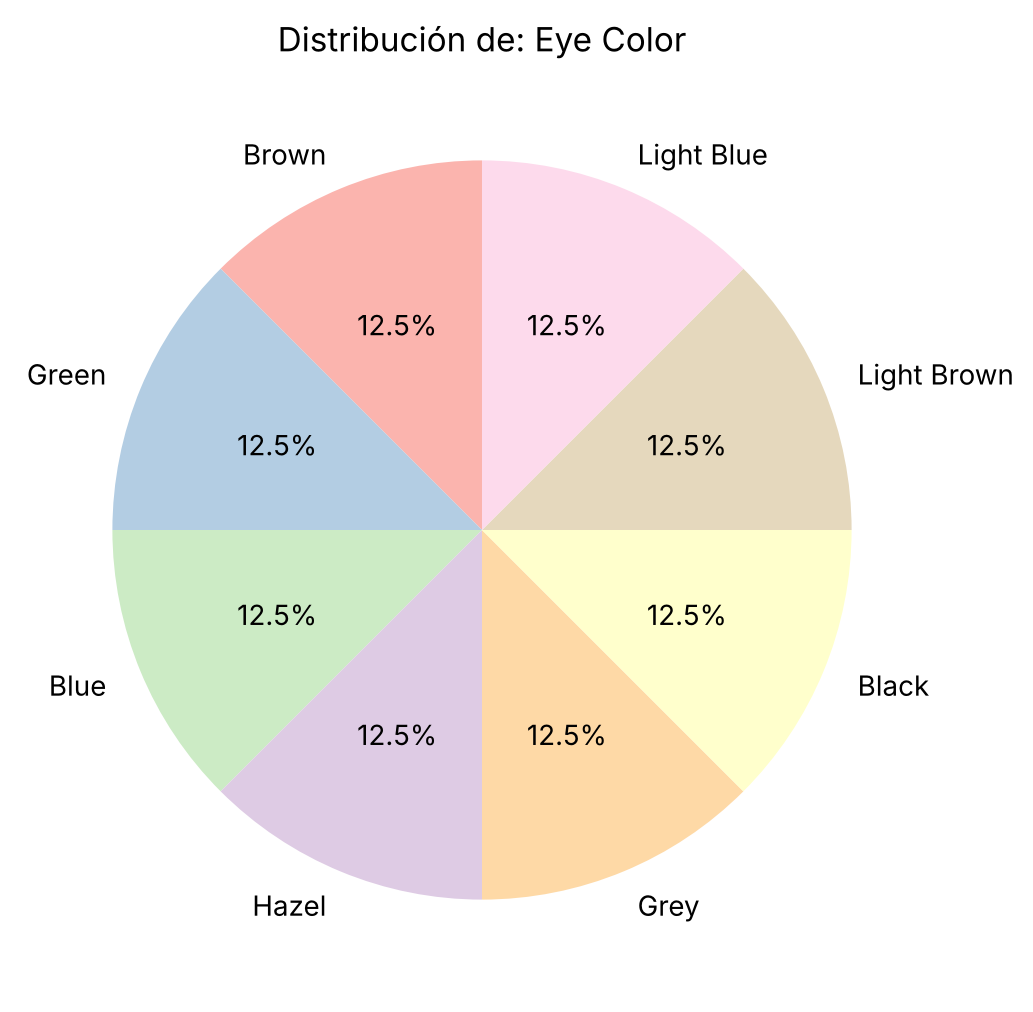

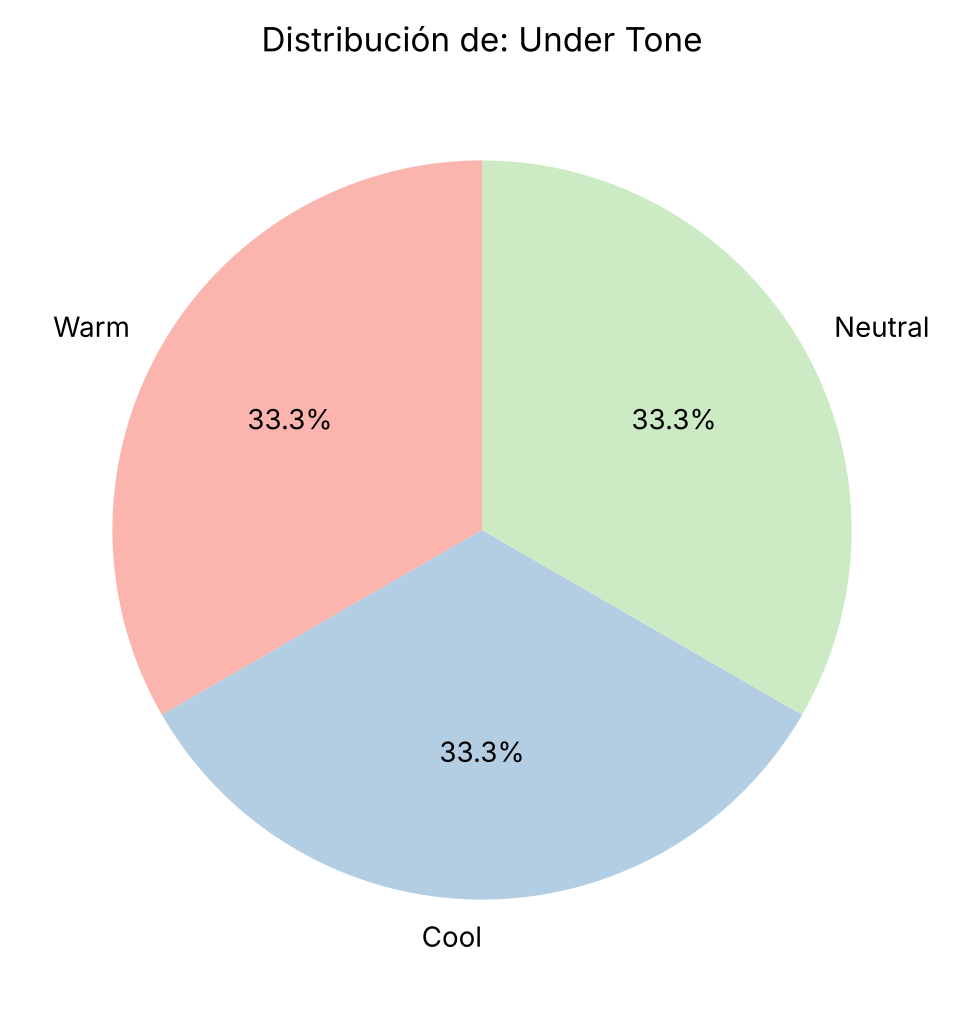

In [7]:
print("--- Gráficas de Pastel (Pie) ---")
# Elegimos 3 columnas representativas para no llenar la pantalla con 18 gráficos
columnas_pastel = ['Hair Color', 'Eye Color', 'Under Tone']

for col in columnas_pastel:
    plt.figure(figsize=(6, 6))
    conteo = df[col].value_counts()

    # Creamos el pie chart
    plt.pie(conteo, labels=conteo.index, autopct='%1.1f%%', startangle=90,
            colors=plt.cm.Pastel1.colors)
    plt.title(f'Distribución de: {col}')
    plt.ylabel('')
    plt.show()

--- Gráficas de Líneas (Plot) ---


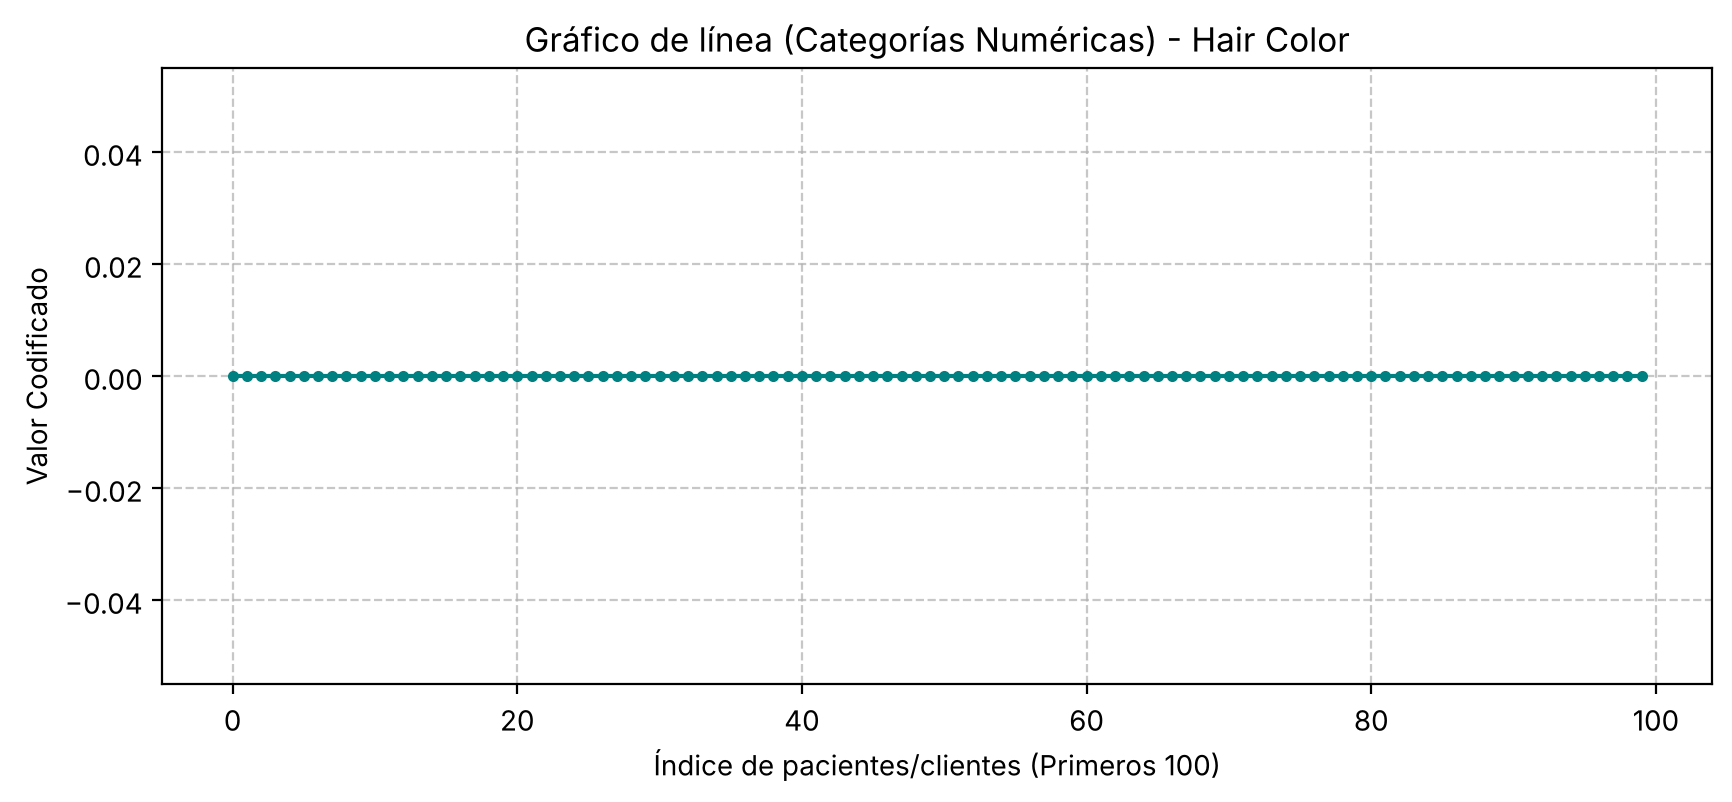

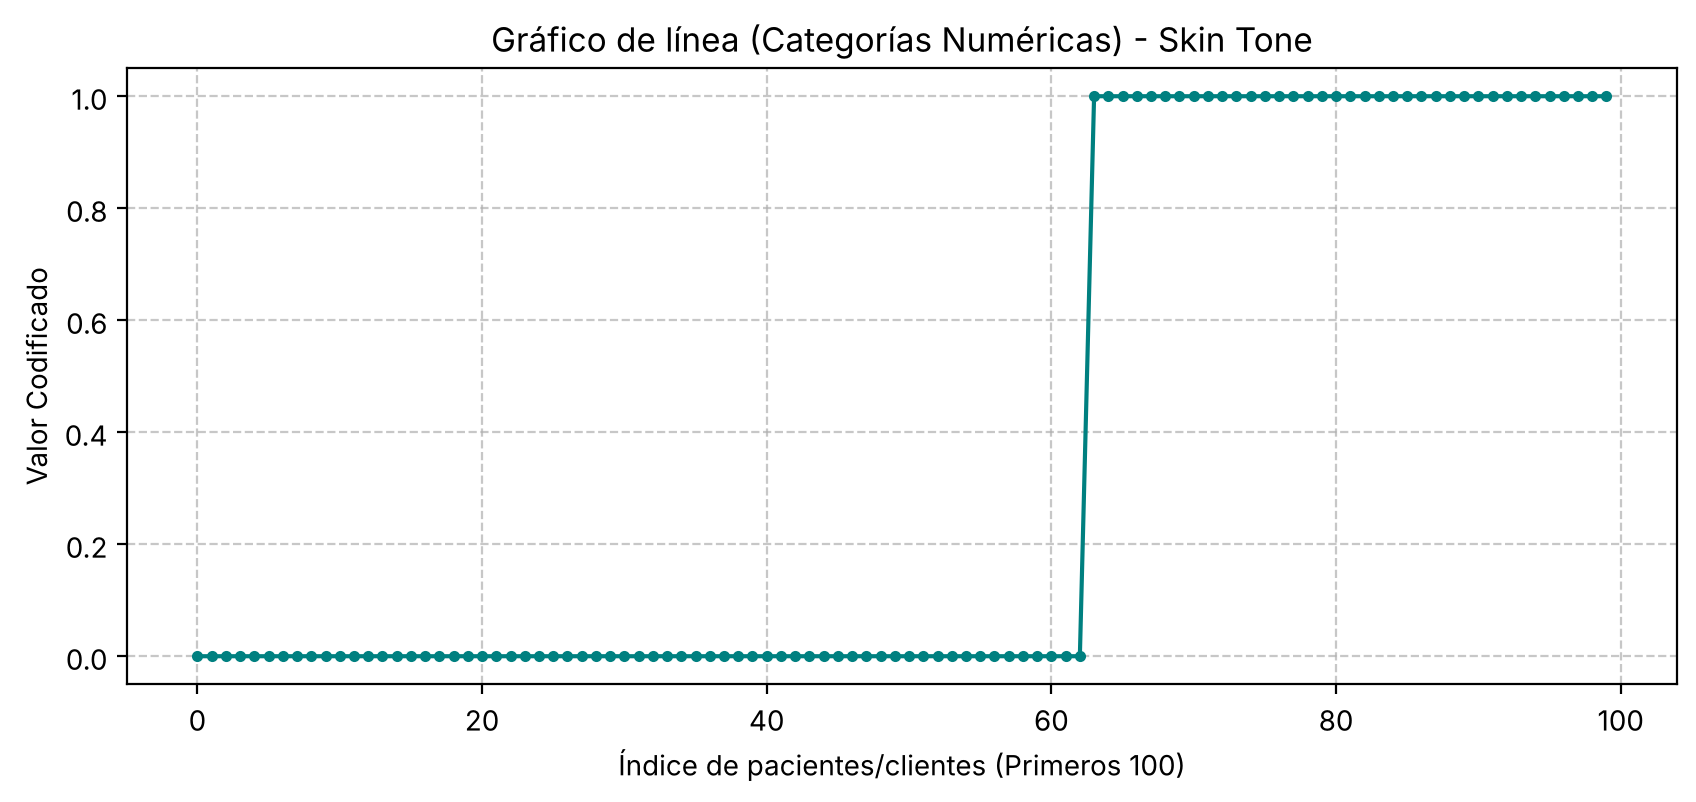

In [8]:
print("--- Gráficas de Líneas (Plot) ---")
# Elegimos un par de columnas para graficar
columnas_plot = ['Hair Color', 'Skin Tone']

# ATENCIÓN: El dataset tiene 15,000 filas, si graficamos todo, se veria como una mancha
# Graficamos solo los primeros 100 registros para que se vean los picos de manera más legible.
filas_a_graficar = 100

for col in columnas_plot:
    plt.figure(figsize=(10, 4))
    # Graficamos la columna ya convertida a números
    df_numerico[col].head(filas_a_graficar).plot(kind='line', color='teal', linewidth=1.5, marker='o', markersize=3)

    plt.title(f'Gráfico de línea (Categorías Numéricas) - {col}')
    plt.xlabel('Índice de pacientes/clientes (Primeros 100)')
    plt.ylabel('Valor Codificado')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.show()

## **Segunda entrega**

## Limpieza del dataset
***1. Identificar los datos nulos***



In [9]:
# Cantidad de datos nulos por columna
print(df.isnull().sum())

# Total de datos nulos
print("\nTotal de datos nulos:", df.isnull().sum().sum())

# Porcentaje de nulos por columna
porcentaje_nulos = (df.isnull().sum() / len(df)) * 100
print("\nPorcentaje de nulos:")
print(porcentaje_nulos)


Hair Color                                 0
Eye Color                                  0
Skin Tone                                  0
Under Tone                                 0
Torso length                               0
Body Proportion                            0
Recommended Clothing Colors                0
Avoid Clothing Colors                      0
Recommended Fitting Style                  0
Recommended Materials                      0
Recommended Patterns                       0
Recommended Jewelry Metal                  0
Recommended Shoes                          0
Recommended Clothing Color Wheel Region    0
Avoid Clothing Color Wheel Region          0
Fabric Nature                              0
Don't Exaggerate                           0
Do Exaggerate                              0
dtype: int64

Total de datos nulos: 0

Porcentaje de nulos:
Hair Color                                 0.0
Eye Color                                  0.0
Skin Tone                           

***2. Busqueda de datos vacíos y espacios innecesarios***

In [10]:
vacios = df.apply(
    lambda columna: columna.astype(str).str.strip().eq("").sum()
)

print("Celdas vacías por columna:")
print(vacios)

print("\nTotal de celdas vacías:", vacios.sum())

# Eliminar espacios al principio y al final de los textos
for columna in df.select_dtypes(include="object").columns:
    df[columna] = df[columna].str.strip()

# Convertir cadenas vacías en valores nulos
df = df.replace(r"^\s*$", pd.NA, regex=True)

print("\nNulos después de limpiar:")
print(df.isnull().sum().sum())

Celdas vacías por columna:
Hair Color                                 0
Eye Color                                  0
Skin Tone                                  0
Under Tone                                 0
Torso length                               0
Body Proportion                            0
Recommended Clothing Colors                0
Avoid Clothing Colors                      0
Recommended Fitting Style                  0
Recommended Materials                      0
Recommended Patterns                       0
Recommended Jewelry Metal                  0
Recommended Shoes                          0
Recommended Clothing Color Wheel Region    0
Avoid Clothing Color Wheel Region          0
Fabric Nature                              0
Don't Exaggerate                           0
Do Exaggerate                              0
dtype: int64

Total de celdas vacías: 0



Nulos después de limpiar:
0


/tmp/ipykernel_13811/1257505366.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for columna in df.select_dtypes(include="object").columns:


***3. Identificar registros duplicados***

In [11]:
# Contar registros duplicados
duplicados = df.duplicated().sum()

print("Cantidad de filas duplicadas:", duplicados)

# Eliminar duplicados si existen
df = df.drop_duplicates()

print("Dimensiones después de revisar duplicados:", df.shape)


Cantidad de filas duplicadas: 0
Dimensiones después de revisar duplicados: (15120, 18)


**Dataset después de la limpieza:**

In [12]:
print("Filas finales:", df.shape[0])
print("Columnas finales:", df.shape[1])
print("Total de valores nulos:", df.isnull().sum().sum())
print("Total de filas duplicadas:", df.duplicated().sum())

print("\nTipos de datos:")
print(df.dtypes)

Filas finales: 15120
Columnas finales: 18
Total de valores nulos: 0
Total de filas duplicadas: 0

Tipos de datos:
Hair Color                                 str
Eye Color                                  str
Skin Tone                                  str
Under Tone                                 str
Torso length                               str
Body Proportion                            str
Recommended Clothing Colors                str
Avoid Clothing Colors                      str
Recommended Fitting Style                  str
Recommended Materials                      str
Recommended Patterns                       str
Recommended Jewelry Metal                  str
Recommended Shoes                          str
Recommended Clothing Color Wheel Region    str
Avoid Clothing Color Wheel Region          str
Fabric Nature                              str
Don't Exaggerate                           str
Do Exaggerate                              str
dtype: object


## **Particionado Sugerido: 80/20**

In [13]:
from sklearn.model_selection import train_test_split

# Dividir el dataset en 80% entrenamiento y 20% prueba
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

# Mostrar resultados
print("Dataset original:", df.shape)
print("Datos de entrenamiento:", train_df.shape)
print("Datos de prueba:", test_df.shape)

# Comprobar los porcentajes
print(f"\nPorcentaje de entrenamiento: {len(train_df)/len(df)*100:.2f}%")
print(f"Porcentaje de prueba: {len(test_df)/len(df)*100:.2f}%")

Dataset original: (15120, 18)
Datos de entrenamiento: (12096, 18)
Datos de prueba: (3024, 18)

Porcentaje de entrenamiento: 80.00%
Porcentaje de prueba: 20.00%


## **USO DE ESTIMADORES**

In [14]:
# Cargar librerías
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, learning_curve, validation_curve,
                                     cross_validate, StratifiedKFold)
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             silhouette_score, adjusted_rand_score)
from sklearn.exceptions import ConvergenceWarning
from scipy.optimize import linear_sum_assignment

warnings.filterwarnings("ignore", category=ConvergenceWarning)

I0000 00:00:1795148840.147576   13811 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795148840.181210   13811 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1795148841.203416   13811 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


### ***0. Corrección: variable objetivo y fuga de datos***

**Qué estaba mal.** En la versión anterior el modelo recibía 17 columnas como entrada, y 11 de ellas eran *otras recomendaciones* (colores a evitar, qué no exagerar, región en la rueda de color, materiales, calzado…). Todas salen de la misma tabla de reglas que la variable que se quería predecir, así que el modelo no aprendía nada: copiaba. Por eso todos los modelos daban exactamente 100 %. A eso se le llama **fuga de datos** (*data leakage*).

**Ejemplo de la vida real:** es como pedirle a alguien que adivine la respuesta de la pregunta 5 de un examen y entregarle la hoja de respuestas de la pregunta 6, que dice lo mismo. Acierta siempre, pero no sabe nada.

**Qué se hace ahora**

| Rol | Columnas |
|---|---|
| **Entradas** (rasgos de color que la persona declara o la app estima) | Hair Color, Eye Color, Skin Tone, **Under Tone** |
| **Salida a predecir** | Recommended Clothing Colors (3 clases) |
| **Se eliminan** | Las otras 11 columnas de recomendación, incluidas las de "no recomendar": Avoid Clothing Colors, Avoid Clothing Color Wheel Region y Don't Exaggerate |
| **No se usan** | Torso length y Body Proportion: son rasgos del cuerpo y solo determinan calzado, corte y telas, no el color (se comprueba abajo) |

El subtono (**Under Tone**) se queda como entrada porque es el dato clave del proyecto: la app lo estima (por ejemplo desde la cámara) y de él salen los colores. Las demás columnas de recomendación no existen todavía cuando llega una persona nueva, así que el modelo no puede depender de ellas.

In [15]:
PERSONA = ['Hair Color', 'Eye Color', 'Skin Tone', 'Under Tone', 'Torso length', 'Body Proportion']   # las 6 columnas que describen a la persona
ENTRADAS = ['Hair Color', 'Eye Color', 'Skin Tone', 'Under Tone']                                      # las 4 de COLOR: las que usa el modelo
TARGET = 'Recommended Clothing Colors'
NO_RECOMENDAR = ['Avoid Clothing Colors', 'Avoid Clothing Color Wheel Region', "Don't Exaggerate"]
SALIDAS = [c for c in df.columns if c not in PERSONA]           # las 12 columnas de recomendación

print("Entradas (4):", ENTRADAS)
print("No se usan  :", [c for c in PERSONA if c not in ENTRADAS])
print("Objetivo    :", TARGET)
print("Se eliminan (11):", [c for c in SALIDAS if c != TARGET])

# ¿Qué entrada determina cada columna de salida? (si con un solo valor de la entrada la salida
# siempre es la misma, la salida es una simple "tabla de búsqueda" de esa entrada)
filas = []
for col in SALIDAS:
    determinan = [e for e in PERSONA if df.groupby(e)[col].nunique().max() == 1]
    filas.append({'Columna de salida': col,
                  'Valores distintos': df[col].nunique(),
                  'La determina por sí sola': ', '.join(determinan) if determinan else '—'})
pd.DataFrame(filas)

Entradas (4): ['Hair Color', 'Eye Color', 'Skin Tone', 'Under Tone']
No se usan  : ['Torso length', 'Body Proportion']
Objetivo    : Recommended Clothing Colors
Se eliminan (11): ['Avoid Clothing Colors', 'Recommended Fitting Style', 'Recommended Materials', 'Recommended Patterns', 'Recommended Jewelry Metal', 'Recommended Shoes', 'Recommended Clothing Color Wheel Region', 'Avoid Clothing Color Wheel Region', 'Fabric Nature', "Don't Exaggerate", 'Do Exaggerate']


,Columna de salida,Valores distintos,La determina por sí sola
0,Recommended Clothing Colors,3,Under Tone
1,Avoid Clothing Colors,3,Under Tone
2,Recommended Fitting Style,7,Body Proportion
3,Recommended Materials,7,Body Proportion
4,Recommended Patterns,7,Body Proportion
5,Recommended Jewelry Metal,3,Under Tone
6,Recommended Shoes,3,Torso length
7,Recommended Clothing Color Wheel Region,3,Under Tone
8,Avoid Clothing Color Wheel Region,2,Under Tone
9,Fabric Nature,6,Body Proportion


**Lectura.** Cada columna de salida depende de **una sola** entrada: colores, joyería y región de la rueda de color dependen solo de `Under Tone`; estilo, materiales, patrones y qué exagerar dependen solo de `Body Proportion`; el calzado, solo de `Torso length`. El color de pelo, de ojos y el tono de piel no determinan ninguna. Es decir, las 12 columnas son consecuencias de las características de la persona, no información independiente.

**Por qué solo 4 entradas.** `Torso length` y `Body Proportion` son rasgos del cuerpo: determinan calzado, corte, materiales y patrones, pero **ninguna columna de color**. Como el objetivo es el color de ropa, no aportan información; además, desde una foto de la cara (la cámara de la demo) se pueden estimar el pelo, los ojos, la piel y el subtono, pero no el largo del torso ni la proporción corporal. Por eso el modelo usa solo las 4 variables de color.

In [16]:
# Prueba de fuga: mismo modelo (árbol de decisión), tres conjuntos de columnas de entrada
def acc_arbol(columnas):
    Xa, ya = df[columnas], df[TARGET]
    Xtr_, Xte_, ytr_, yte_ = train_test_split(Xa, ya, test_size=0.2, random_state=42, stratify=ya)
    m = Pipeline([('oh', OneHotEncoder(handle_unknown='ignore')),
                  ('dt', DecisionTreeClassifier(random_state=42))])
    return m.fit(Xtr_, ytr_).score(Xte_, yte_)

todas_menos_target = [c for c in df.columns if c != TARGET]
prueba = pd.DataFrame([
    {'Entradas del modelo': 'Versión anterior: las 17 columnas',
     'Nº columnas': 17, 'Accuracy test': acc_arbol(todas_menos_target),
     '¿Usable con una persona nueva?': 'No: 11 de las 17 columnas no existen todavía'},
    {'Entradas del modelo': 'Quitando solo las de "no recomendar"',
     'Nº columnas': 14, 'Accuracy test': acc_arbol([c for c in todas_menos_target if c not in NO_RECOMENDAR]),
     '¿Usable con una persona nueva?': 'No: quedan 8 columnas de recomendación'},
    {'Entradas del modelo': 'Versión corregida: 4 entradas de color',
     'Nº columnas': 4, 'Accuracy test': acc_arbol(ENTRADAS),
     '¿Usable con una persona nueva?': 'Sí'},
])
prueba

,Entradas del modelo,Nº columnas,Accuracy test,¿Usable con una persona nueva?
0,Versión anterior: las 17 columnas,17,1.0,No: 11 de las 17 columnas no existen todavía
1,"Quitando solo las de ""no recomendar""",14,1.0,No: quedan 8 columnas de recomendación
2,Versión corregida: 4 entradas de color,4,1.0,Sí


**Por qué la exactitud sola no delata la fuga.** Las tres versiones sacan 100 %, y eso es justamente el problema: con la fuga el resultado "se ve" perfecto aunque el modelo no se pueda usar. Quitar únicamente las columnas de "no recomendar" no basta, porque las demás columnas de recomendación (joyería, región de la rueda, etc.) también contienen la respuesta. La diferencia real es que la versión corregida solo usa datos que existen cuando llega una persona nueva a la app.

### ***1. Preparación de los datos***

- **Partición 80/20 estratificada** (`random_state=42`): cada clase aparece en la misma proporción en entrenamiento y prueba.
- **Codificación One-Hot** de las 4 entradas: cada categoría pasa a ser una columna 0/1. Se usa en lugar de numerar las categorías (0, 1, 2…) porque colores de pelo u ojos no tienen un orden; numerarlos le inventaría al modelo que "Black < Brown < Red". El codificador se ajusta **solo con train** para no filtrar información del test.
- **Perfiles únicos.** Con solo 4 entradas hay 5 × 8 × 6 × 3 = **720 perfiles distintos**. Las 15.120 filas del archivo repiten cada perfil 21 veces, una por cada combinación de torso y proporción, que ya no se usan. Si se dejaran, el mismo perfil caería a la vez en train y en test y la evaluación sería trampa; por eso se conserva **una fila por perfil**.
- La variable objetivo se convierte a números (0, 1, 2) y cada clase se nombra con el subtono al que corresponde (Warm, Cool, Neutral) para que las gráficas sean legibles.

In [17]:
# Una fila por perfil de color (las filas repetidas solo difieren en torso/proporción, que no se usan)
filas_antes = len(df)
df = df.drop_duplicates(subset=ENTRADAS + [TARGET]).reset_index(drop=True)
assert len(df) == len(df[ENTRADAS].drop_duplicates()), "un mismo perfil tendría dos etiquetas"
print(f"Filas: {filas_antes} -> {len(df)} perfiles únicos (cada perfil tiene una sola etiqueta)")

X = df[ENTRADAS].copy()
le = LabelEncoder()
y = le.fit_transform(df[TARGET])

# Nombre corto de cada clase = subtono al que corresponde esa paleta de colores
NOMBRES = [df.loc[df[TARGET] == c, 'Under Tone'].mode()[0] for c in le.classes_]
print("Clases:", dict(enumerate(NOMBRES)))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

preprocessor = ColumnTransformer(
    [('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ENTRADAS)])

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Registros por clase en test:", np.bincount(y_test))

Filas: 15120 -> 720 perfiles únicos (cada perfil tiene una sola etiqueta)
Clases: {0: 'Warm', 1: 'Cool', 2: 'Neutral'}
Train: (576, 4) | Test: (144, 4)
Registros por clase en test: [48 48 48]


### ***1. Decision Tree***

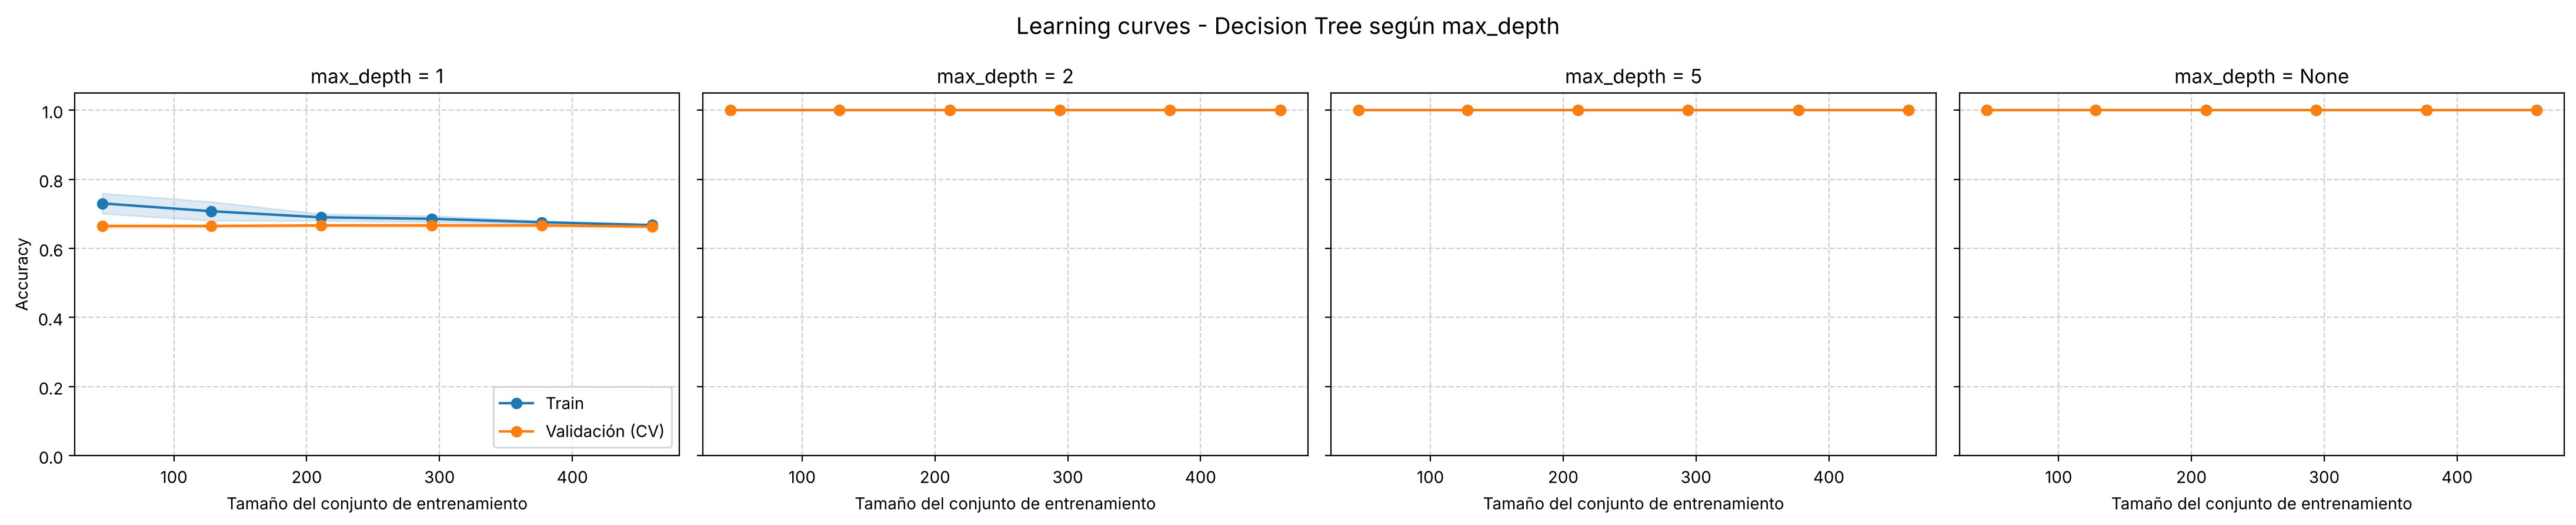

,Modelo,Train,Validación,Brecha
0,max_depth = 1,0.6678,0.6632,0.0046
1,max_depth = 2,1.0000,1.0000,0.0000
2,max_depth = 5,1.0000,1.0000,0.0000
3,max_depth = None,1.0000,1.0000,0.0000


In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
tamanos = np.linspace(0.1, 1.0, 6)

def curvas(modelos, titulo):
    """modelos: dict {etiqueta: pipeline}. Dibuja una curva de aprendizaje por modelo (solo con train)."""
    n = len(modelos)
    fig, axes = plt.subplots(1, n, figsize=(5.5 * n, 4.5), sharey=True)
    axes = np.atleast_1d(axes)
    resumen = []
    for ax, (nombre, modelo) in zip(axes, modelos.items()):
        sizes, tr, va = learning_curve(modelo, X_train, y_train, cv=cv, train_sizes=tamanos,
                                       scoring='accuracy', n_jobs=-1)
        tr_m, tr_s = tr.mean(axis=1), tr.std(axis=1)
        va_m, va_s = va.mean(axis=1), va.std(axis=1)
        ax.plot(sizes, tr_m, 'o-', color='tab:blue', label='Train')
        ax.fill_between(sizes, tr_m - tr_s, tr_m + tr_s, color='tab:blue', alpha=0.15)
        ax.plot(sizes, va_m, 'o-', color='tab:orange', label='Validación (CV)')
        ax.fill_between(sizes, va_m - va_s, va_m + va_s, color='tab:orange', alpha=0.15)
        ax.set_title(nombre)
        ax.set_xlabel('Tamaño del conjunto de entrenamiento')
        ax.set_ylim(0, 1.05)
        ax.grid(True, linestyle='--', alpha=0.6)
        resumen.append({'Modelo': nombre, 'Train': tr_m[-1], 'Validación': va_m[-1],
                        'Brecha': tr_m[-1] - va_m[-1]})
    axes[0].set_ylabel('Accuracy')
    axes[0].legend(loc='lower right')
    fig.suptitle(titulo, fontsize=14)
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(resumen).round(4)

modelos_dt = {f"max_depth = {p}": Pipeline([('pre', preprocessor),
                                            ('clf', DecisionTreeClassifier(max_depth=p, random_state=42))])
              for p in [1, 2, 5, None]}
res_dt = curvas(modelos_dt, "Learning curves - Decision Tree según max_depth")
res_dt

Con `max_depth = 1` el árbol hace una sola pregunta y solo puede separar una clase del resto, por eso se queda corto (*underfitting*). Con `max_depth = 2` ya puede hacer dos preguntas seguidas sobre el subtono y llega al 100 %; más profundidad no aporta nada porque no hay nada más que aprender.

### ***2. Random Forest***

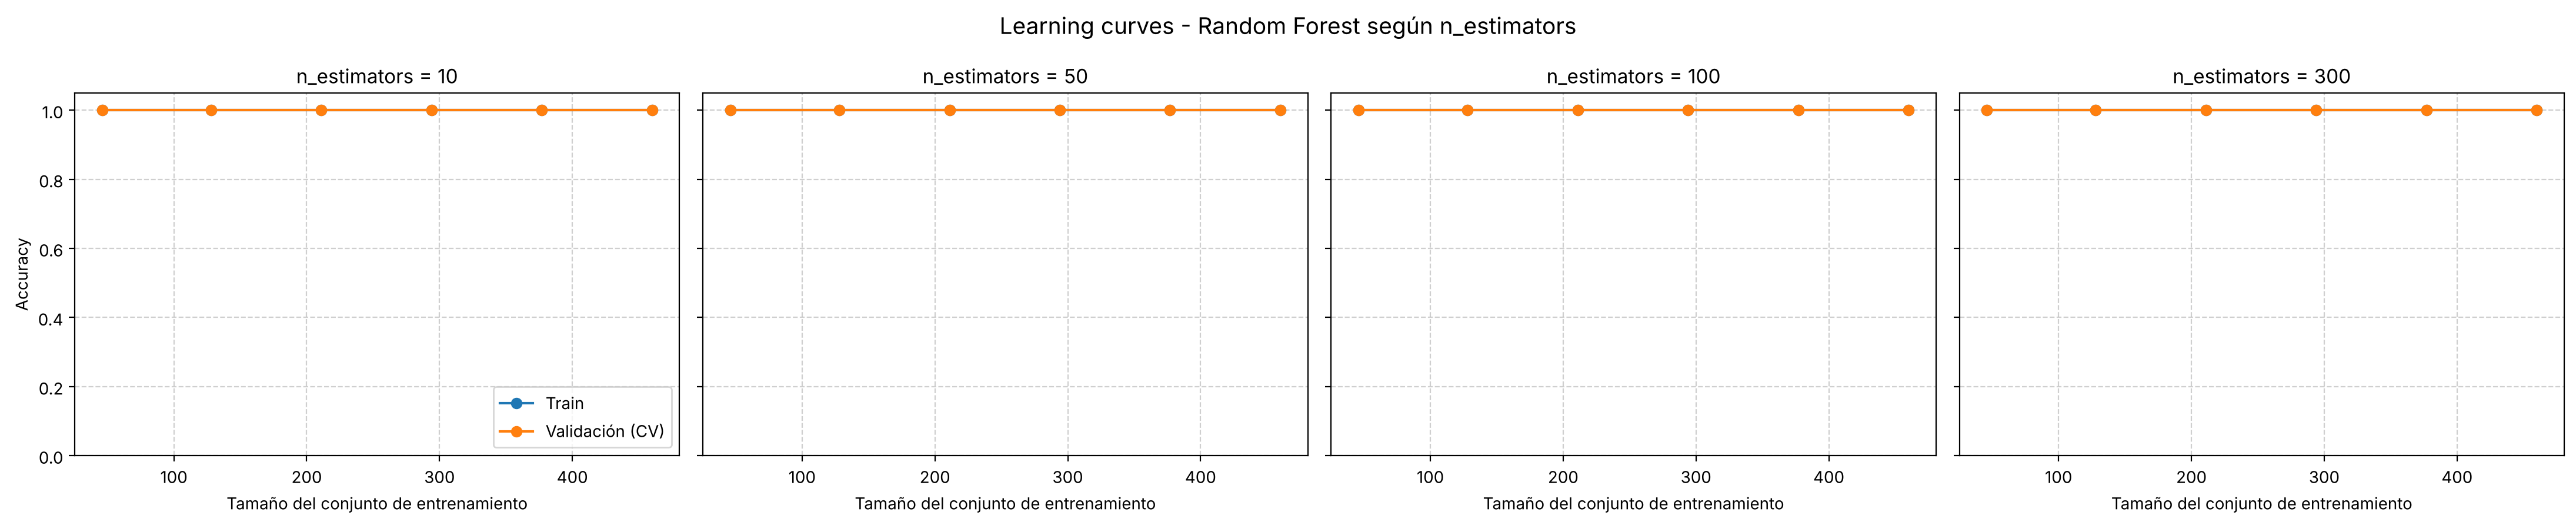

,Modelo,Train,Validación,Brecha
0,n_estimators = 10,1.0,1.0,0.0
1,n_estimators = 50,1.0,1.0,0.0
2,n_estimators = 100,1.0,1.0,0.0
3,n_estimators = 300,1.0,1.0,0.0


In [19]:
valores_n = [10, 50, 100, 300]
modelos_rf = {f"n_estimators = {n}": Pipeline([('pre', preprocessor),
                                               ('clf', RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1))])
              for n in valores_n}
res_rf = curvas(modelos_rf, "Learning curves - Random Forest según n_estimators")
res_rf

### ***3. SVM***

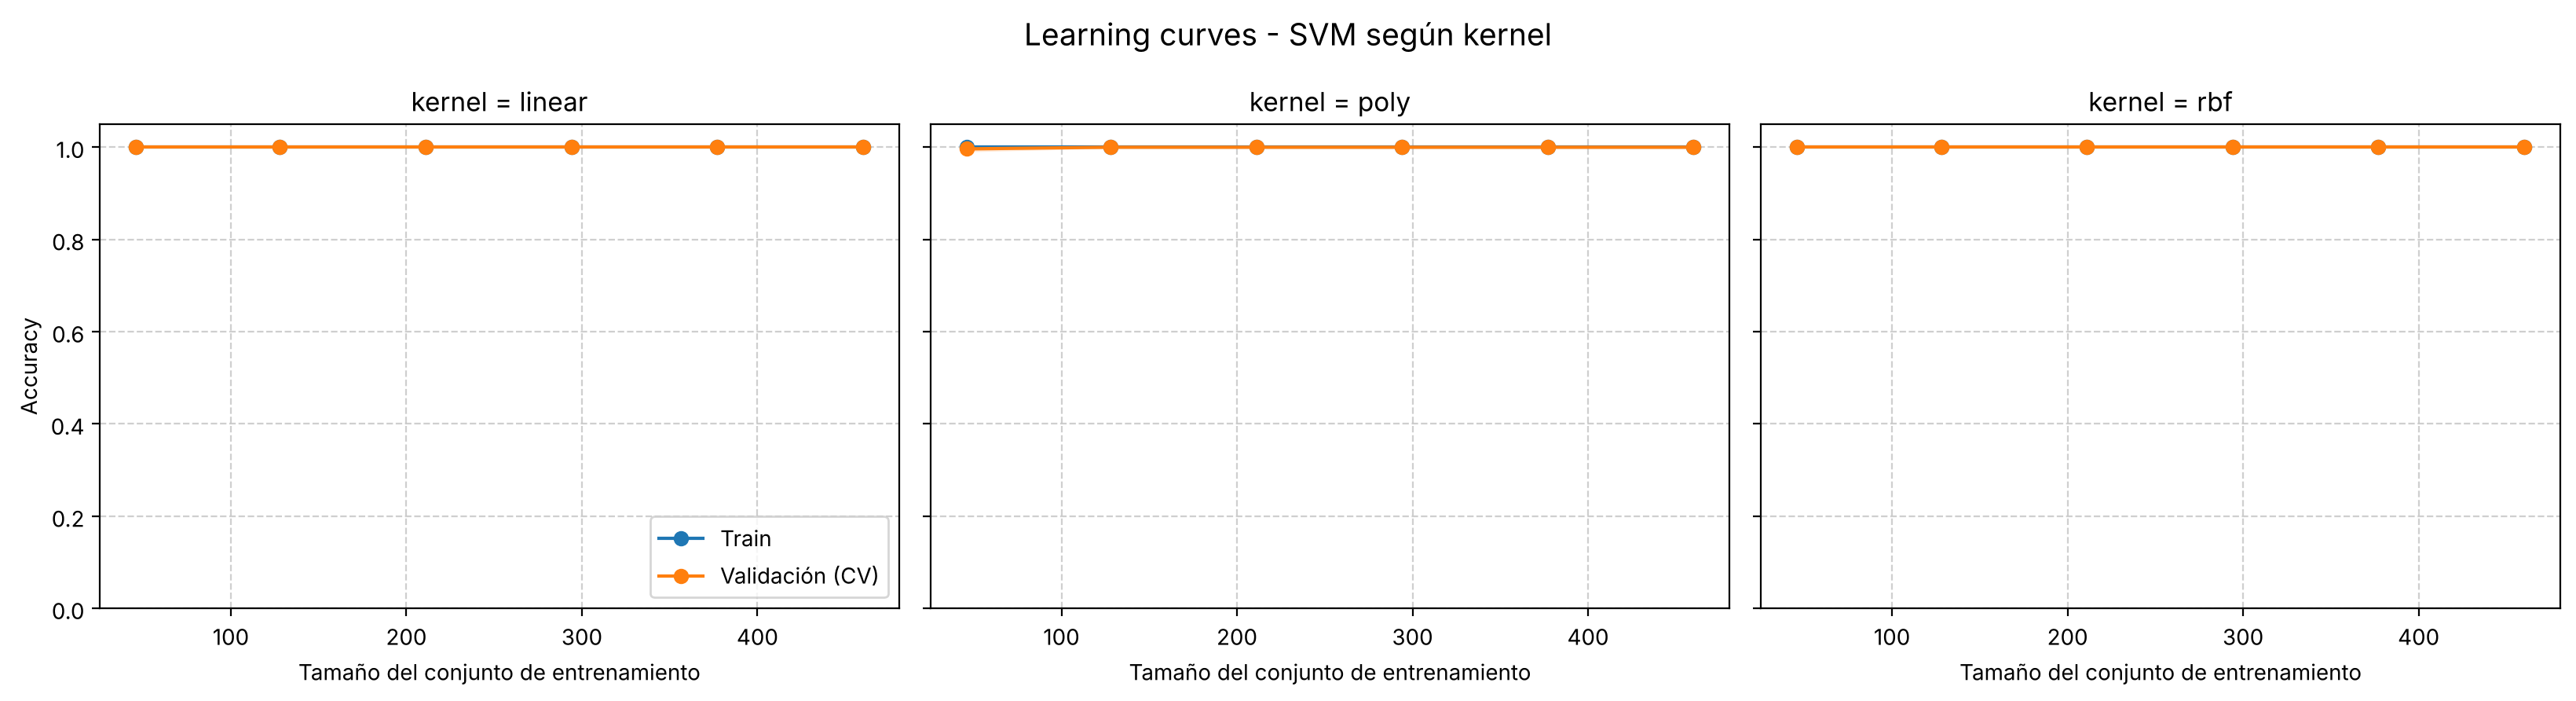

,Modelo,Train,Validación,Brecha
0,kernel = linear,1.0,1.0,0.0
1,kernel = poly,1.0,1.0,0.0
2,kernel = rbf,1.0,1.0,0.0


In [20]:
modelos_svm = {f"kernel = {k}": Pipeline([('pre', preprocessor),
                                          ('clf', SVC(kernel=k, random_state=42))])
               for k in ['linear', 'poly', 'rbf']}
res_svm = curvas(modelos_svm, "Learning curves - SVM según kernel")
res_svm

In [21]:
comparacion = pd.concat([res_dt, res_rf, res_svm], ignore_index=True).sort_values('Validación', ascending=False)
comparacion

,Modelo,Train,Validación,Brecha
1,max_depth = 2,1.0000,1.0000,0.0000
2,max_depth = 5,1.0000,1.0000,0.0000
3,max_depth = None,1.0000,1.0000,0.0000
7,n_estimators = 300,1.0000,1.0000,0.0000
4,n_estimators = 10,1.0000,1.0000,0.0000
5,n_estimators = 50,1.0000,1.0000,0.0000
6,n_estimators = 100,1.0000,1.0000,0.0000
9,kernel = poly,1.0000,1.0000,0.0000
8,kernel = linear,1.0000,1.0000,0.0000
10,kernel = rbf,1.0000,1.0000,0.0000


### ***4. ¿Qué modelo da más exactitud? Comparación y selección***

Se comparan 7 modelos más una **línea base** (adivinar al azar respetando las proporciones de cada clase, que da ≈ 33 % con 3 clases). Todos se evalúan con validación cruzada de 5 particiones **solo sobre train**, y el test se mira una única vez al final.

**Regla de selección:** se escoge el modelo con la mayor exactitud en validación cruzada; si varios empatan (diferencia menor a 0,001), gana el más simple y fácil de explicar. La exactitud mide qué tan bien acierta, pero entre modelos que aciertan lo mismo no hay razón para pagar más complejidad.

,CV accuracy,CV desv.,Train accuracy,Test accuracy,Tiempo de ajuste (s)
Modelo,,,,,
DT,1.0000,0.0000,1.0000,1.0000,0.0044
RF,1.0000,0.0000,1.0000,1.0000,0.1497
SVM (rbf),1.0000,0.0000,1.0000,1.0000,0.0184
KNN (k=5),1.0000,0.0000,1.0000,1.0000,0.0043
Gradient Boosting,1.0000,0.0000,1.0000,1.0000,0.1745
Regresión logística,1.0000,0.0000,1.0000,1.0000,0.0064
MLP (sklearn),1.0000,0.0000,1.0000,1.0000,0.1485
Baseline (azar),0.3611,0.0387,0.3099,0.2431,0.0041



Mejor exactitud en CV: 1.0000
Modelos empatados en la cima: ['DT', 'RF', 'SVM (rbf)', 'KNN (k=5)', 'Gradient Boosting', 'Regresión logística', 'MLP (sklearn)']
Modelo elegido (el más simple entre los empatados): DT


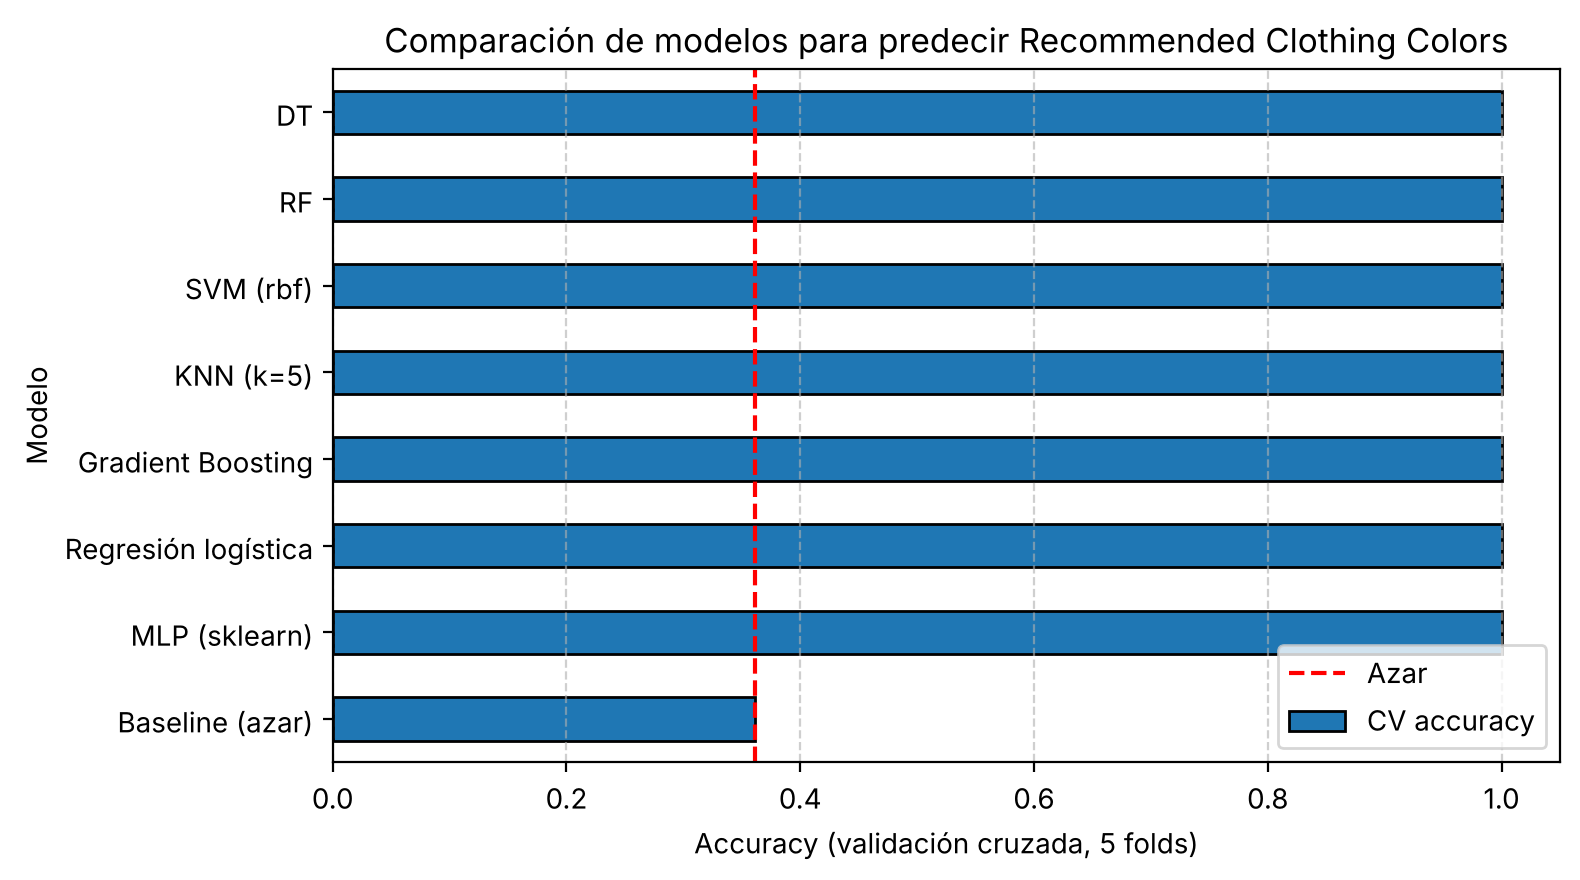

In [22]:
candidatos = {
    'Baseline (azar)':     DummyClassifier(strategy='stratified', random_state=42),
    'DT':                  DecisionTreeClassifier(random_state=42),
    'RF':                  RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'SVM (rbf)':           SVC(kernel='rbf', random_state=42),
    'KNN (k=5)':           KNeighborsClassifier(n_neighbors=5),
    'Regresión logística': LogisticRegression(max_iter=1000),
    'Gradient Boosting':   GradientBoostingClassifier(random_state=42),
    'MLP (sklearn)':       MLPClassifier(hidden_layer_sizes=(64,), max_iter=200, random_state=42),
}
# De más simple a más complejo (se usa solo para desempatar)
ORDEN_SIMPLICIDAD = ['DT', 'Regresión logística', 'KNN (k=5)', 'RF',
                     'Gradient Boosting', 'SVM (rbf)', 'MLP (sklearn)']

filas = []
for nombre, clf in candidatos.items():
    pipe = Pipeline([('pre', clone(preprocessor)), ('clf', clone(clf))])
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring='accuracy', return_train_score=True)
    pipe.fit(X_train, y_train)
    filas.append({'Modelo': nombre,
                  'CV accuracy': r['test_score'].mean(),
                  'CV desv.': r['test_score'].std(),
                  'Train accuracy': r['train_score'].mean(),
                  'Test accuracy': pipe.score(X_test, y_test),
                  'Tiempo de ajuste (s)': r['fit_time'].mean()})
tabla_modelos = (pd.DataFrame(filas).set_index('Modelo')
                 .sort_values('CV accuracy', ascending=False).round(4))
display(tabla_modelos)

mejor_cv = tabla_modelos['CV accuracy'].max()
finalistas = [m for m in tabla_modelos.index
              if tabla_modelos.loc[m, 'CV accuracy'] >= mejor_cv - 0.001 and m != 'Baseline (azar)']
elegido = min(finalistas, key=ORDEN_SIMPLICIDAD.index)
print(f"\nMejor exactitud en CV: {mejor_cv:.4f}")
print("Modelos empatados en la cima:", finalistas)
print("Modelo elegido (el más simple entre los empatados):", elegido)

ax = tabla_modelos['CV accuracy'].plot(kind='barh', figsize=(8, 4.5), color='tab:blue', edgecolor='black')
ax.axvline(tabla_modelos.loc['Baseline (azar)', 'CV accuracy'], color='red', linestyle='--', label='Azar')
ax.set_xlabel('Accuracy (validación cruzada, 5 folds)'); ax.set_xlim(0, 1.05)
ax.invert_yaxis(); ax.legend(); ax.grid(True, axis='x', linestyle='--', alpha=0.6)
plt.title('Comparación de modelos para predecir Recommended Clothing Colors')
plt.tight_layout(); plt.show()

**Lectura.** Todos los modelos de verdad llegan al 100 % y se separan claramente de la línea base (~33 %). Que todos empaten no es mérito del modelo: el problema es una **regla exacta** (a cada subtono le corresponde una paleta) y cualquier modelo que la encuentre acierta siempre. Por eso se desempata por simplicidad y no por décimas de exactitud.

### ***5. Entrenamiento y evaluación del modelo elegido***

El modelo elegido se entrena con todo el conjunto de train y se evalúa **una sola vez** con el test. Además se revisa *qué aprendió*: la importancia de cada variable muestra si el modelo realmente usa el subtono.

Modelo: DT
Accuracy en test: 1.0000

              precision    recall  f1-score   support

        Warm       1.00      1.00      1.00        48
        Cool       1.00      1.00      1.00        48
     Neutral       1.00      1.00      1.00        48

    accuracy                           1.00       144
   macro avg       1.00      1.00      1.00       144
weighted avg       1.00      1.00      1.00       144



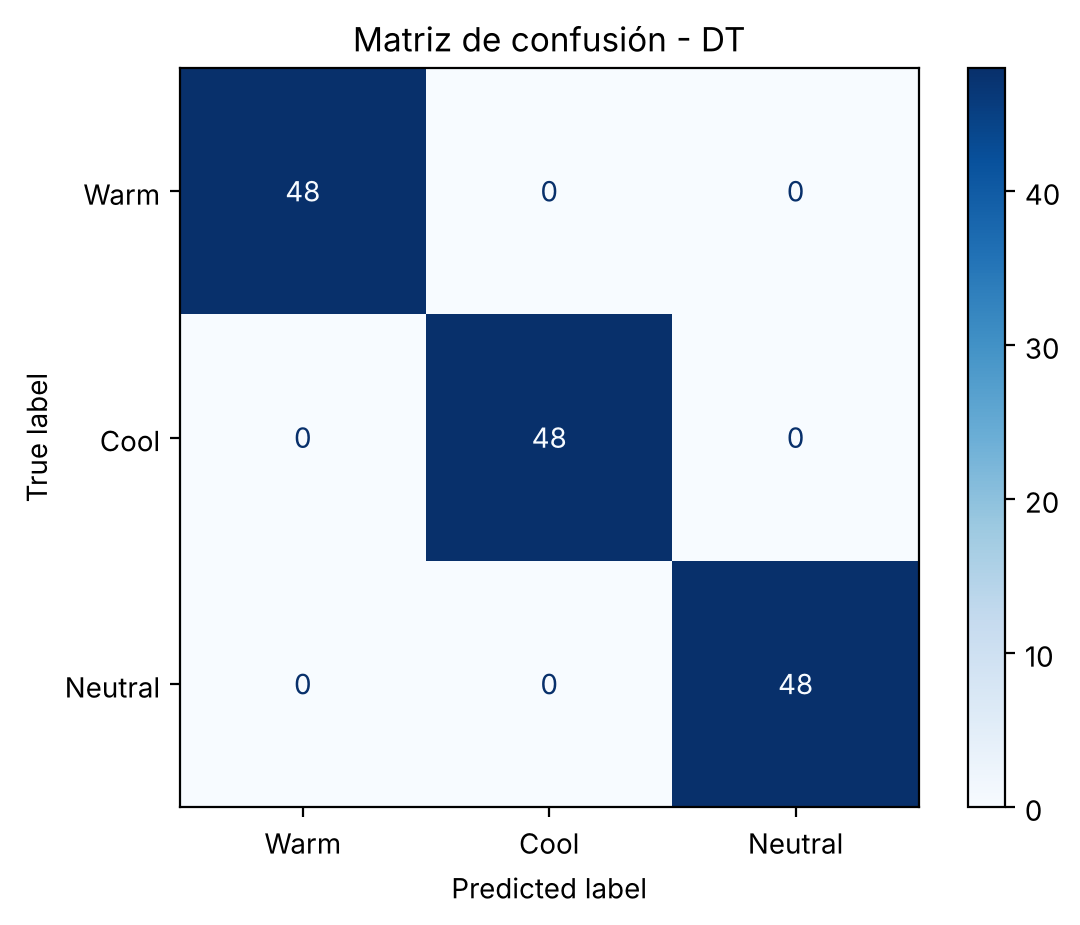

In [23]:
modelo_final = Pipeline([('pre', clone(preprocessor)), ('clf', clone(candidatos[elegido]))])
modelo_final.fit(X_train, y_train)
y_pred = modelo_final.predict(X_test)

print(f"Modelo: {elegido}")
print(f"Accuracy en test: {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, target_names=NOMBRES, zero_division=0))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=NOMBRES).plot(cmap='Blues')
plt.title(f'Matriz de confusión - {elegido}')
plt.show()

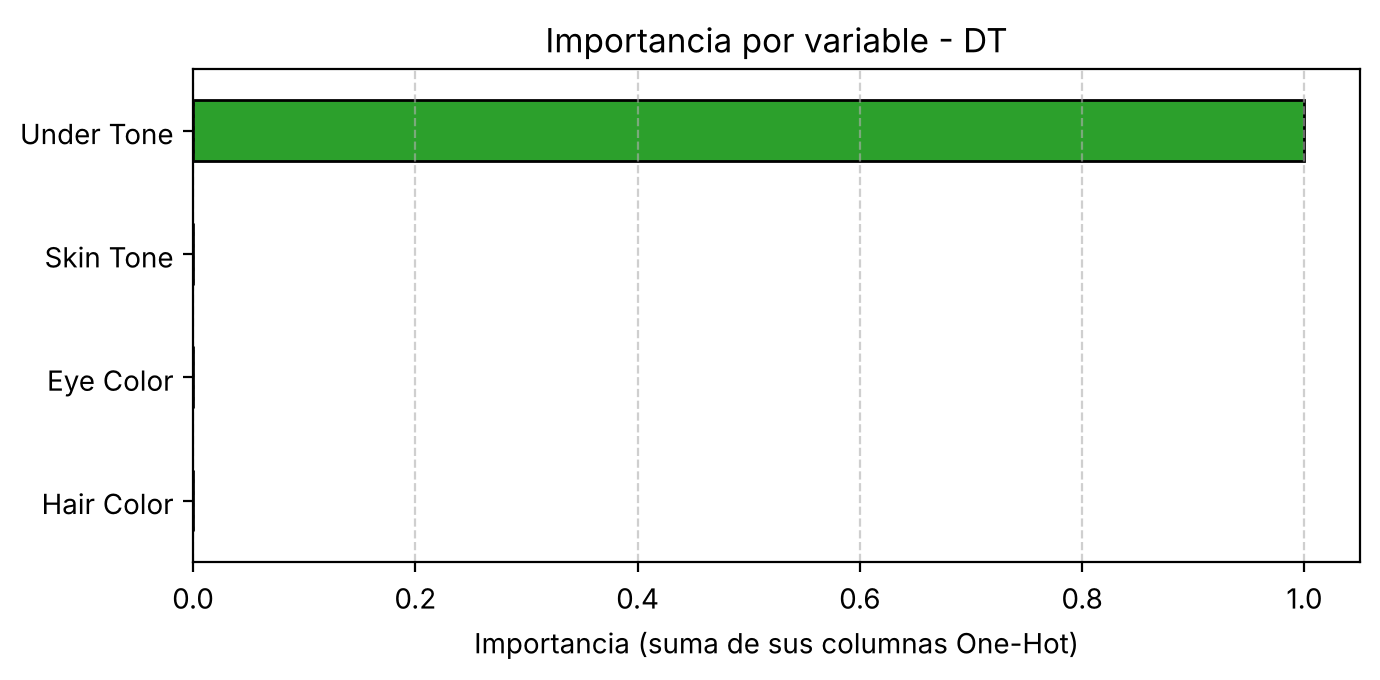

Under Tone    1.0
Hair Color    0.0
Eye Color     0.0
Skin Tone     0.0
dtype: float64


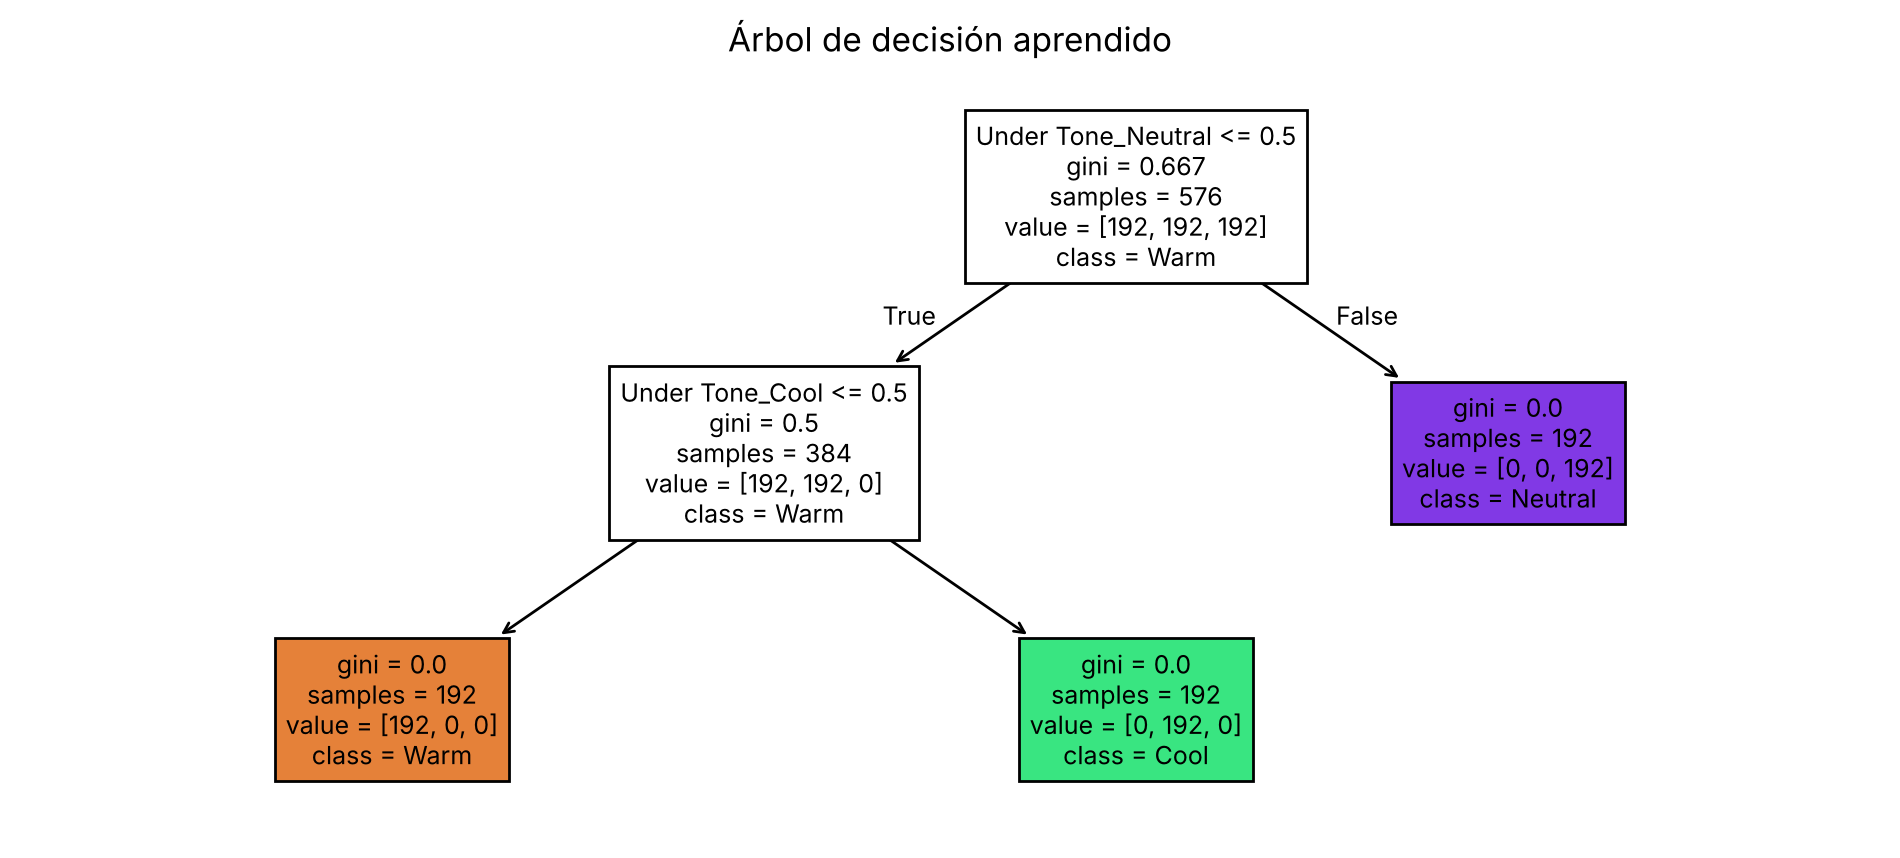

In [24]:
# ¿En qué variables se apoya el modelo?
clf_f = modelo_final.named_steps['clf']
if hasattr(clf_f, 'feature_importances_'):
    nombres_cols = modelo_final.named_steps['pre'].get_feature_names_out()
    por_variable = {e: 0.0 for e in ENTRADAS}
    for n, v in zip(nombres_cols, clf_f.feature_importances_):
        n = n.split('__', 1)[1]
        for e in ENTRADAS:
            if n.startswith(e + '_'):
                por_variable[e] += v
    imp = pd.Series(por_variable).sort_values()
    ax = imp.plot(kind='barh', figsize=(7, 3.5), color='tab:green', edgecolor='black')
    ax.set_xlabel('Importancia (suma de sus columnas One-Hot)')
    ax.set_title(f'Importancia por variable - {elegido}')
    ax.grid(True, axis='x', linestyle='--', alpha=0.6)
    plt.tight_layout(); plt.show()
    print(imp.sort_values(ascending=False).round(4))

if isinstance(clf_f, DecisionTreeClassifier):
    plt.figure(figsize=(12, 5))
    plot_tree(clf_f, feature_names=[n.split('__', 1)[1] for n in nombres_cols],
              class_names=NOMBRES, filled=True, fontsize=9, max_depth=3)
    plt.title('Árbol de decisión aprendido')
    plt.show()

### ***6. ¿Qué pasa si se quita el subtono? (prueba de que es la variable clave)***

Se repite el entrenamiento **sin** `Under Tone`. Como `Recommended Clothing Colors` equivale 1 a 1 al subtono, esta prueba responde dos preguntas a la vez: *¿el subtono es la variable que importa?* y *¿se puede deducir el subtono a partir del pelo, los ojos y la piel?*

In [25]:
SIN_SUBTONO = [c for c in ENTRADAS if c != 'Under Tone']
pre_sin = ColumnTransformer([('oh', OneHotEncoder(handle_unknown='ignore'), SIN_SUBTONO)])

pruebas = {
    'Baseline (azar)':      DummyClassifier(strategy='stratified', random_state=42),
    'Regresión logística':  LogisticRegression(max_iter=1000),
    'DT (profundidad 3)':   DecisionTreeClassifier(max_depth=3, random_state=42),
    'DT (sin límite)':      DecisionTreeClassifier(random_state=42),
    'RF':                   RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
}
filas = []
for nombre, clf in pruebas.items():
    con = Pipeline([('pre', clone(preprocessor)), ('clf', clone(clf))]).fit(X_train, y_train)
    sin = Pipeline([('pre', clone(pre_sin)), ('clf', clone(clf))]).fit(X_train[SIN_SUBTONO], y_train)
    filas.append({'Modelo': nombre,
                  'Test CON subtono': con.score(X_test, y_test),
                  'Test SIN subtono': sin.score(X_test[SIN_SUBTONO], y_test),
                  'Train SIN subtono': sin.score(X_train[SIN_SUBTONO], y_train)})
ablacion = pd.DataFrame(filas).set_index('Modelo').round(4)
ablacion

,Test CON subtono,Test SIN subtono,Train SIN subtono
Modelo,,,
Baseline (azar),0.2431,0.2431,0.3021
Regresión logística,1.0000,0.2014,0.3663
DT (profundidad 3),1.0000,0.2153,0.3628
DT (sin límite),1.0000,0.0278,0.4097
RF,1.0000,0.0278,0.4097


**Lectura.**

1. **El subtono es la única variable que importa.** Con él los modelos aciertan el 100 %; sin él caen al nivel del azar o por debajo: alrededor de 20 % con la regresión logística y el árbol limitado (con 3 clases, el azar puro daría ≈ 33 %; el test es pequeño, 144 perfiles, por eso oscila) y apenas ≈ 3 % con los modelos que memorizan.
2. **Los modelos que memorizan caen muy *por debajo* del azar.** El dataset contiene todas las combinaciones posibles de las características, así que cada combinación de pelo + ojos + piel aparece **exactamente tres veces, una por cada subtono**. Si dos de esas tres filas están en train, la que queda en test siempre tiene el tercer subtono, y un modelo que memorizó train predice uno de los otros dos. Es una trampa de este dataset, no un error del modelo.
3. **Conclusión para ArmonIA:** con pelo, ojos y piel no se puede deducir el subtono. Hay que obtenerlo de otra fuente (por ejemplo, estimarlo desde una foto con la cámara) y luego aplicar la regla que el modelo aprendió.

###***CrossValidation***

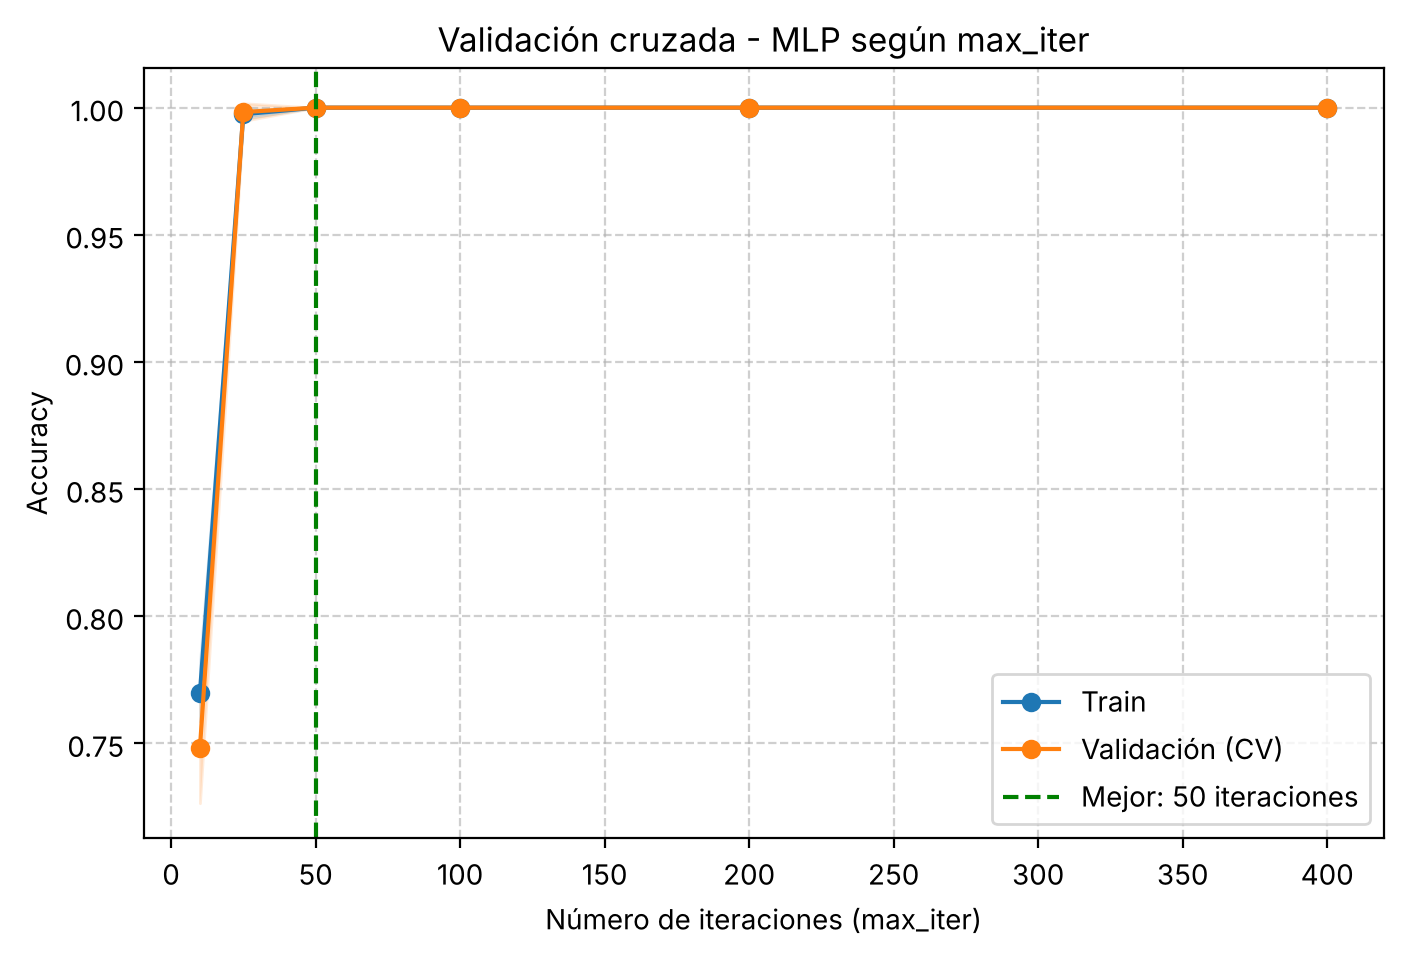

Mejor número de iteraciones: 50 (accuracy CV = 1.0000)


,max_iter,Train,Validación,Brecha
0,10,0.7700,0.7482,0.0217
1,25,0.9974,0.9983,-0.0009
2,50,1.0000,1.0000,0.0000
3,100,1.0000,1.0000,0.0000
4,200,1.0000,1.0000,0.0000
5,400,1.0000,1.0000,0.0000


In [26]:
iteraciones = [10, 25, 50, 100, 200, 400]

modelo = make_pipeline(clone(preprocessor),
                       MLPClassifier(hidden_layer_sizes=(64,), random_state=42))

tr, va = validation_curve(modelo, X_train, y_train,
                          param_name="mlpclassifier__max_iter",
                          param_range=iteraciones,
                          cv=cv, scoring="accuracy", n_jobs=-1)

tr_m, tr_s = tr.mean(axis=1), tr.std(axis=1)
va_m, va_s = va.mean(axis=1), va.std(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(iteraciones, tr_m, 'o-', color='tab:blue', label='Train')
plt.fill_between(iteraciones, tr_m - tr_s, tr_m + tr_s, color='tab:blue', alpha=0.15)
plt.plot(iteraciones, va_m, 'o-', color='tab:orange', label='Validación (CV)')
plt.fill_between(iteraciones, va_m - va_s, va_m + va_s, color='tab:orange', alpha=0.15)

mejor = int(np.argmax(va_m))
plt.axvline(iteraciones[mejor], color='green', linestyle='--',
            label=f'Mejor: {iteraciones[mejor]} iteraciones')
plt.xlabel('Número de iteraciones (max_iter)')
plt.ylabel('Accuracy')
plt.title('Validación cruzada - MLP según max_iter')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

tabla_iter = pd.DataFrame({'max_iter': iteraciones, 'Train': tr_m,
                           'Validación': va_m, 'Brecha': tr_m - va_m}).round(4)
print(f"Mejor número de iteraciones: {iteraciones[mejor]} "
      f"(accuracy CV = {va_m[mejor]:.4f})")
tabla_iter

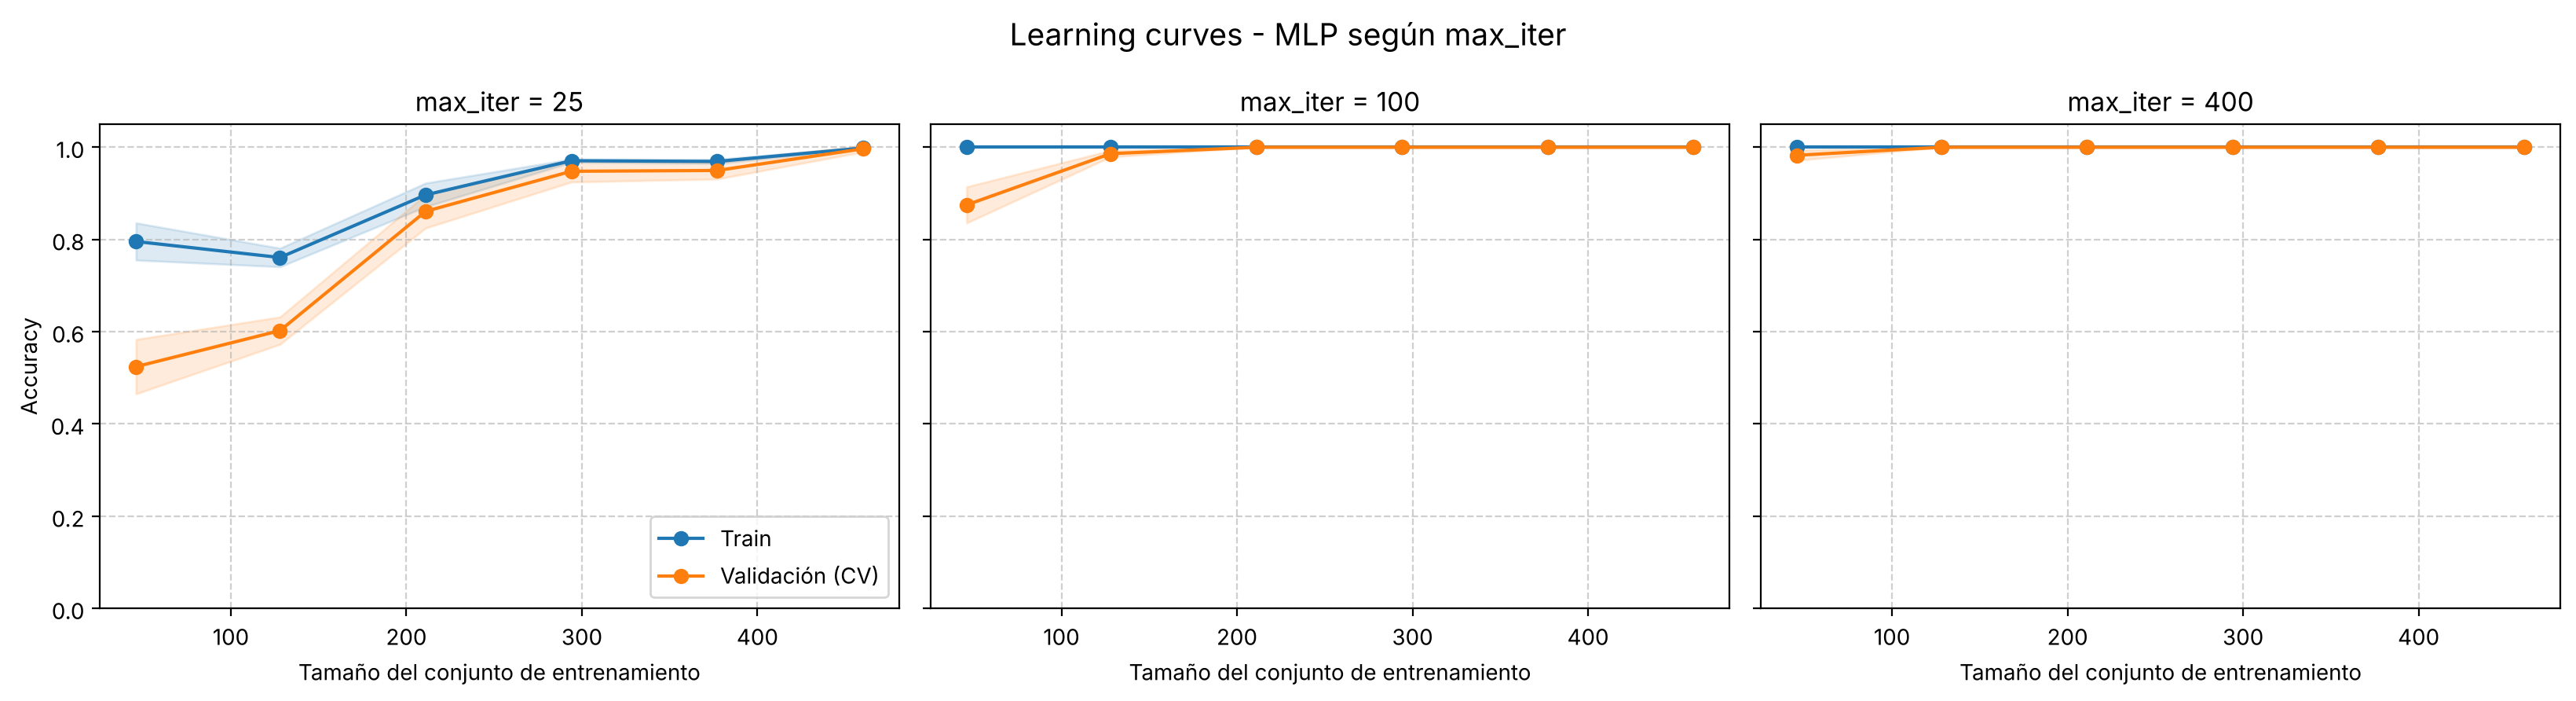

,Modelo,Train,Validación,Brecha
0,max_iter = 25,0.9983,0.9965,0.0017
1,max_iter = 100,1.0000,1.0000,0.0000
2,max_iter = 400,1.0000,1.0000,0.0000


In [27]:
modelos_iter = {f"max_iter = {m}": Pipeline([('pre', preprocessor),
                                             ('clf', MLPClassifier(hidden_layer_sizes=(64,), max_iter=m, random_state=42))])
                for m in [25, 100, 400]}
res_iter = curvas(modelos_iter, "Learning curves - MLP según max_iter")
res_iter

# **Deep Learning: Perceptrón multicapa (MLP)**
En esta sección se implementan redes neuronales artificiales de tipo perceptrón multicapa para resolver el problema de clasificación del proyecto ArmonIA (predecir `Recommended Clothing Colors` a partir de las 4 entradas).

Se compararán tres arquitecturas con diferente número de capas ocultas y neuronas. La entrada son las 22 columnas One-Hot (ya están en el rango 0-1, por lo que no necesitan escalado adicional) y la salida son 3 neuronas con *softmax* (una por clase).

In [28]:
tf.random.set_seed(42)
np.random.seed(42)

X_train_oh = preprocessor.fit_transform(X_train).astype('float32')   # el codificador se ajusta solo con train
X_test_oh = preprocessor.transform(X_test).astype('float32')

n_features = X_train_oh.shape[1]
n_clases = len(NOMBRES)
print("Entradas:", n_features, "| Clases de salida:", n_clases)

Entradas: 22 | Clases de salida: 3


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,691 (104.26 KB)

 Trainable params: 26,691 (104.26 KB)

 Non-trainable params: 0 (0.00 B)

Épocas ejecutadas (EarlyStopping): 100


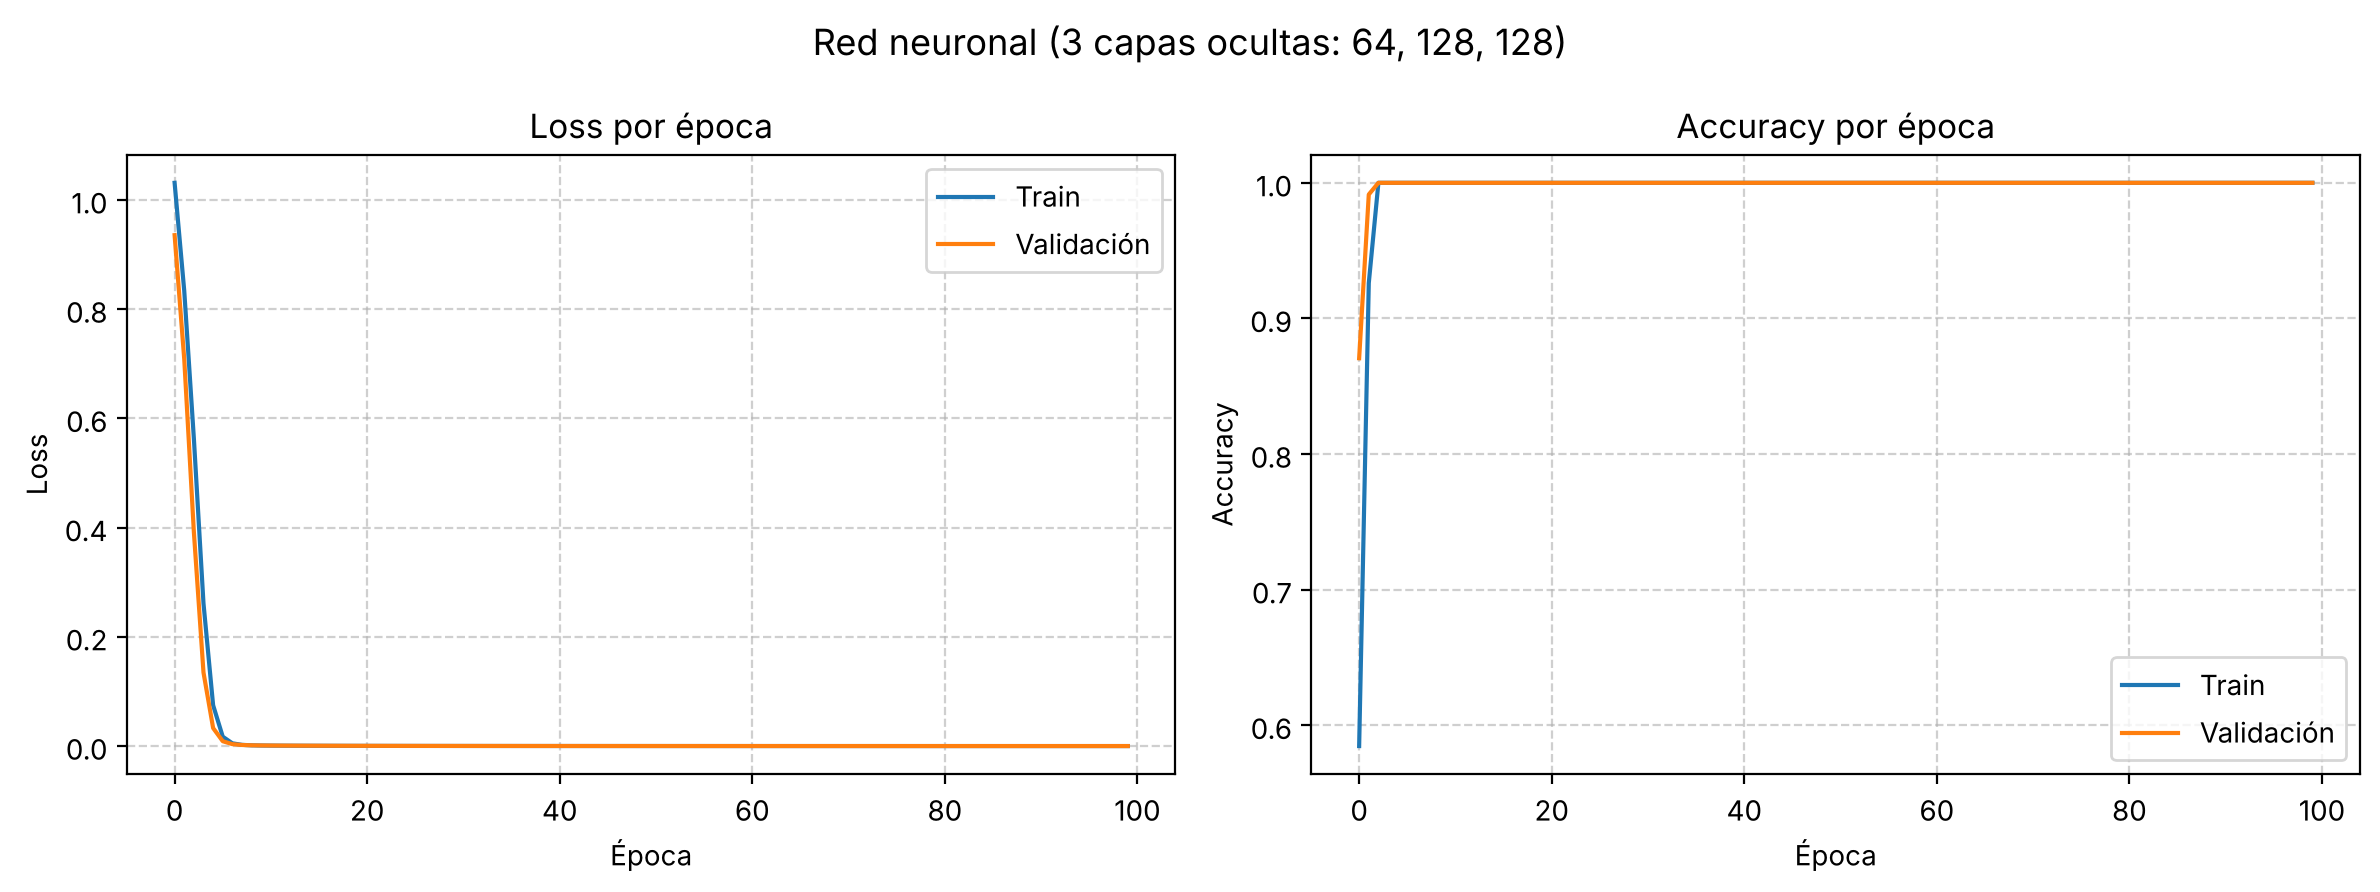


Test -> loss: 0.0000 | accuracy: 1.0000
              precision    recall  f1-score   support

        Warm       1.00      1.00      1.00        48
        Cool       1.00      1.00      1.00        48
     Neutral       1.00      1.00      1.00        48

    accuracy                           1.00       144
   macro avg       1.00      1.00      1.00       144
weighted avg       1.00      1.00      1.00       144



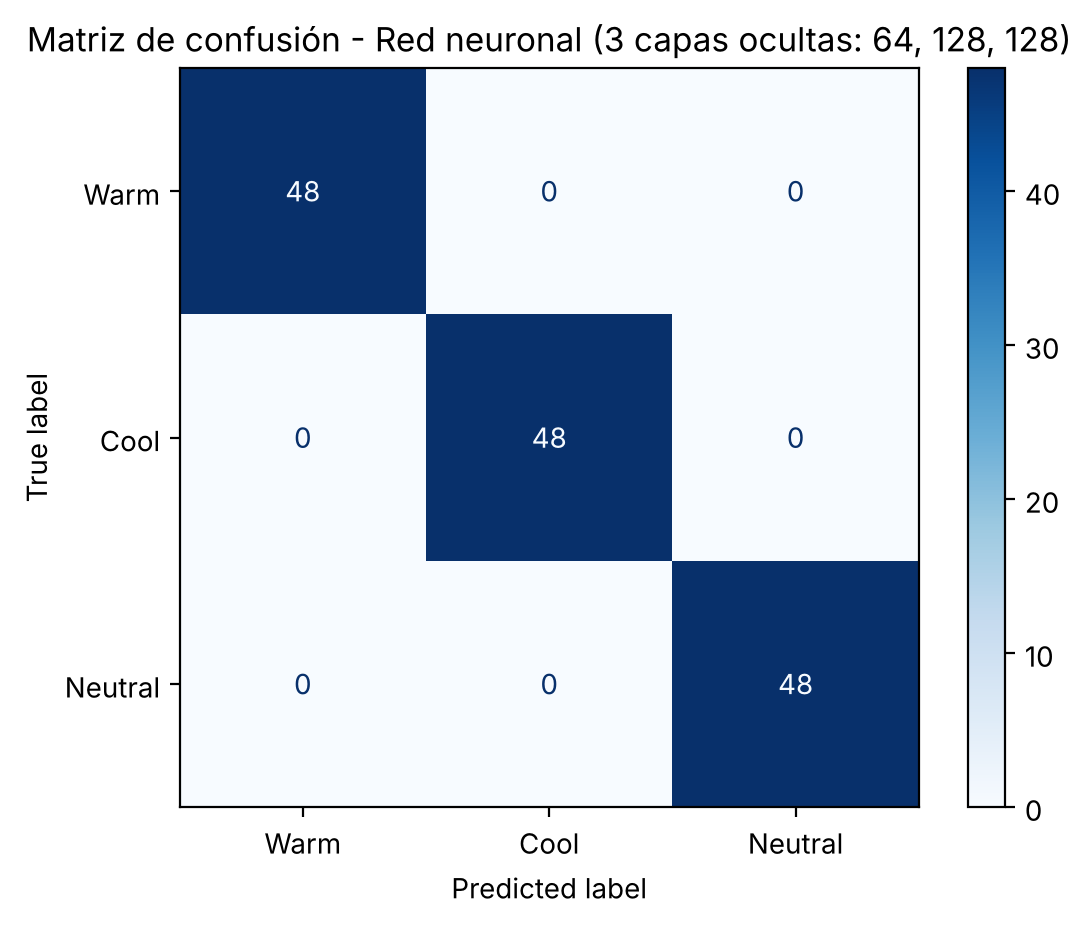

In [29]:
def construir_modelo(capas_ocultas):
    modelo = keras.Sequential(
        [layers.Input(shape=(n_features,))] +                              # Input
        [layers.Dense(n, activation='relu') for n in capas_ocultas] +      # Ocultas
        [layers.Dense(n_clases, activation='softmax')]                     # Output
    )
    modelo.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return modelo

def entrenar_y_evaluar(capas, titulo):
    tf.random.set_seed(42); np.random.seed(42); keras.backend.clear_session()
    modelo = construir_modelo(capas)
    modelo.summary()

    early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    historia = modelo.fit(X_train_oh, y_train, validation_split=0.2,
                          epochs=100, batch_size=64, callbacks=[early_stop], verbose=0)
    print(f"Épocas ejecutadas (EarlyStopping): {len(historia.history['loss'])}")

    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ax[0].plot(historia.history['loss'], label='Train')
    ax[0].plot(historia.history['val_loss'], label='Validación')
    ax[0].set_title('Loss por época'); ax[0].set_xlabel('Época'); ax[0].set_ylabel('Loss')
    ax[1].plot(historia.history['accuracy'], label='Train')
    ax[1].plot(historia.history['val_accuracy'], label='Validación')
    ax[1].set_title('Accuracy por época'); ax[1].set_xlabel('Época'); ax[1].set_ylabel('Accuracy')
    for a in ax:
        a.grid(True, linestyle='--', alpha=0.6); a.legend()
    plt.suptitle(titulo, fontsize=13)
    plt.tight_layout(); plt.show()

    loss, acc = modelo.evaluate(X_test_oh, y_test, verbose=0)
    print(f"\nTest -> loss: {loss:.4f} | accuracy: {acc:.4f}")
    y_p = np.argmax(modelo.predict(X_test_oh, verbose=0), axis=1)
    print(classification_report(y_test, y_p, target_names=NOMBRES, zero_division=0))
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_p), display_labels=NOMBRES).plot(cmap='Blues')
    plt.title(f'Matriz de confusión - {titulo}')
    plt.show()
    return modelo, historia

modelo_nn, historia = entrenar_y_evaluar([64, 128, 128], 'Red neuronal (3 capas ocultas: 64, 128, 128)')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,051 (508.01 KB)

 Trainable params: 130,051 (508.01 KB)

 Non-trainable params: 0 (0.00 B)

Épocas ejecutadas (EarlyStopping): 100


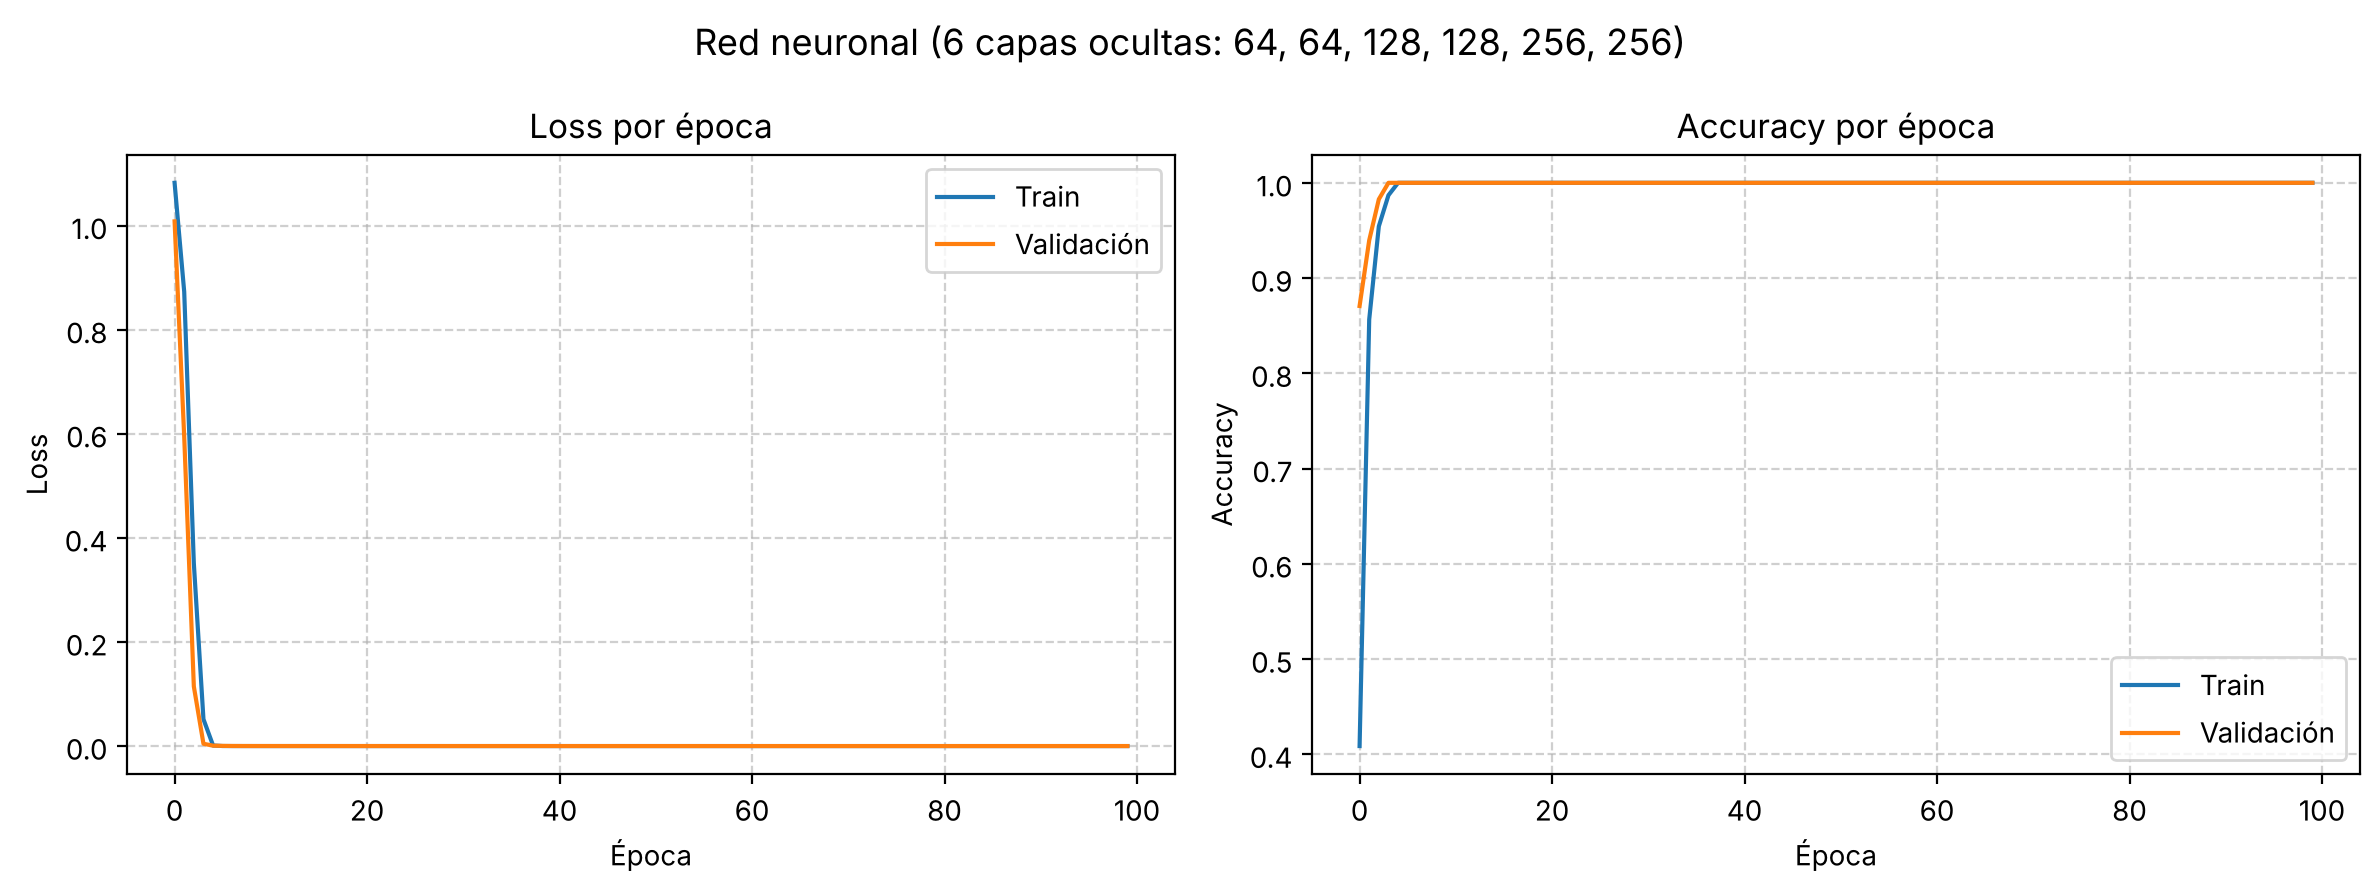


Test -> loss: 0.0000 | accuracy: 1.0000
              precision    recall  f1-score   support

        Warm       1.00      1.00      1.00        48
        Cool       1.00      1.00      1.00        48
     Neutral       1.00      1.00      1.00        48

    accuracy                           1.00       144
   macro avg       1.00      1.00      1.00       144
weighted avg       1.00      1.00      1.00       144



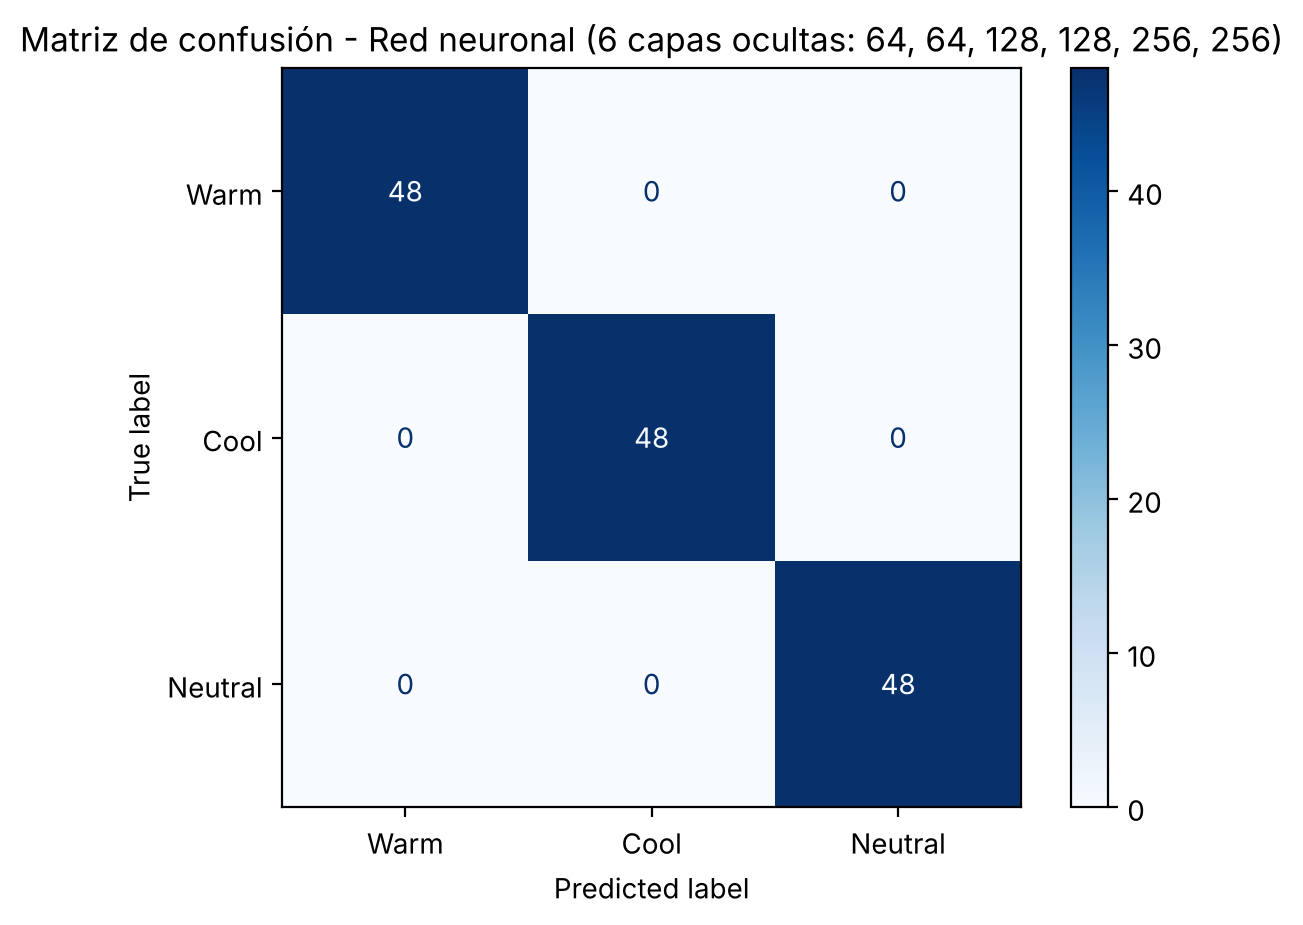

In [30]:
modelo_nn6, historia6 = entrenar_y_evaluar([64, 64, 128, 128, 256, 256],
                                            'Red neuronal (6 capas ocultas: 64, 64, 128, 128, 256, 256)')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 151,939 (593.51 KB)

 Trainable params: 151,939 (593.51 KB)

 Non-trainable params: 0 (0.00 B)

Épocas ejecutadas (EarlyStopping): 15


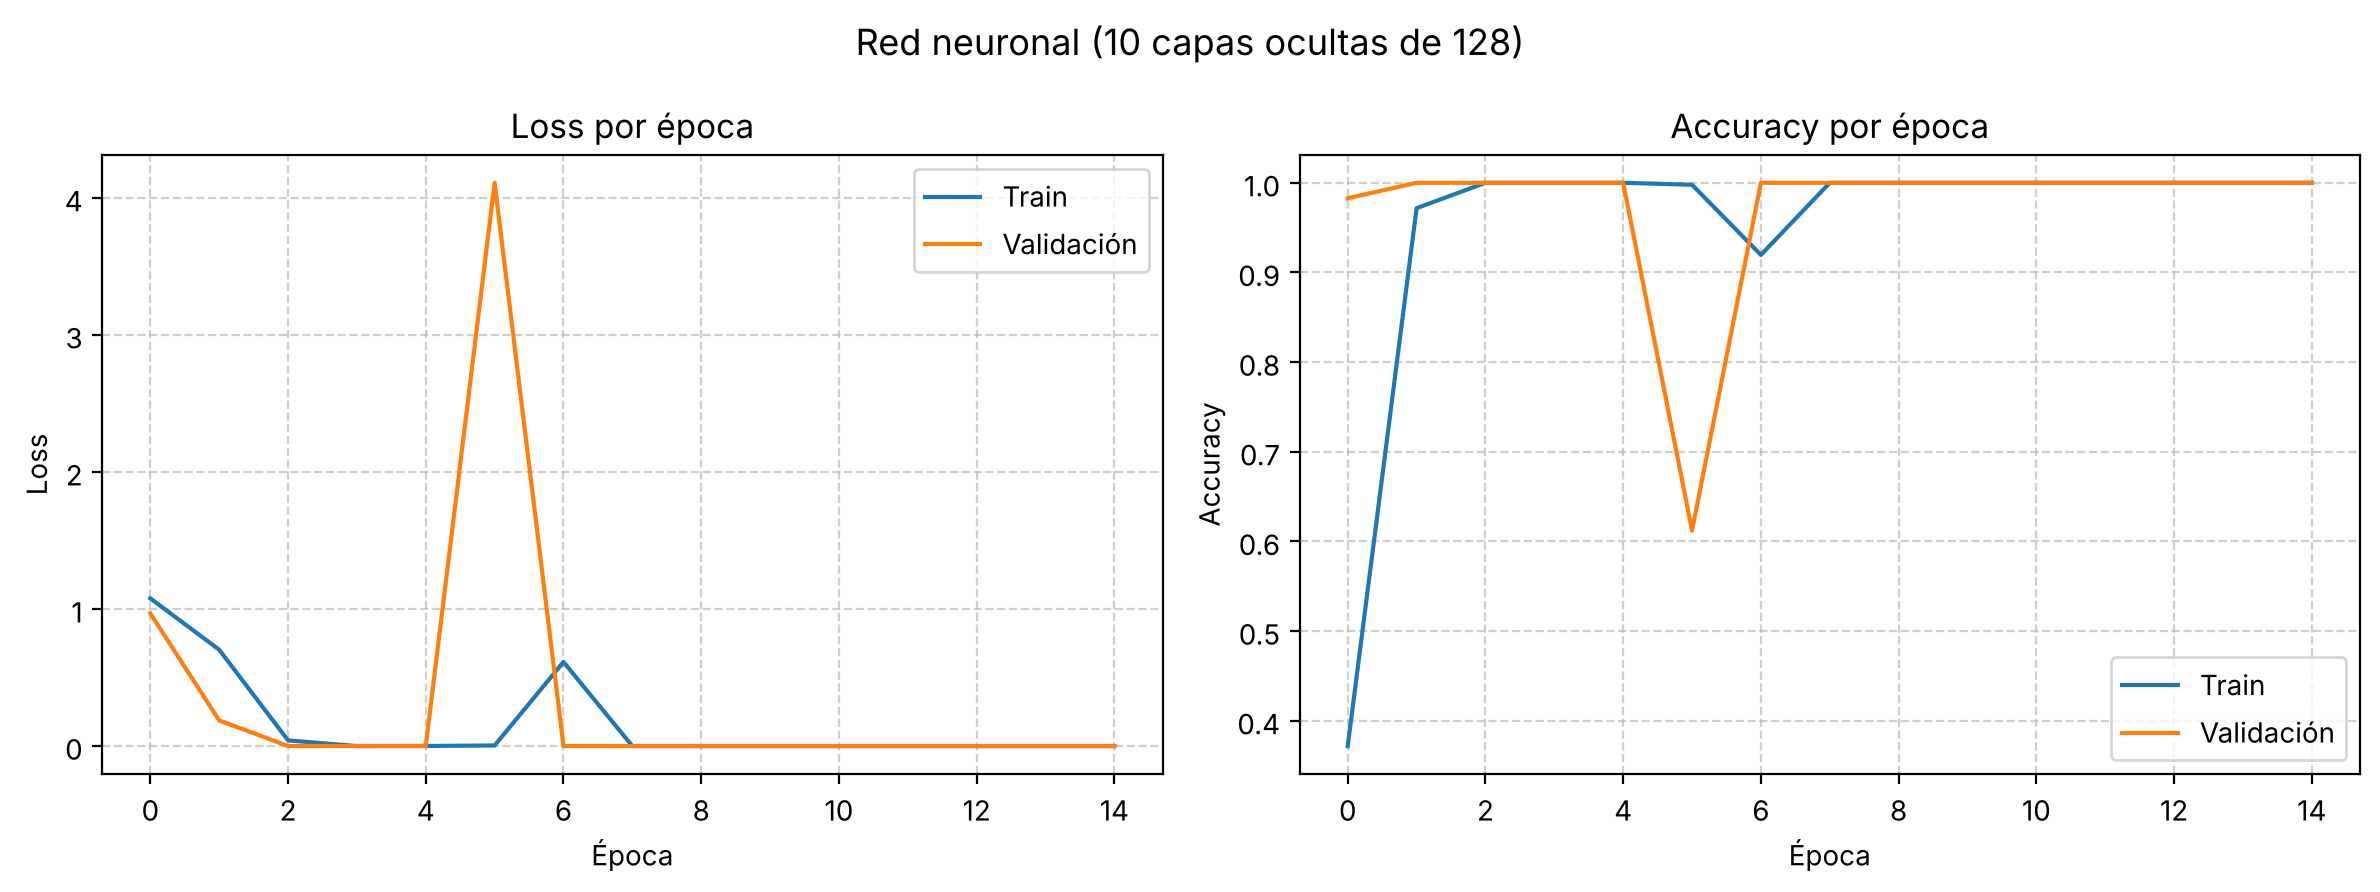


Test -> loss: 0.0000 | accuracy: 1.0000


              precision    recall  f1-score   support

        Warm       1.00      1.00      1.00        48
        Cool       1.00      1.00      1.00        48
     Neutral       1.00      1.00      1.00        48

    accuracy                           1.00       144
   macro avg       1.00      1.00      1.00       144
weighted avg       1.00      1.00      1.00       144



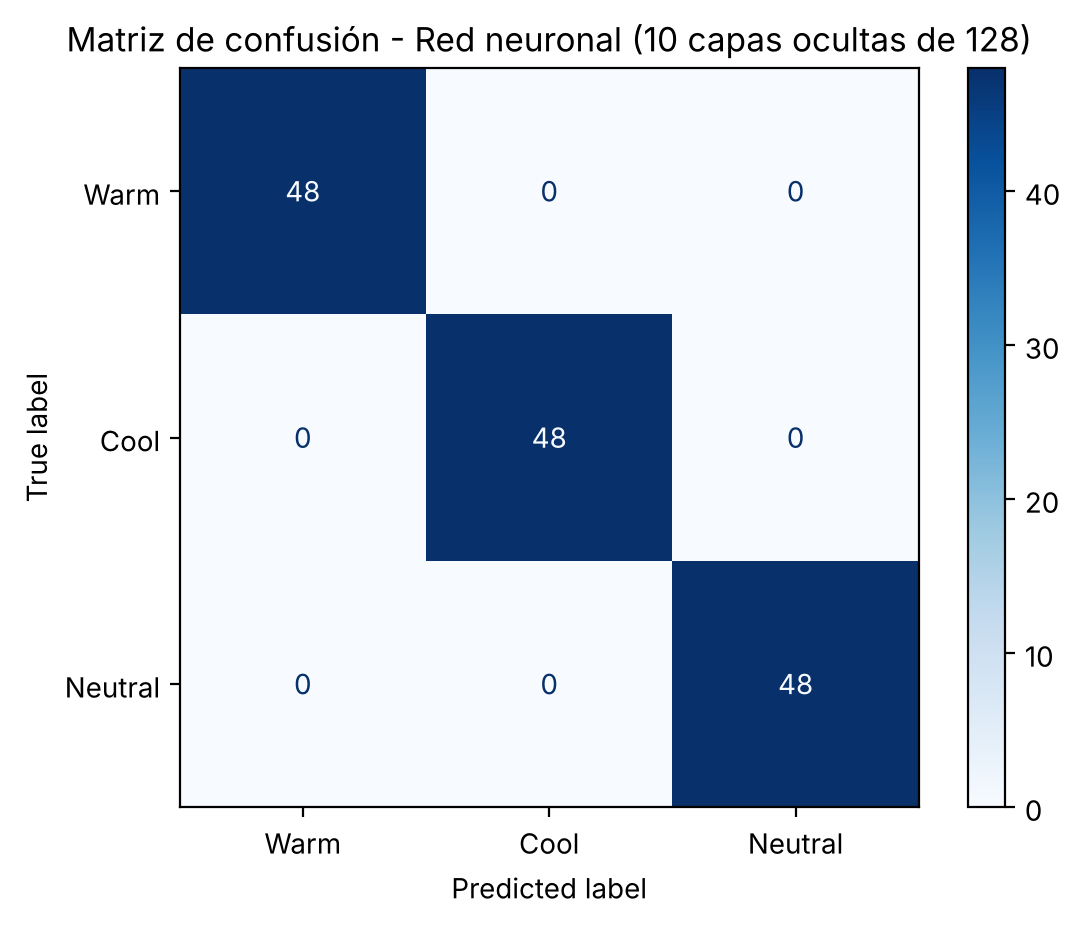

In [31]:
modelo_nn10, historia10 = entrenar_y_evaluar([128] * 10, 'Red neuronal (10 capas ocultas de 128)')

### ***Número de epochs por arquitectura***

Para cada arquitectura se entrena una red nueva con 5, 10, 50 y 100 epochs (sin EarlyStopping) y se compara la exactitud en train, validación y test.

3 capas (64,128,128) | epochs=  5 | train=1.0000 | val=1.0000 | test=1.0000


3 capas (64,128,128) | epochs= 10 | train=1.0000 | val=1.0000 | test=1.0000


3 capas (64,128,128) | epochs= 50 | train=1.0000 | val=1.0000 | test=1.0000


3 capas (64,128,128) | epochs=100 | train=1.0000 | val=1.0000 | test=1.0000


6 capas (64,64,128,128,256,256) | epochs=  5 | train=1.0000 | val=1.0000 | test=1.0000


6 capas (64,64,128,128,256,256) | epochs= 10 | train=1.0000 | val=1.0000 | test=1.0000


... (2 outputs left out)

10 capas (128 x10) | epochs=  5 | train=1.0000 | val=1.0000 | test=1.0000


10 capas (128 x10) | epochs= 10 | train=1.0000 | val=1.0000 | test=1.0000


10 capas (128 x10) | epochs= 50 | train=1.0000 | val=1.0000 | test=1.0000


10 capas (128 x10) | epochs=100 | train=1.0000 | val=1.0000 | test=1.0000


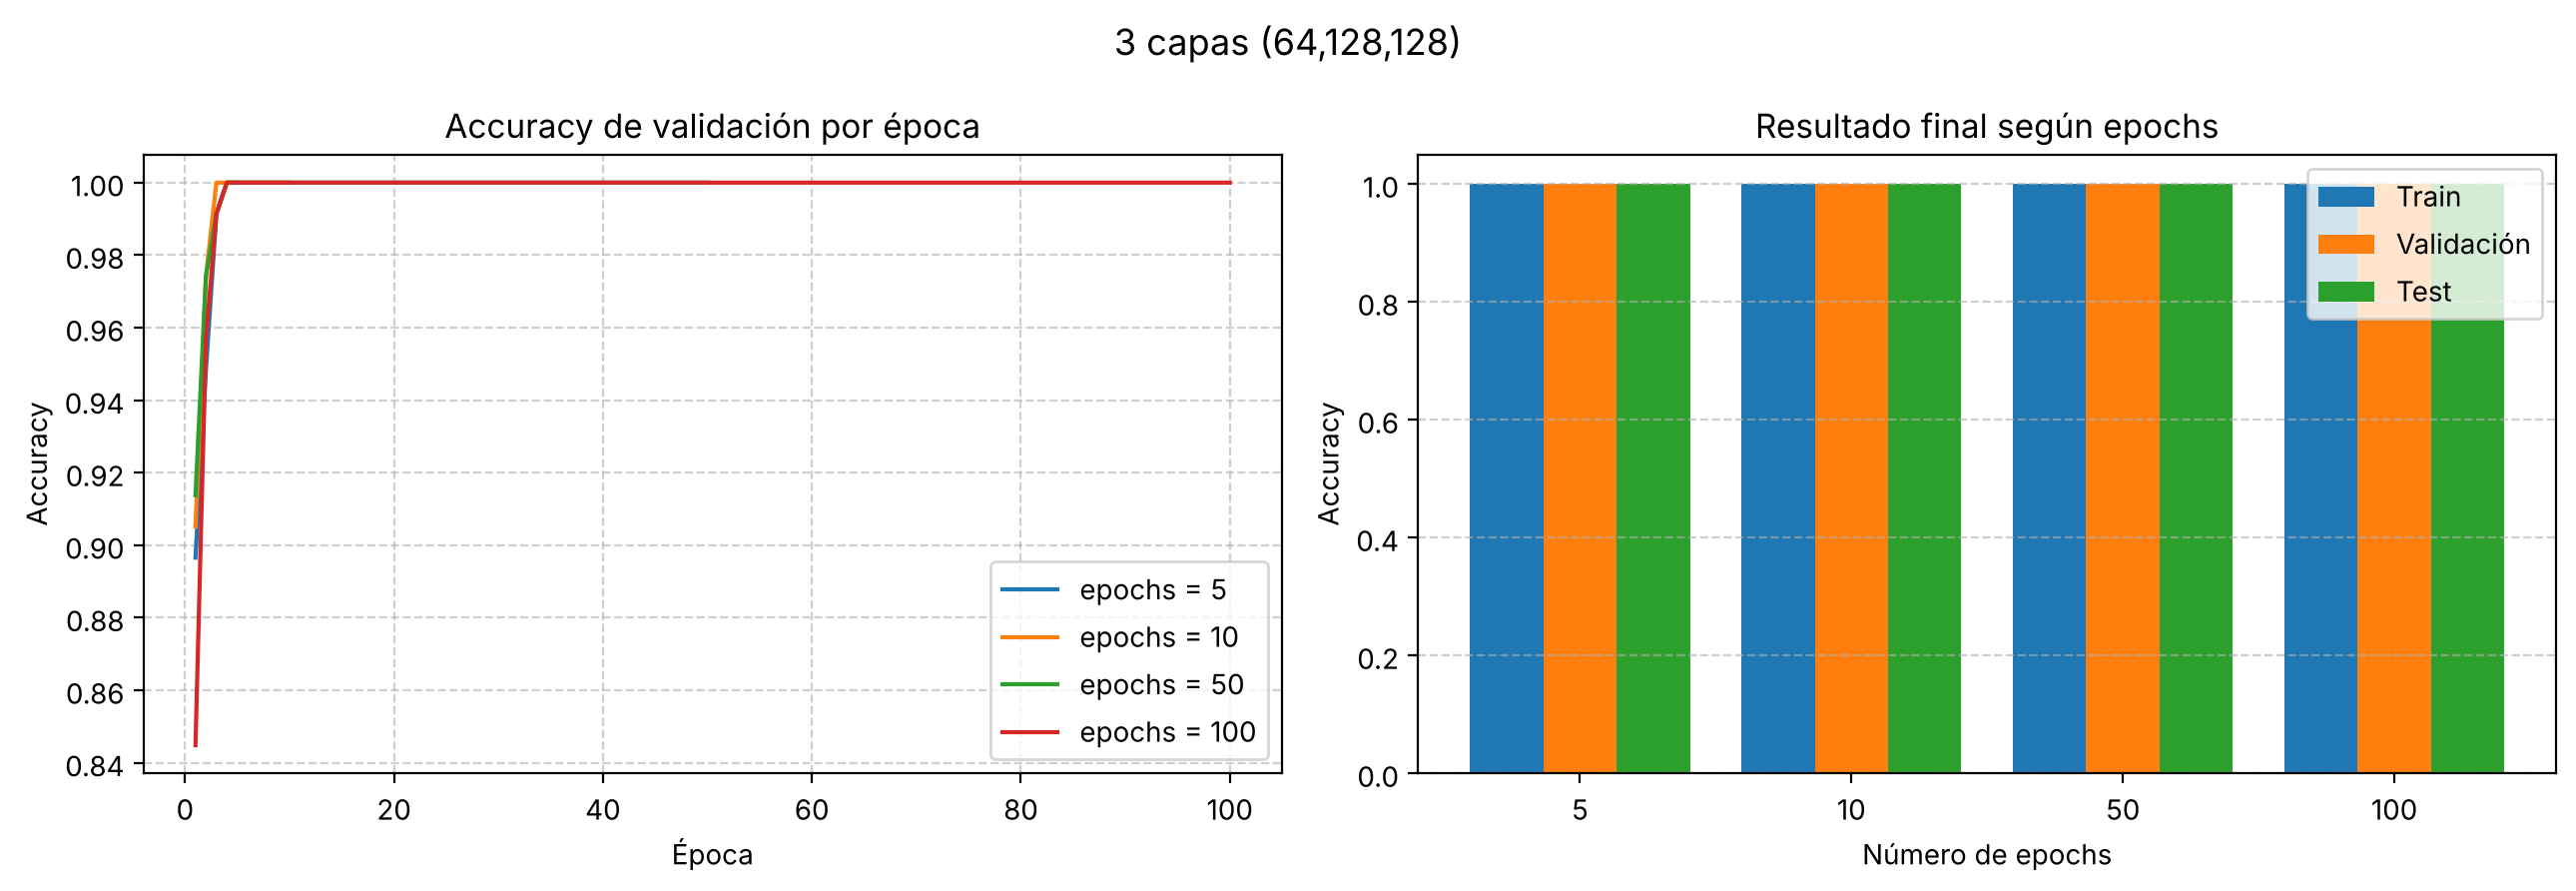

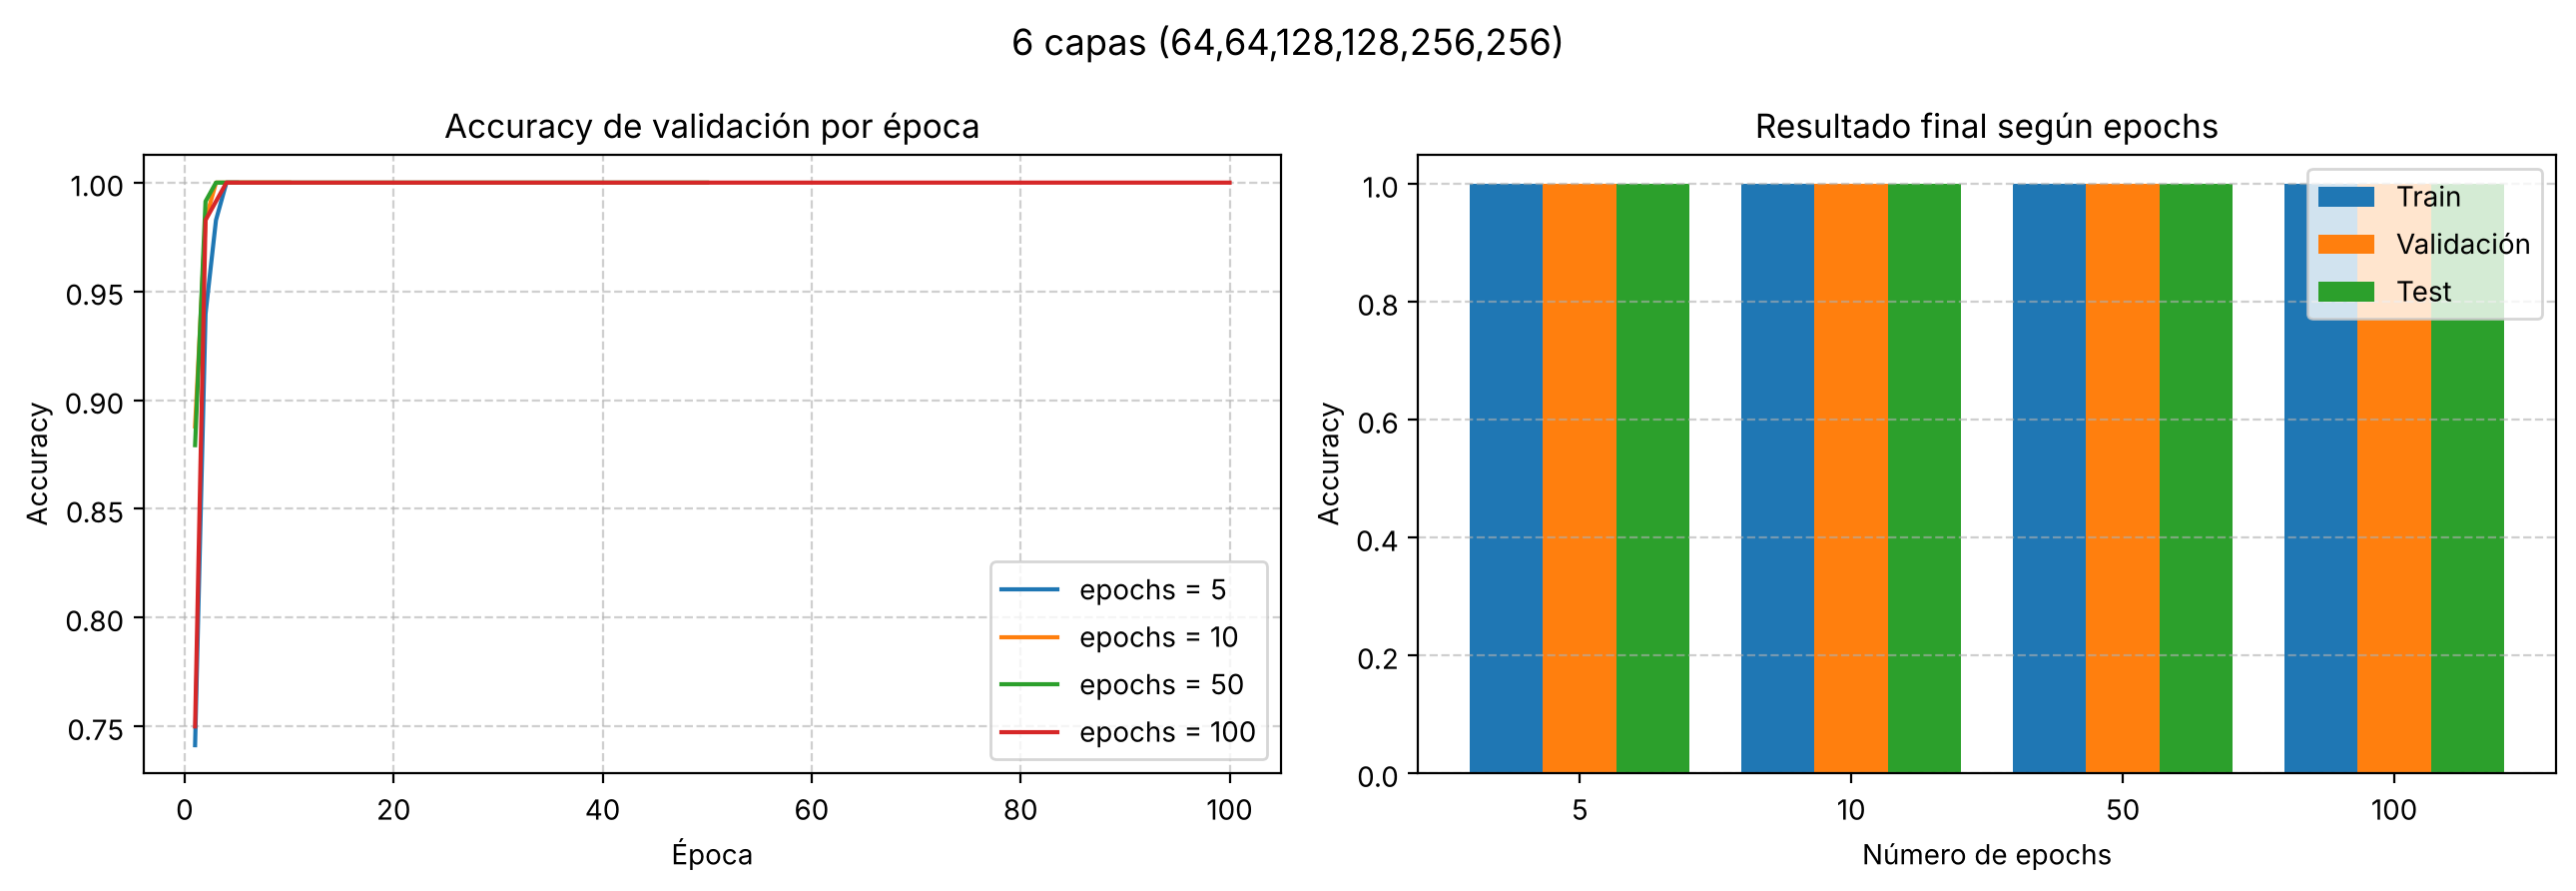

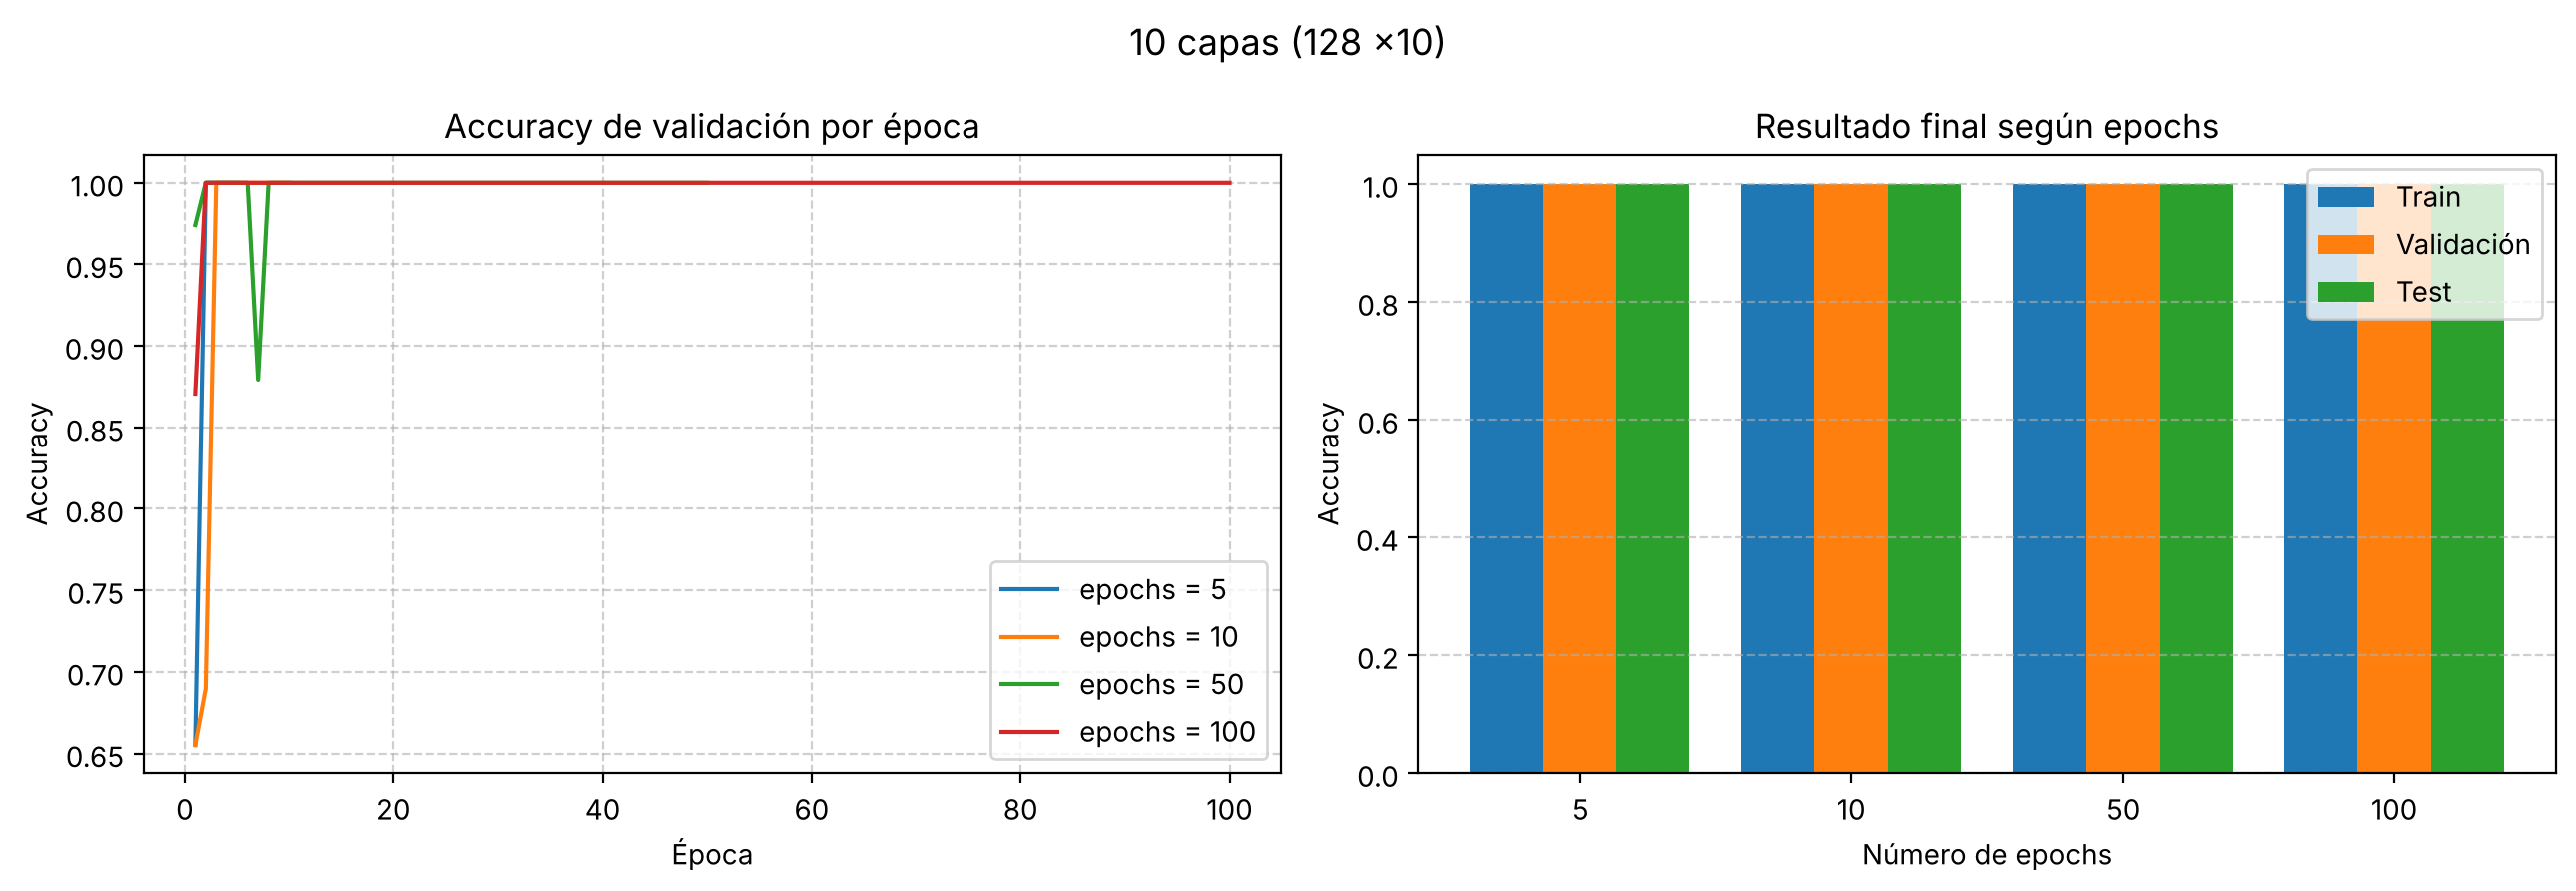


=== TABLA COMPLETA ===


,Arquitectura,Epochs,Train acc,Val acc,Val loss,Brecha (train-val),Test acc
0,"3 capas (64,128,128)",5,1.0,1.0,0.0314,0.0,1.0
1,"3 capas (64,128,128)",10,1.0,1.0,0.0012,0.0,1.0
2,"3 capas (64,128,128)",50,1.0,1.0,0.0001,0.0,1.0
3,"3 capas (64,128,128)",100,1.0,1.0,0.0000,0.0,1.0
4,"6 capas (64,64,128,128,256,256)",5,1.0,1.0,0.0006,0.0,1.0
5,"6 capas (64,64,128,128,256,256)",10,1.0,1.0,0.0000,0.0,1.0
6,"6 capas (64,64,128,128,256,256)",50,1.0,1.0,0.0000,0.0,1.0
7,"6 capas (64,64,128,128,256,256)",100,1.0,1.0,0.0000,0.0,1.0
8,10 capas (128 x10),5,1.0,1.0,0.0002,0.0,1.0
9,10 capas (128 x10),10,1.0,1.0,0.0000,0.0,1.0



=== MEJOR NÚMERO DE EPOCHS POR ARQUITECTURA (según validación) ===


,Arquitectura,Epochs,Train acc,Val acc,Val loss,Brecha (train-val),Test acc
0,"3 capas (64,128,128)",5,1.0,1.0,0.0314,0.0,1.0
4,"6 capas (64,64,128,128,256,256)",5,1.0,1.0,0.0006,0.0,1.0
8,10 capas (128 x10),5,1.0,1.0,0.0002,0.0,1.0



Mejor configuración global: 3 capas (64,128,128) con 5 epochs (val acc = 1.0000, test acc = 1.0000)


In [32]:
EPOCHS_LISTA = [5, 10, 50, 100]

ARQUITECTURAS = {
    "3 capas (64,128,128)":            [64, 128, 128],
    "6 capas (64,64,128,128,256,256)": [64, 64, 128, 128, 256, 256],
    "10 capas (128 x10)":              [128] * 10,
}

resultados = []
historias = {}

for nombre_arq, capas in ARQUITECTURAS.items():
    for ep in EPOCHS_LISTA:
        tf.random.set_seed(42)
        np.random.seed(42)
        keras.backend.clear_session()

        modelo = construir_modelo(capas)
        hist = modelo.fit(X_train_oh, y_train, validation_split=0.2,
                          epochs=ep, batch_size=64, verbose=0)

        _, acc_test = modelo.evaluate(X_test_oh, y_test, verbose=0)
        h = hist.history
        historias[(nombre_arq, ep)] = h

        resultados.append({
            'Arquitectura': nombre_arq,
            'Epochs': ep,
            'Train acc': h['accuracy'][-1],
            'Val acc': h['val_accuracy'][-1],
            'Val loss': h['val_loss'][-1],
            'Brecha (train-val)': h['accuracy'][-1] - h['val_accuracy'][-1],
            'Test acc': acc_test,
        })
        print(f"{nombre_arq} | epochs={ep:>3} | train={h['accuracy'][-1]:.4f} "
              f"| val={h['val_accuracy'][-1]:.4f} | test={acc_test:.4f}")

df_res = pd.DataFrame(resultados).round(4)

for nombre_arq in ARQUITECTURAS:
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

    # (a) Accuracy de validación por época, una línea por cada experimento
    for ep in EPOCHS_LISTA:
        h = historias[(nombre_arq, ep)]
        ax[0].plot(range(1, ep + 1), h['val_accuracy'], label=f'epochs = {ep}')
    ax[0].set_title('Accuracy de validación por época')
    ax[0].set_xlabel('Época'); ax[0].set_ylabel('Accuracy')
    ax[0].grid(True, linestyle='--', alpha=0.6); ax[0].legend()

    # (b) Train vs Validación vs Test según el número de epochs
    sub = df_res[df_res['Arquitectura'] == nombre_arq]
    pos = np.arange(len(EPOCHS_LISTA)); w = 0.27
    ax[1].bar(pos - w, sub['Train acc'], w, label='Train')
    ax[1].bar(pos,     sub['Val acc'],   w, label='Validación')
    ax[1].bar(pos + w, sub['Test acc'],  w, label='Test')
    ax[1].set_xticks(pos); ax[1].set_xticklabels(EPOCHS_LISTA)
    ax[1].set_xlabel('Número de epochs'); ax[1].set_ylabel('Accuracy')
    ax[1].set_title('Resultado final según epochs')
    ax[1].grid(True, axis='y', linestyle='--', alpha=0.6); ax[1].legend()

    plt.suptitle(nombre_arq, fontsize=13)
    plt.tight_layout()
    plt.show()

print("\n=== TABLA COMPLETA ===")
display(df_res)

# Mejor configuración: máxima exactitud en validación; si hay empate, la red más pequeña y menos epochs
ORDEN_ARQ = list(ARQUITECTURAS)
df_orden = df_res.assign(_va=df_res['Val acc'].round(3),
                         _arq=df_res['Arquitectura'].map(ORDEN_ARQ.index))
df_orden = df_orden.sort_values(['_va', '_arq', 'Epochs'], ascending=[False, True, True])

print("\n=== MEJOR NÚMERO DE EPOCHS POR ARQUITECTURA (según validación) ===")
mejores = df_orden.groupby('Arquitectura', sort=False).head(1).drop(columns=['_va', '_arq'])
display(mejores)

mejor_global = df_orden.iloc[0]
print(f"\nMejor configuración global: {mejor_global['Arquitectura']} con "
      f"{int(mejor_global['Epochs'])} epochs "
      f"(val acc = {mejor_global['Val acc']:.4f}, test acc = {mejor_global['Test acc']:.4f})")

### ***Comparación final: DT, RF, SVM y Deep Learning***

Cada modelo se entrena con su mejor configuración (la más simple entre las que empatan en exactitud) y se compara con el mismo conjunto de test.

RF: n_estimators=10 | SVM: kernel=linear | DL: [64, 128, 128], 5 epochs
DT entrenado
RF entrenado
SVM entrenado


DL entrenado


,Accuracy,Precision,Recall,F1-score
Modelo,,,,
DT,1.0,1.0,1.0,1.0
RF,1.0,1.0,1.0,1.0
SVM,1.0,1.0,1.0,1.0
DL,1.0,1.0,1.0,1.0


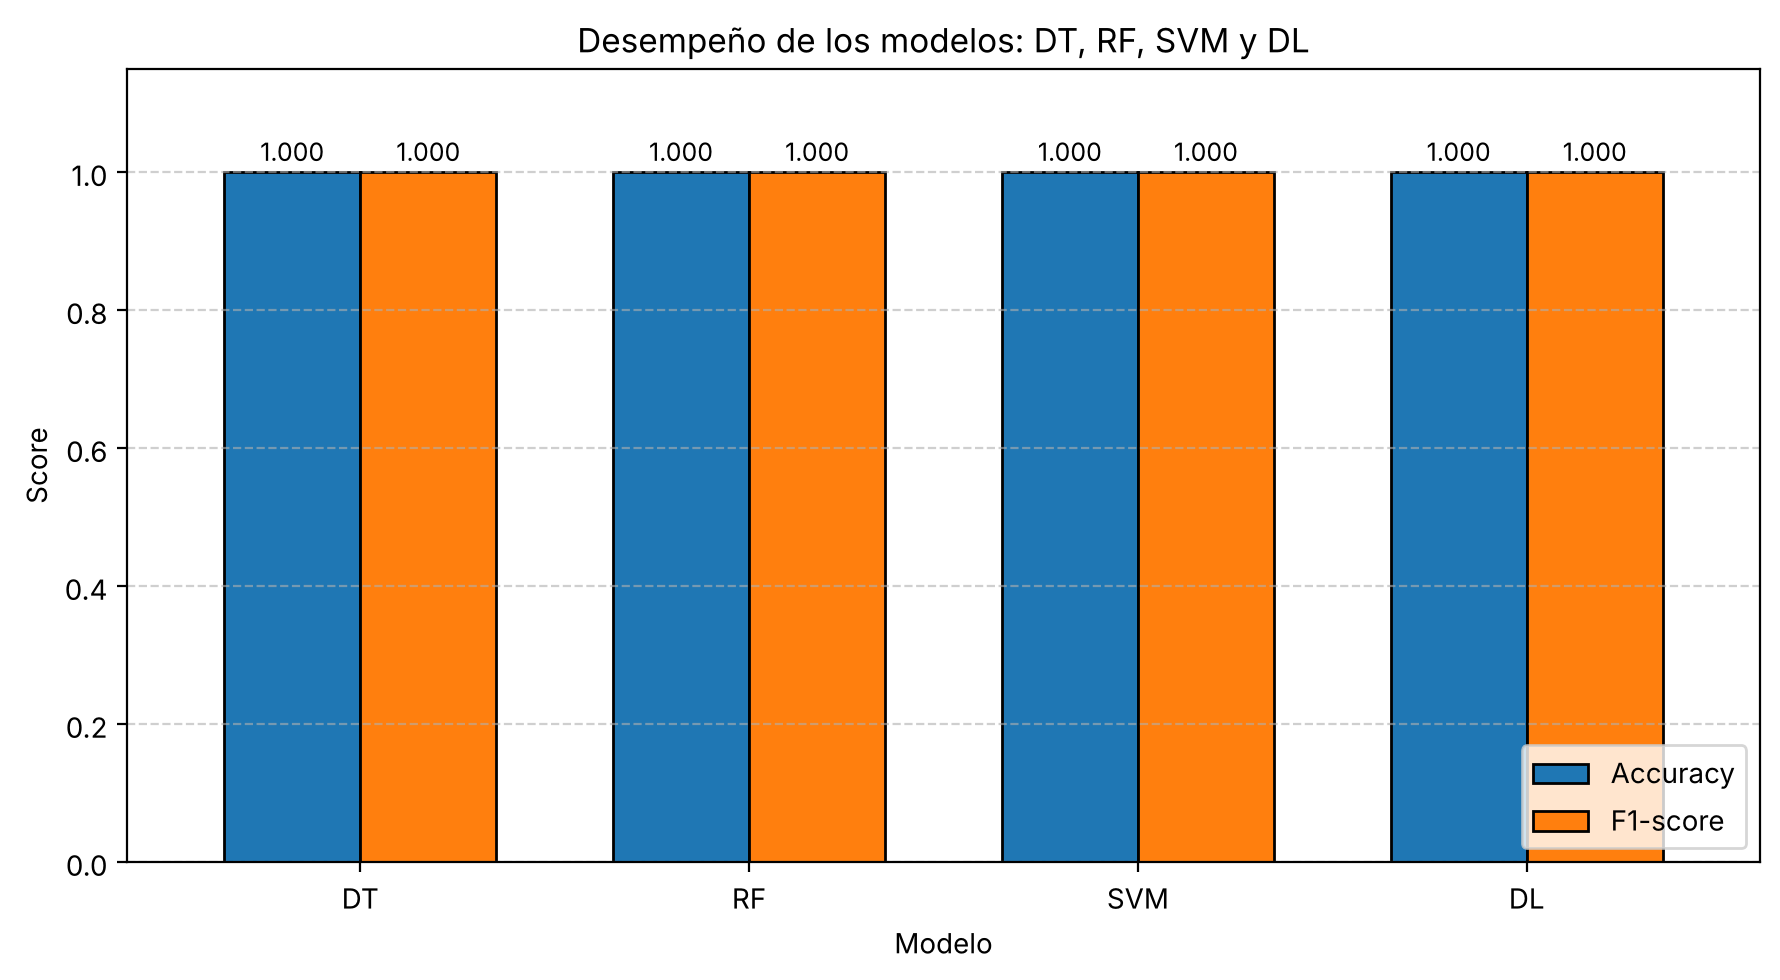

Mejor modelo por accuracy: DT (1.0000)


In [33]:
# Mejores hiperparámetros: el más simple entre los que empatan en la cima de su curva de aprendizaje
def mejor_simple(res, preferencia):
    top = res[res['Validación'] >= res['Validación'].max() - 0.001]['Modelo'].tolist()
    return min(top, key=preferencia)

N_ESTIMATORS_RF = int(mejor_simple(res_rf, lambda m: int(m.split('=')[1])).split('=')[1])
KERNEL_SVM = mejor_simple(res_svm, lambda m: ['linear', 'rbf', 'poly'].index(m.split('=')[1].strip())).split('=')[1].strip()
CAPAS_DL = ARQUITECTURAS[mejor_global['Arquitectura']]
EPOCHS_DL = int(mejor_global['Epochs'])
print(f"RF: n_estimators={N_ESTIMATORS_RF} | SVM: kernel={KERNEL_SVM} | DL: {CAPAS_DL}, {EPOCHS_DL} epochs")

modelos_finales = {
    'DT':  Pipeline([('pre', clone(preprocessor)), ('clf', DecisionTreeClassifier(random_state=42))]),
    'RF':  Pipeline([('pre', clone(preprocessor)), ('clf', RandomForestClassifier(n_estimators=N_ESTIMATORS_RF, random_state=42, n_jobs=-1))]),
    'SVM': Pipeline([('pre', clone(preprocessor)), ('clf', SVC(kernel=KERNEL_SVM, random_state=42))]),
}

predicciones = {}
for nombre, modelo in modelos_finales.items():
    modelo.fit(X_train, y_train)
    predicciones[nombre] = modelo.predict(X_test)
    print(f"{nombre} entrenado")

tf.random.set_seed(42); np.random.seed(42); keras.backend.clear_session()
modelo_dl = construir_modelo(CAPAS_DL)
modelo_dl.fit(X_train_oh, y_train, validation_split=0.2, epochs=EPOCHS_DL, batch_size=64, verbose=0)
predicciones['DL'] = np.argmax(modelo_dl.predict(X_test_oh, verbose=0), axis=1)
print("DL entrenado")

filas = []
for nombre, y_p in predicciones.items():
    filas.append({
        'Modelo': nombre,
        'Accuracy':  accuracy_score(y_test, y_p),
        'Precision': precision_score(y_test, y_p, average='weighted', zero_division=0),
        'Recall':    recall_score(y_test, y_p, average='weighted', zero_division=0),
        'F1-score':  f1_score(y_test, y_p, average='weighted', zero_division=0),
    })
df_desempeno = pd.DataFrame(filas).set_index('Modelo').round(4)
display(df_desempeno)

ax = df_desempeno[['Accuracy', 'F1-score']].plot(kind='bar', figsize=(9, 5),
                                                 color=['tab:blue', 'tab:orange'],
                                                 edgecolor='black', width=0.7)
for c in ax.containers:
    ax.bar_label(c, fmt='%.3f', padding=2, fontsize=9)
ax.set_title('Desempeño de los modelos: DT, RF, SVM y DL')
ax.set_ylabel('Score'); ax.set_xlabel('Modelo'); ax.set_ylim(0, 1.15)
ax.grid(True, axis='y', linestyle='--', alpha=0.6)
plt.xticks(rotation=0); plt.legend(loc='lower right')
plt.tight_layout(); plt.show()

mejor = df_desempeno['Accuracy'].idxmax()
print(f"Mejor modelo por accuracy: {mejor} ({df_desempeno.loc[mejor, 'Accuracy']:.4f})")

###***Tercera Parte***

Esta parte aplica **aprendizaje no supervisado** a las 4 entradas del dataset (sin mirar la variable objetivo) y después compara los grupos que encuentra el algoritmo con las clases reales. Sigue los cinco puntos de la sustentación:

| # | Pide la sustentación | Dónde está |
|---|---|---|
| i | Escalar los datos: StandardScaler y MinMaxScaler | *Escalado de datos* |
| ii | PCA a 2 componentes (opcional: t-SNE) | *Reducción de dimensionalidad* |
| iii | K-Means con `n_clusters` = número de clases del dataset | *Clustering: K-Means* |
| iv | DBSCAN: buscar `eps` y `min_samples` **y explicar por qué** | *Clustering: DBSCAN* |
| v | Gráficas: original, K-Means y DBSCAN | *GRAFICAS* |

**Idea general.** La parte supervisada responde "dado el subtono, ¿qué paleta le toca?" usando las etiquetas. Aquí se pregunta lo contrario: *si no conociera la respuesta, ¿los datos se agrupan solos de la misma forma?* Es como repartir a un grupo de personas en 3 mesas solo por lo parecidas que son, sin saber qué paleta les corresponde, y luego mirar si cada mesa terminó con una sola paleta.

## **Escalado de datos**

Se aplican dos técnicas de escalado a las variables de entrada (ya codificadas con One-Hot, 22 columnas):

1. **StandardScaler:** media 0 y desviación estándar 1: z = (x - μ) / σ
2. **MinMaxScaler:** reescala al rango [0, 1]: x' = (x - x_min) / (x_max - x_min)

El escalador se ajusta (`fit`) solo con train y luego se aplica (`transform`) a test, para evitar fuga de información. Escalar importa porque PCA, K-Means y DBSCAN trabajan con **distancias**: una columna con valores grandes dominaría a las demás.

In [34]:
columnas_oh = [n.split('__', 1)[1] for n in preprocessor.get_feature_names_out()]

# 1. StandardScaler
std_scaler = StandardScaler().fit(X_train_oh)
X_train_std = pd.DataFrame(std_scaler.transform(X_train_oh), columns=columnas_oh)
X_test_std = pd.DataFrame(std_scaler.transform(X_test_oh), columns=columnas_oh)

# 2. MinMaxScaler
mm_scaler = MinMaxScaler().fit(X_train_oh)
X_train_mm = pd.DataFrame(mm_scaler.transform(X_train_oh), columns=columnas_oh)
X_test_mm = pd.DataFrame(mm_scaler.transform(X_test_oh), columns=columnas_oh)

X_train_orig = pd.DataFrame(X_train_oh, columns=columnas_oh)

mostrar = columnas_oh[:3] + ['Under Tone_Warm', 'Under Tone_Cool']
print("--- Datos originales (train, One-Hot) ---")
display(X_train_orig[mostrar].describe().loc[['mean', 'std', 'min', 'max']].round(3))
print("--- StandardScaler (train) ---")
display(X_train_std[mostrar].describe().loc[['mean', 'std', 'min', 'max']].round(3))
print("--- MinMaxScaler (train) ---")
display(X_train_mm[mostrar].describe().loc[['mean', 'std', 'min', 'max']].round(3))

print("¿MinMaxScaler dejó los datos igual que el One-Hot original?:",
      np.allclose(X_train_orig.values, X_train_mm.values))

--- Datos originales (train, One-Hot) ---


,Hair Color_Black,Hair Color_Blonde,Hair Color_Brown,Under Tone_Warm,Under Tone_Cool
mean,0.205,0.189,0.205,0.333,0.333
std,0.404,0.392,0.404,0.472,0.472
min,0.000,0.000,0.000,0.000,0.000
max,1.000,1.000,1.000,1.000,1.000


--- StandardScaler (train) ---


,Hair Color_Black,Hair Color_Blonde,Hair Color_Brown,Under Tone_Warm,Under Tone_Cool
mean,0.000,-0.000,-0.000,-0.000,-0.000
std,1.001,1.001,1.001,1.001,1.001
min,-0.508,-0.483,-0.508,-0.707,-0.707
max,1.970,2.070,1.970,1.414,1.414


--- MinMaxScaler (train) ---


,Hair Color_Black,Hair Color_Blonde,Hair Color_Brown,Under Tone_Warm,Under Tone_Cool
mean,0.205,0.189,0.205,0.333,0.333
std,0.404,0.392,0.404,0.472,0.472
min,0.000,0.000,0.000,0.000,0.000
max,1.000,1.000,1.000,1.000,1.000


¿MinMaxScaler dejó los datos igual que el One-Hot original?: True


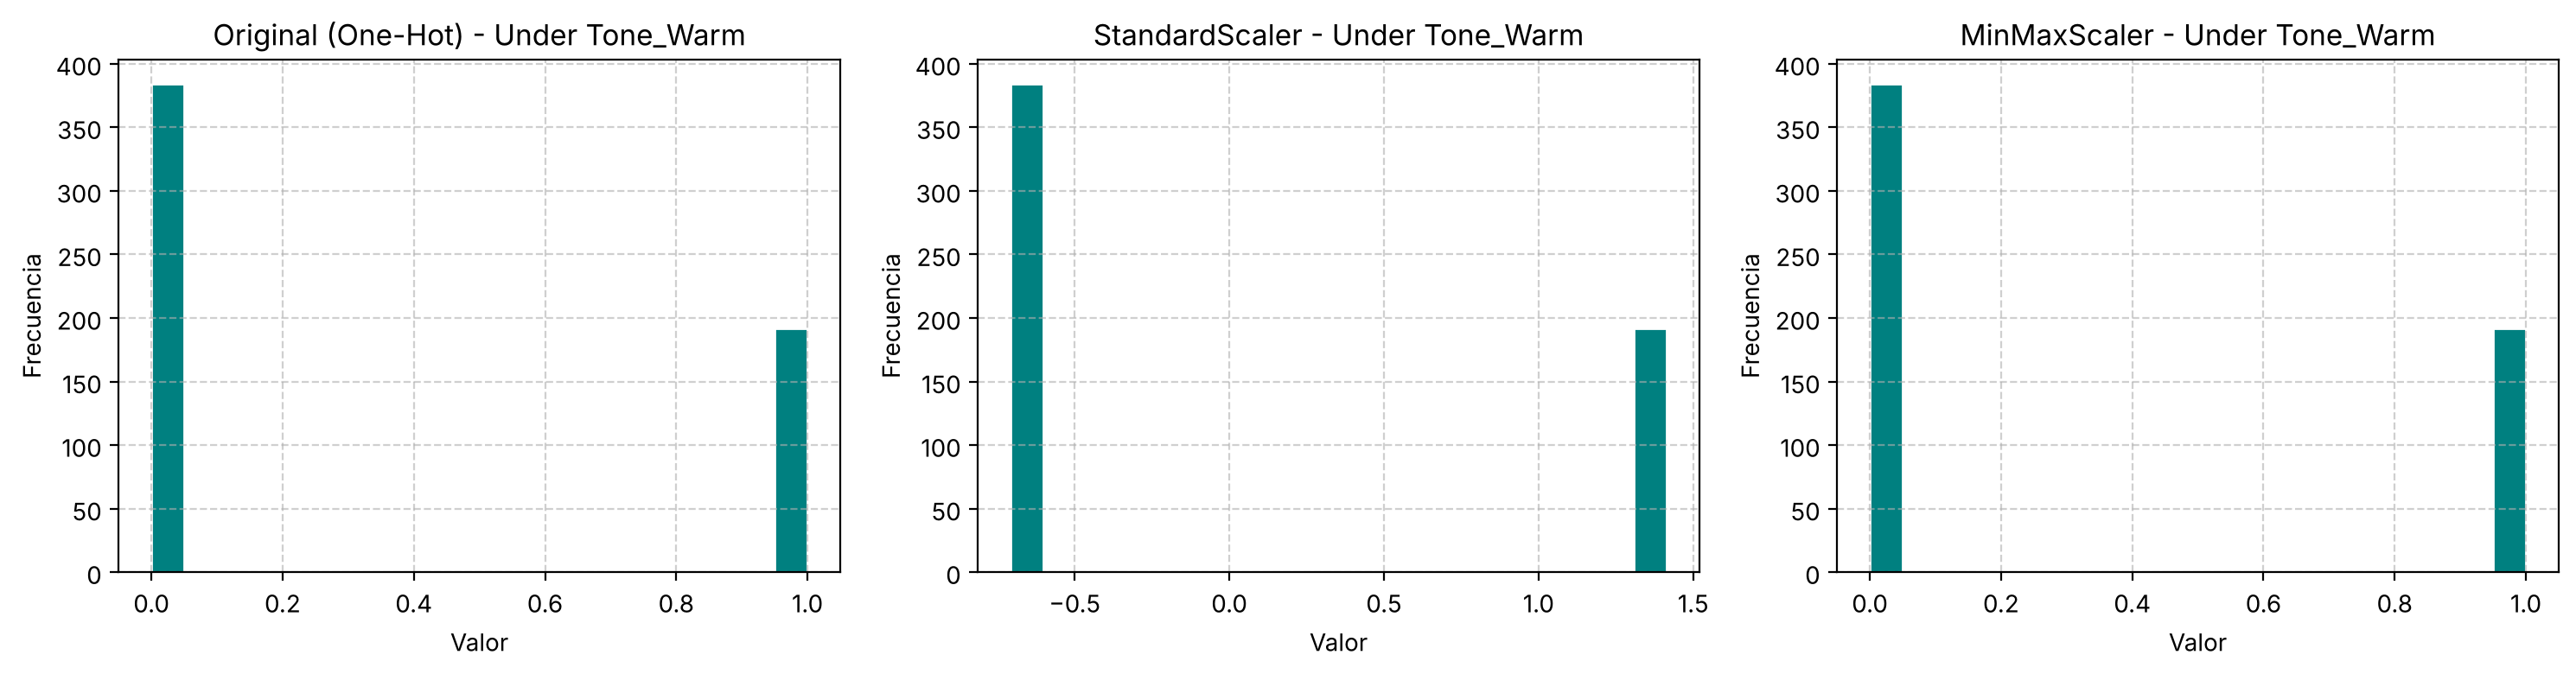

In [35]:
columna = 'Under Tone_Warm'

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
datos = [(X_train_orig[columna], 'Original (One-Hot)'),
         (X_train_std[columna], 'StandardScaler'),
         (X_train_mm[columna], 'MinMaxScaler')]
for a, (serie, titulo) in zip(ax, datos):
    a.hist(serie, bins=20, color='teal', edgecolor='white')
    a.set_title(f'{titulo} - {columna}')
    a.set_xlabel('Valor'); a.set_ylabel('Frecuencia')
    a.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**Qué se ve y por qué.** Las columnas One-Hot ya valen 0 o 1, así que **MinMaxScaler no las cambia** (el mínimo ya es 0 y el máximo ya es 1). StandardScaler sí las modifica: las centra en 0 y les da desviación 1, de modo que cada categoría pesa lo mismo en las distancias, incluso las poco frecuentes. Por eso la elección entre los dos se hace con evidencia: se prueban ambos en el resto de la parte y se comparan.

## **Reducción de dimensionalidad: PCA y t-SNE**

Después de escalar, se pasa de las **22 columnas** a solo **2 componentes**. Esto permite dibujar los datos en un plano y ver si las clases forman grupos.

**1. PCA (Análisis de Componentes Principales)**

Técnica lineal: busca las direcciones en las que los datos varían más y proyecta sobre ellas. Cada componente es una combinación de las columnas originales. Es rápida, determinista y permite saber cuánta información conserva cada componente mediante la **varianza explicada**.

**2. t-SNE (opcional)**

Técnica no lineal que intenta conservar la vecindad: los registros parecidos quedan cerca en el plano. Se usa solo para visualizar, es más lenta (por eso se limita a una muestra de hasta 3000 filas) y sus ejes no se interpretan directamente.

Ambas se aplican sobre los datos escalados con **StandardScaler** y se ajustan solo con train.

In [36]:
# Reduce las N columnas (22) a 2 componentes
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_train_std)

df_pca = pd.DataFrame(X_pca, columns=['PCA1', 'PCA2'])
df_pca['Clase'] = y_train

print("Forma original:", X_train_std.shape)
print("Forma con PCA:", X_pca.shape)
print("Varianza explicada por componente:", pca.explained_variance_ratio_.round(4))
print("Varianza total explicada:", pca.explained_variance_ratio_.sum().round(4))
df_pca.head()

Forma original: (576, 22)
Forma con PCA: (576, 2)
Varianza explicada por componente: [0.0703 0.0692]
Varianza total explicada: 0.1395


,PCA1,PCA2,Clase
0,-1.071269,-1.098282,0
1,1.885206,-0.535088,2
2,1.883948,-0.161109,2
3,-0.677082,1.951667,1
4,-0.172596,1.538063,1


In [37]:
# ¿Qué variables originales forman PCA1 y PCA2? (suma de los pesos al cuadrado de sus columnas One-Hot)
pesos = pd.Series((pca.components_ ** 2).sum(axis=0), index=columnas_oh)
aporte = pd.Series({e: pesos[[c for c in columnas_oh if c.startswith(e + '_')]].sum() for e in ENTRADAS})
print("Aporte de cada variable a los 2 componentes (el total es 2):")
print(aporte.round(3).sort_values(ascending=False))
print("\nVarianza explicada por los 6 primeros componentes:",
      PCA(n_components=6, random_state=42).fit(X_train_std).explained_variance_ratio_.round(4))

Aporte de cada variable a los 2 componentes (el total es 2):
Under Tone    1.804
Hair Color    0.095
Eye Color     0.082
Skin Tone     0.019
dtype: float32

Varianza explicada por los 6 primeros componentes: [0.0703 0.0692 0.0606 0.0587 0.0581 0.058 ]


**Qué muestra PCA y por qué.**

- **La varianza explicada es baja (≈ 14 %).** Las 4 variables son independientes entre sí (el dataset contiene todas las combinaciones posibles), así que no existe una dirección que concentre la variación. Con datos reales, donde unas variables se parecen a otras, los primeros componentes capturarían mucho más.
- **PCA1 y PCA2 están hechos casi por completo de `Under Tone`** (aporta ≈ 1.8 de un total de 2; pelo, ojos y piel aportan menos de 0.1 cada uno). Con las columnas estandarizadas, una variable con pocas categorías deja más variación por columna que una con muchas, y el subtono es la única con 3 categorías (pelo tiene 5, piel 6 y ojos 8). Por eso en el plano aparecen **3 grupos, uno por subtono**, y cada grupo tiene un solo color.
- **Ojo:** esos 3 grupos son solo la "sombra" de los datos sobre un plano. En las 22 dimensiones completas todos los puntos están conectados entre sí por las demás variables (pelo, ojos y piel), y eso es lo que verá DBSCAN más adelante.

In [38]:
# t-SNE es lento con muchas filas, por eso se toma una muestra de hasta 3000 (aquí train tiene 576, así que entra completo)
n_muestra = 3000
rng = np.random.RandomState(42)
idx = rng.choice(len(X_train_std), size=min(n_muestra, len(X_train_std)), replace=False)

X_muestra = X_train_std.iloc[idx]
y_muestra = y_train[idx]

tsne = TSNE(n_components=2, perplexity=30, random_state=42, init='pca', learning_rate='auto')
X_tsne = tsne.fit_transform(X_muestra)

df_tsne = pd.DataFrame(X_tsne, columns=['TSNE1', 'TSNE2'])
df_tsne['Clase'] = y_muestra

print("Forma original:", X_muestra.shape)
print("Forma con t-SNE:", X_tsne.shape)
df_tsne.head()

Forma original: (576, 22)
Forma con t-SNE: (576, 2)


,TSNE1,TSNE2,Clase
0,-4.459046,17.797756,0
1,-7.981705,-17.516708,0
2,11.655890,-0.660706,0
3,11.947086,-0.837582,1
4,-0.285534,-8.588453,0


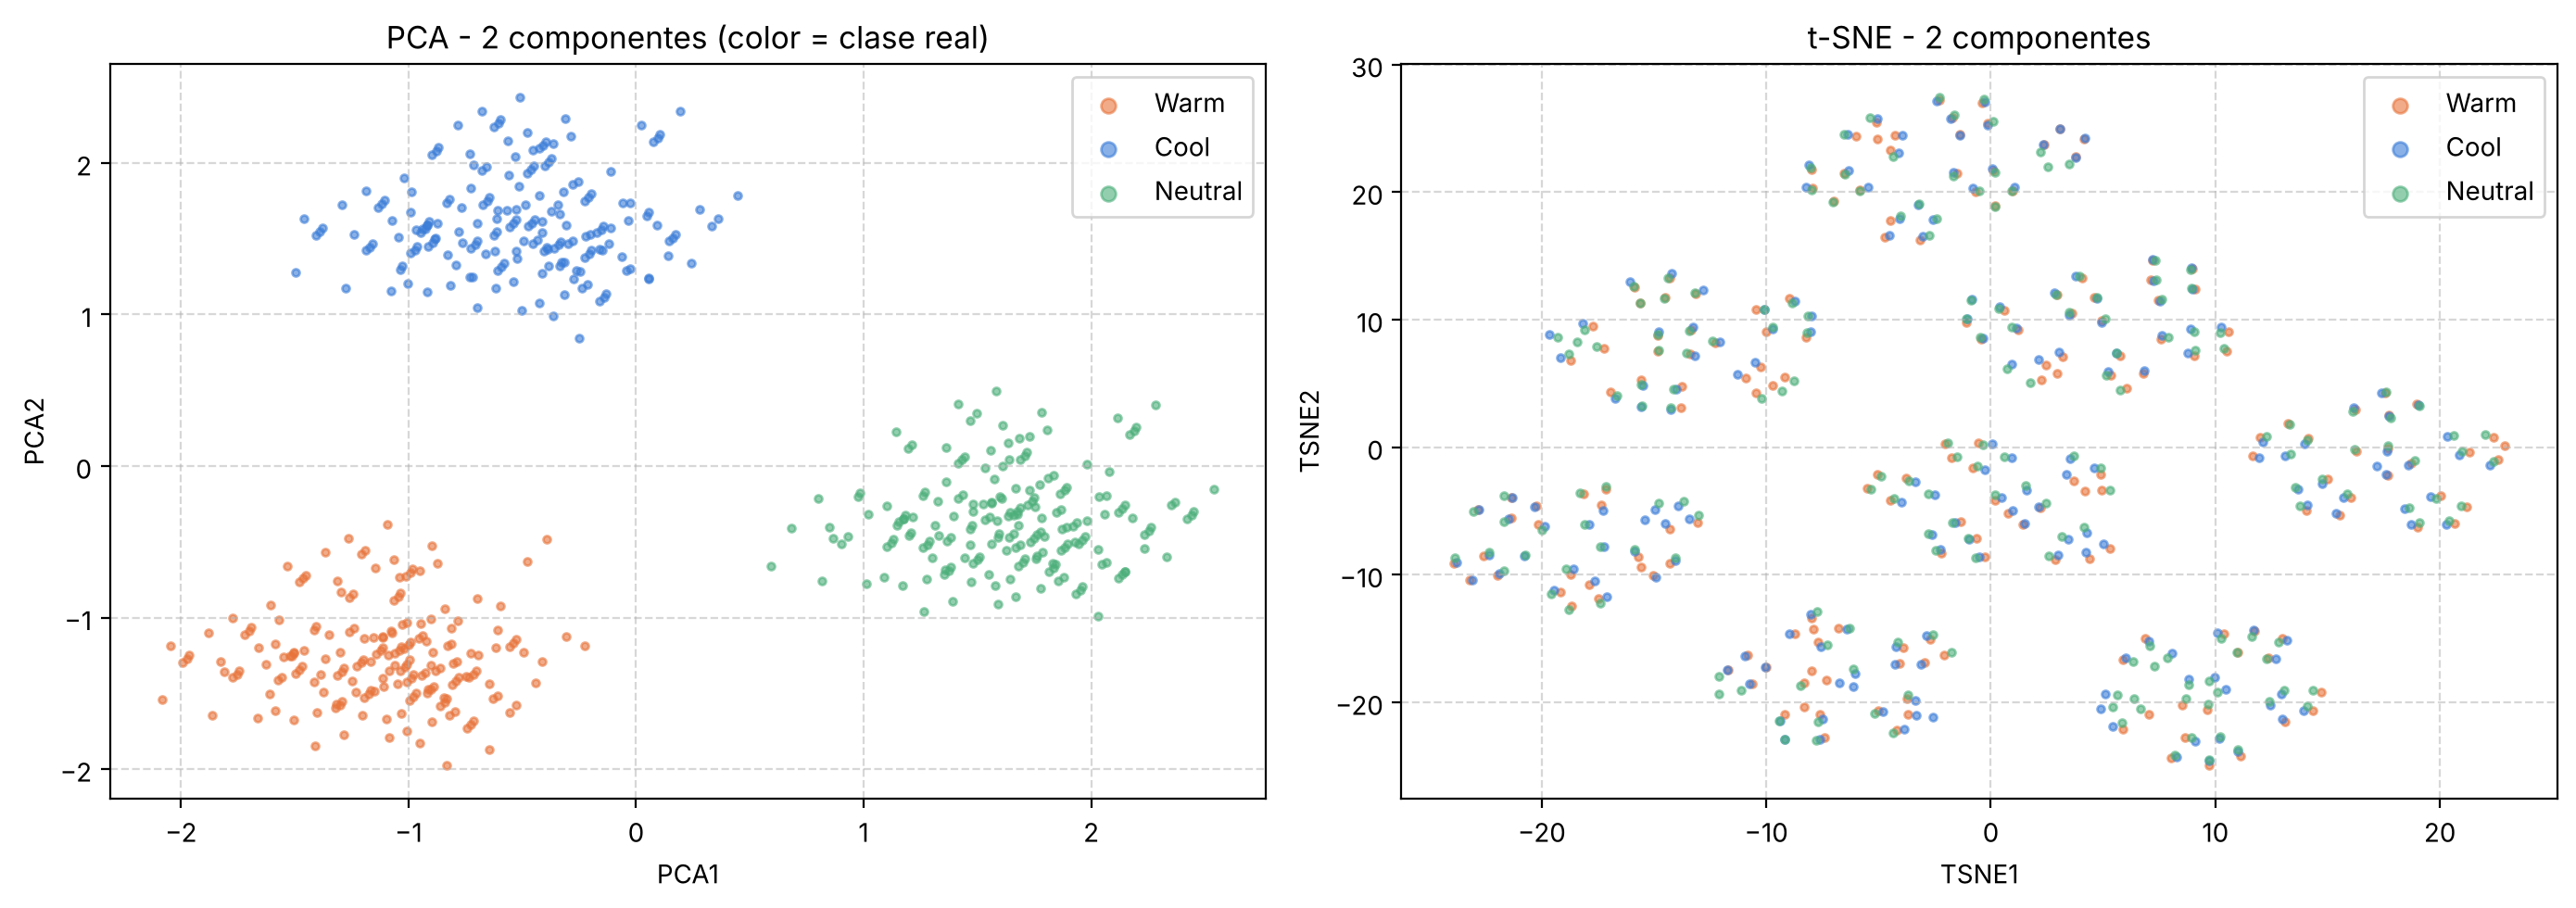

In [39]:
COLOR_CLASE = {'Warm': '#E8743B', 'Cool': '#3B7DD8', 'Neutral': '#4CAF7A'}

def pintar_clases(ax, xy, etiquetas):
    for i, nombre in enumerate(NOMBRES):
        m = etiquetas == i
        ax.scatter(xy[m, 0], xy[m, 1], s=8, alpha=0.6, color=COLOR_CLASE.get(nombre, 'gray'), label=nombre)
    ax.legend(markerscale=2, loc='best')

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
pintar_clases(ax[0], df_pca[['PCA1', 'PCA2']].values, df_pca['Clase'].values)
ax[0].set_title('PCA - 2 componentes (color = clase real)')
ax[0].set_xlabel('PCA1'); ax[0].set_ylabel('PCA2')

pintar_clases(ax[1], df_tsne[['TSNE1', 'TSNE2']].values, df_tsne['Clase'].values)
ax[1].set_title('t-SNE - 2 componentes')
ax[1].set_xlabel('TSNE1'); ax[1].set_ylabel('TSNE2')

for a in ax:
    a.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [40]:
# Comparación de los dos escaladores con el mismo PCA y el mismo K-Means (k = nº de clases)
filas = []
for nombre_esc, M_train in [('StandardScaler', X_train_std.values), ('MinMaxScaler', X_train_mm.values)]:
    p = PCA(n_components=2, random_state=42).fit(M_train)
    km = KMeans(n_clusters=len(NOMBRES), random_state=42, n_init=100).fit(M_train)
    # ¿Con qué frecuencia una sola inicialización de K-Means encuentra los 3 subtonos? (100 semillas, n_init=1)
    aciertos = sum(adjusted_rand_score(y_train, KMeans(n_clusters=len(NOMBRES), random_state=s_, n_init=1)
                                       .fit(M_train).labels_) > 0.99 for s_ in range(100))
    filas.append({'Escalado': nombre_esc,
                  '% de inicios que hallan el subtono': aciertos,
                  'Varianza explicada (2 comp.)': p.explained_variance_ratio_.sum(),
                  'Silhouette K-Means': silhouette_score(M_train, km.labels_, sample_size=5000, random_state=42),
                  'ARI K-Means vs clases': adjusted_rand_score(y_train, km.labels_)})
pd.DataFrame(filas).set_index('Escalado').round(4)

,% de inicios que hallan el subtono,Varianza explicada (2 comp.),Silhouette K-Means,ARI K-Means vs clases
Escalado,,,,
StandardScaler,13,0.1395,0.0995,1.0
MinMaxScaler,75,0.2113,0.1548,1.0


**Decisión:** el resto de la parte usa **StandardScaler**, que es la opción estándar cuando se usan distancias y deja a todas las columnas con la misma escala. En la tabla, MinMax muestra más varianza explicada y silhouette, pero esos números no se pueden comparar entre escaladores: cada uno mide distancias en un espacio distinto (el de MinMax es simplemente el One-Hot sin tocar). Lo que sí es comparable es el **ARI de K-Means con 100 inicios, que es 1 con los dos**: el algoritmo puede encontrar los 3 subtonos con cualquiera.

Hay una diferencia que importa: **qué tan fácil** es encontrarlos. La columna *% de inicios que hallan el subtono* cuenta cuántas de 100 inicializaciones sueltas de K-Means llegan a la partición correcta. Con MinMax son la gran mayoría; con StandardScaler solo unas pocas, porque estandarizar le da el mismo peso a categorías muy poco frecuentes (por ejemplo un color de ojos que tiene pocas personas) y eso crea muchos mínimos locales que compiten con la partición por subtono. Por eso K-Means necesita más inicios con StandardScaler (ver la sección de K-Means).

## **Clustering: K-Means**

K-Means es un algoritmo **no supervisado** que agrupa los registros en *k* clusters según su cercanía a un centroide:

1. Se eligen *k* centroides iniciales.
2. Cada registro se asigna al centroide más cercano.
3. Se recalcula cada centroide como el promedio de los registros de su cluster.
4. Se repiten los pasos 2 y 3 hasta que los centroides dejan de cambiar.

Como el problema es de clasificación, se usa **k = número de clases de la variable objetivo (3)** para ver si los grupos que encuentra el algoritmo coinciden con las clases reales. Se mide con tres números: **inercia** (qué tan compactos son los grupos, menor es mejor), **silhouette** (qué tan separados están, de -1 a 1) y **ARI** (Adjusted Rand Index: coincidencia con las clases reales; 1 = idéntico, 0 = como el azar).

In [41]:
# n_clusters = número de clases del dataset
n_clases = len(NOMBRES)
print("Número de clases (n_clusters):", n_clases)

kmeans = KMeans(n_clusters=n_clases, random_state=42, n_init=100)   # 100 inicios: ver el análisis de estabilidad de abajo
clusters = kmeans.fit_predict(X_train_std)

print("\nRegistros por cluster:")
print(pd.Series(clusters).value_counts().sort_index())

# Métricas
print("\nInercia:", round(kmeans.inertia_, 2))
print("Silhouette:", round(silhouette_score(X_train_std, clusters, sample_size=5000, random_state=42), 4))
print("Adjusted Rand Index (clusters vs clases reales):",
      round(adjusted_rand_score(y_train, clusters), 4))

# Los números de cluster son arbitrarios (el cluster 0 puede ser la clase 2).
# Se renombran para que cada cluster tome el color de la clase con la que más coincide.
cm = confusion_matrix(y_train, clusters)
fila, col = linear_sum_assignment(-cm)
mapa_cluster = {c: f for f, c in zip(fila, col)}
clusters_alineados = np.array([mapa_cluster[c] for c in clusters])

print("\nClases reales (filas) vs clusters de K-Means (columnas):")
display(pd.crosstab(pd.Series([NOMBRES[i] for i in y_train], name='Clase real'),
                    pd.Series(clusters, name='Cluster')))

Número de clases (n_clusters): 3

Registros por cluster:
0    192
1    192
2    192
Name: count, dtype: int64

Inercia: 10934.85
Silhouette: 0.0995
Adjusted Rand Index (clusters vs clases reales): 1.0

Clases reales (filas) vs clusters de K-Means (columnas):


Cluster,0,1,2
Clase real,,,
Cool,192,0,0
Neutral,0,192,0
Warm,0,0,192


In [42]:
# ¿Es estable este resultado? Se repite K-Means con 20 semillas y UNA sola inicialización cada vez
def inercia_particion(M, etiquetas):
    return sum(((M[etiquetas == g] - M[etiquetas == g].mean(axis=0)) ** 2).sum() for g in np.unique(etiquetas))

filas = []
for nombre_esc, M_train in [('StandardScaler', X_train_std.values), ('MinMaxScaler', X_train_mm.values)]:
    for s_ in range(20):
        km = KMeans(n_clusters=n_clases, random_state=s_, n_init=1).fit(M_train)
        ari_clase = adjusted_rand_score(y_train, km.labels_)
        filas.append({'escalado': nombre_esc, 'semilla': s_, 'inercia': km.inertia_, 'ARI vs clase': ari_clase,
                      'Dónde cae': 'subtono' if ari_clase > 0.99 else 'otra partición'})
estab = pd.DataFrame(filas)
print("Cuántas de 20 inicializaciones sueltas (n_init=1) hallan el subtono:")
print(estab.groupby(['escalado', 'Dónde cae']).size().unstack(fill_value=0).to_string())

est_std = estab[estab['escalado'] == 'StandardScaler']
print("\nCon StandardScaler:")
print("  Inercia de la mejor de las 20 corridas              :", round(est_std['inercia'].min(), 1))
print("  Inercia si se agrupa EXACTAMENTE por subtono        :", round(inercia_particion(X_train_std.values, y_train), 1))
print("  Inercia del K-Means final (n_init=100)              :", round(kmeans.inertia_, 1))
print("  Inercia de una corrida con n_init=10 (semilla 42)   :",
      round(KMeans(n_clusters=n_clases, random_state=42, n_init=10).fit(X_train_std).inertia_, 1))
est_std.round(3).head(8)

Cuántas de 20 inicializaciones sueltas (n_init=1) hallan el subtono:
Dónde cae       otra partición  subtono
escalado                               
MinMaxScaler                 4       16
StandardScaler              19        1

Con StandardScaler:
  Inercia de la mejor de las 20 corridas              : 10934.9
  Inercia si se agrupa EXACTAMENTE por subtono        : 10934.9
  Inercia del K-Means final (n_init=100)              : 10934.9
  Inercia de una corrida con n_init=10 (semilla 42)   : 11369.9


,escalado,semilla,inercia,ARI vs clase,Dónde cae
0,StandardScaler,0,11704.328,0.067,otra partición
1,StandardScaler,1,11633.225,0.047,otra partición
2,StandardScaler,2,11575.854,-0.003,otra partición
3,StandardScaler,3,11740.739,0.070,otra partición
4,StandardScaler,4,11680.965,0.092,otra partición
5,StandardScaler,5,11708.381,0.086,otra partición
6,StandardScaler,6,11411.621,0.050,otra partición
7,StandardScaler,7,10934.852,1.000,subtono


**Lectura.**

- Con la configuración final (`n_init=100`) K-Means **recupera exactamente las 3 clases** (ARI = 1): cada cluster contiene solo una paleta. Y no es casualidad: la partición por subtono es **la de menor inercia de todas** las que K-Means encontró (la inercia del K-Means final coincide con la de agrupar exactamente por subtono).
- Pero llegar ahí **no es fácil con StandardScaler**. Con una sola inicialización, K-Means cae casi siempre en otra partición (ARI cercano a 0 contra las clases): hay muchos mínimos locales, porque estandarizar le da el mismo peso a categorías poco frecuentes de pelo, ojos y piel. Con `n_init=10`, que es el valor por defecto, K-Means **se queda en un mínimo local y da ARI ≈ 0.11**; hacen falta decenas de inicios para encontrar el subtono. Con MinMax (el One-Hot sin tocar) la partición por subtono se encuentra con muchas más facilidad.
- Moraleja: K-Means no "sabe" que el subtono es la variable importante; solo busca 3 grupos compactos. Lo encuentra porque es la única variable con exactamente 3 categorías equilibradas, y aun así depende de probar muchos inicios. Para el proyecto, el subtono hay que dárselo al modelo supervisado, no esperar que el clustering lo descubra.

## **Clustering: DBSCAN**

DBSCAN es un algoritmo de clustering basado en **densidad**. A diferencia de K-Means, no necesita indicar el número de clusters: los forma donde hay zonas densas de puntos y marca como **ruido** (etiqueta -1) los puntos aislados. Depende de dos parámetros:

- **eps:** radio de vecindad. Dos puntos son vecinos si su distancia es menor o igual a `eps`.
- **min_samples:** número mínimo de puntos dentro de `eps` (incluido el propio punto) para que un punto sea "núcleo" de un cluster.

Un `eps` muy pequeño deja casi todo como ruido y uno muy grande junta todo en un solo cluster. Por eso estos parámetros **se buscan con un criterio** y no al azar.

Dimensiones: 22 | min_samples de referencia: 44


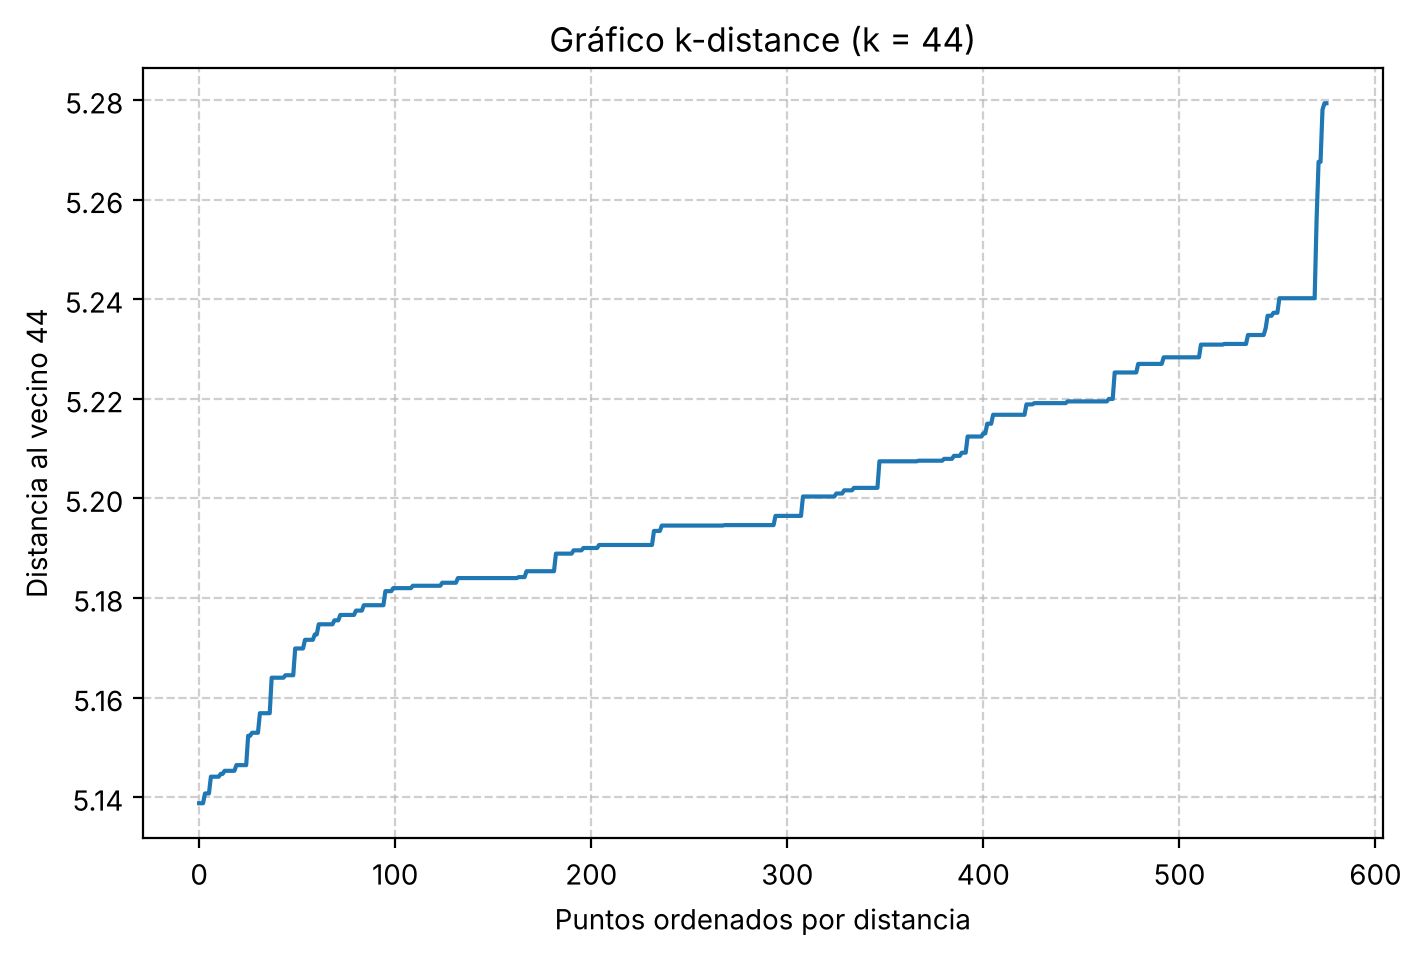

count    576.000
mean       5.199
std        0.024
min        5.139
50%        5.195
75%        5.219
90%        5.231
95%        5.237
99%        5.244
max        5.279
dtype: float64


In [43]:
# Regla práctica: min_samples >= 2 * número de dimensiones
n_dim = X_train_std.shape[1]
min_samples_ref = 2 * n_dim
print("Dimensiones:", n_dim, "| min_samples de referencia:", min_samples_ref)

# Distancia de cada punto a su k-ésimo vecino más cercano (k = min_samples), ordenada de menor a mayor
vecinos = NearestNeighbors(n_neighbors=min_samples_ref).fit(X_train_std)
distancias, _ = vecinos.kneighbors(X_train_std)
k_dist = np.sort(distancias[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_dist)
plt.title(f'Gráfico k-distance (k = {min_samples_ref})')
plt.xlabel('Puntos ordenados por distancia')
plt.ylabel(f'Distancia al vecino {min_samples_ref}')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Percentiles para ubicar el "codo" de la curva
print(pd.Series(k_dist).describe(percentiles=[.5, .75, .9, .95, .99]).round(3))

In [44]:
eps_lista = [3.5, 4.0, 4.5, 4.9, 5.0, 5.2, 6.0]
min_samples_lista = [5, 12, 32, min_samples_ref]

resultados_db = []
for eps in eps_lista:
    for ms in min_samples_lista:
        etiquetas = DBSCAN(eps=eps, min_samples=ms, n_jobs=-1).fit_predict(X_train_std)

        n_clusters = len(set(etiquetas)) - (1 if -1 in etiquetas else 0)
        pct_ruido = (etiquetas == -1).mean() * 100

        # Silhouette solo se puede calcular con 2 o más clusters (sin contar el ruido)
        sil = np.nan
        mascara = etiquetas != -1
        if n_clusters >= 2:
            sil = silhouette_score(X_train_std[mascara], etiquetas[mascara],
                                   sample_size=5000, random_state=42)

        resultados_db.append({'eps': eps, 'min_samples': ms,
                              'Clusters': n_clusters,
                              '% Ruido': round(pct_ruido, 2),
                              'Silhouette': round(sil, 4) if not np.isnan(sil) else np.nan,
                              'ARI': round(adjusted_rand_score(y_train, etiquetas), 4)})

tabla_dbscan = pd.DataFrame(resultados_db)
tabla_dbscan

,eps,min_samples,Clusters,% Ruido,Silhouette,ARI
0,3.5,5,0,100.00,NaN,0.0000
1,3.5,12,0,100.00,NaN,0.0000
2,3.5,32,0,100.00,NaN,0.0000
3,3.5,44,0,100.00,NaN,0.0000
4,4.0,5,8,0.00,0.2162,-0.0036
5,4.0,12,16,40.80,0.1115,0.0201
6,4.0,32,0,100.00,NaN,0.0000
7,4.0,44,0,100.00,NaN,0.0000
8,4.5,5,1,0.00,NaN,0.0000
9,4.5,12,1,0.00,NaN,0.0000


In [45]:
# Valores finales: min_samples por la regla 2*dimensiones; eps = primer valor (con 1 decimal)
# que cubre TODOS los puntos de la curva k-distance, es decir, el menor eps que no deja ruido.
MIN_SAMPLES_FINAL = min_samples_ref
EPS_FINAL = float(np.ceil(k_dist.max() * 10) / 10)

dbscan = DBSCAN(eps=EPS_FINAL, min_samples=MIN_SAMPLES_FINAL, n_jobs=-1)
etiquetas_db = dbscan.fit_predict(X_train_std)

n_clusters_db = len(set(etiquetas_db)) - (1 if -1 in etiquetas_db else 0)
print(f"eps = {EPS_FINAL} | min_samples = {MIN_SAMPLES_FINAL}")
print("Clusters encontrados:", n_clusters_db)
print("Puntos de ruido:", (etiquetas_db == -1).sum(), f"({(etiquetas_db == -1).mean()*100:.2f}%)")
print("ARI (DBSCAN vs clases reales):", round(adjusted_rand_score(y_train, etiquetas_db), 4))
print("\nRegistros por cluster (-1 = ruido):")
print(pd.Series(etiquetas_db).value_counts().sort_index())

eps = 5.3 | min_samples = 44
Clusters encontrados: 1
Puntos de ruido: 0 (0.00%)
ARI (DBSCAN vs clases reales): 0.0

Registros por cluster (-1 = ruido):
0    576
Name: count, dtype: int64


### Por qué estos valores de `min_samples` y `eps`

**`min_samples = 44`.** La regla práctica pide al menos 2 veces el número de dimensiones, y aquí hay 22 columnas, así que 44. Un valor muy bajo (como 5 o 12) hace que cualquier grupito de puntos cercanos forme un cluster y aparecen grupos pequeños por puro ruido (en la tabla, `eps = 4.0` con `min_samples = 5` da 8 clusters y con 12 da 16 clusters y 41 % de ruido, y ninguno coincide con las clases). Un valor muy alto convierte en ruido grupos legítimos.

**`eps = 5.3`.** Se saca del gráfico *k-distance*: para cada punto se mide la distancia a su vecino número 44 y se ordenan. Lo normal es una zona plana (puntos en zonas densas) y al final un **codo** donde la curva sube de golpe (puntos aislados), y `eps` se pone justo en el codo. Aquí **no hay codo**: la curva es casi horizontal (va de 5.14 a 5.28 y el 99 % de los puntos queda por debajo de 5.24). Eso significa que todos los puntos tienen la misma densidad local. Por eso solo hay dos comportamientos posibles: con `eps` por debajo de ≈ 5.1 todo es ruido, y con `eps` de 5.2 en adelante todo forma un único cluster. Se escoge el menor `eps` (con un decimal) que cubre todos los puntos de la curva: 5.3.

**Cómo se confirma.** La tabla prueba combinaciones alrededor de ese rango: con `min_samples = 44`, los valores de `eps` de 4.9 y 5.0 (y todos los menores) dejan 100 % de ruido, y desde 5.2 hay un único cluster con 0 % de ruido. En ninguna fila aparecen grupos que coincidan con las clases (el ARI es 0 en todas).

**Qué significa el resultado.** DBSCAN agrupa por *zonas densas separadas por vacíos*. Este dataset es una rejilla completa de combinaciones, sin vacíos: no hay densidades distintas que separar, así que el resultado correcto es "un solo grupo". No es un fallo del algoritmo: es lo que dicen los datos. K-Means sí encontró 3 grupos porque **siempre** parte en *k* trozos, haya o no separación natural.

In [46]:
# Contraste: DBSCAN sobre los 2 componentes de PCA (el plano que se dibuja), no sobre las 22 columnas
db_2d = DBSCAN(eps=0.3, min_samples=10).fit_predict(X_pca)
print("DBSCAN en 2D (PCA): clusters =", len(set(db_2d)) - (1 if -1 in db_2d else 0),
      "| ruido =", f"{(db_2d == -1).mean()*100:.2f}%")
print("ARI de DBSCAN en 2D vs clases reales:", round(adjusted_rand_score(y_train, db_2d), 4))
print("DBSCAN en 22D     : clusters =", n_clusters_db)

DBSCAN en 2D (PCA): clusters = 3 | ruido = 1.74%
ARI de DBSCAN en 2D vs clases reales: 0.9737
DBSCAN en 22D     : clusters = 1


**¿Por qué en la gráfica de PCA se ven 3 grupos y DBSCAN dice 1?** Porque DBSCAN trabaja con las 22 columnas, no con el plano. En 2 dimensiones solo se ve `Under Tone`, y esos 3 bloques sí están separados; en 22 dimensiones cada punto tiene vecinos que difieren solo en pelo, ojos o piel, y esos vecinos conectan los 3 bloques entre sí. Por eso la conclusión de DBSCAN hay que leerla en el espacio completo.

##**GRAFICAS**

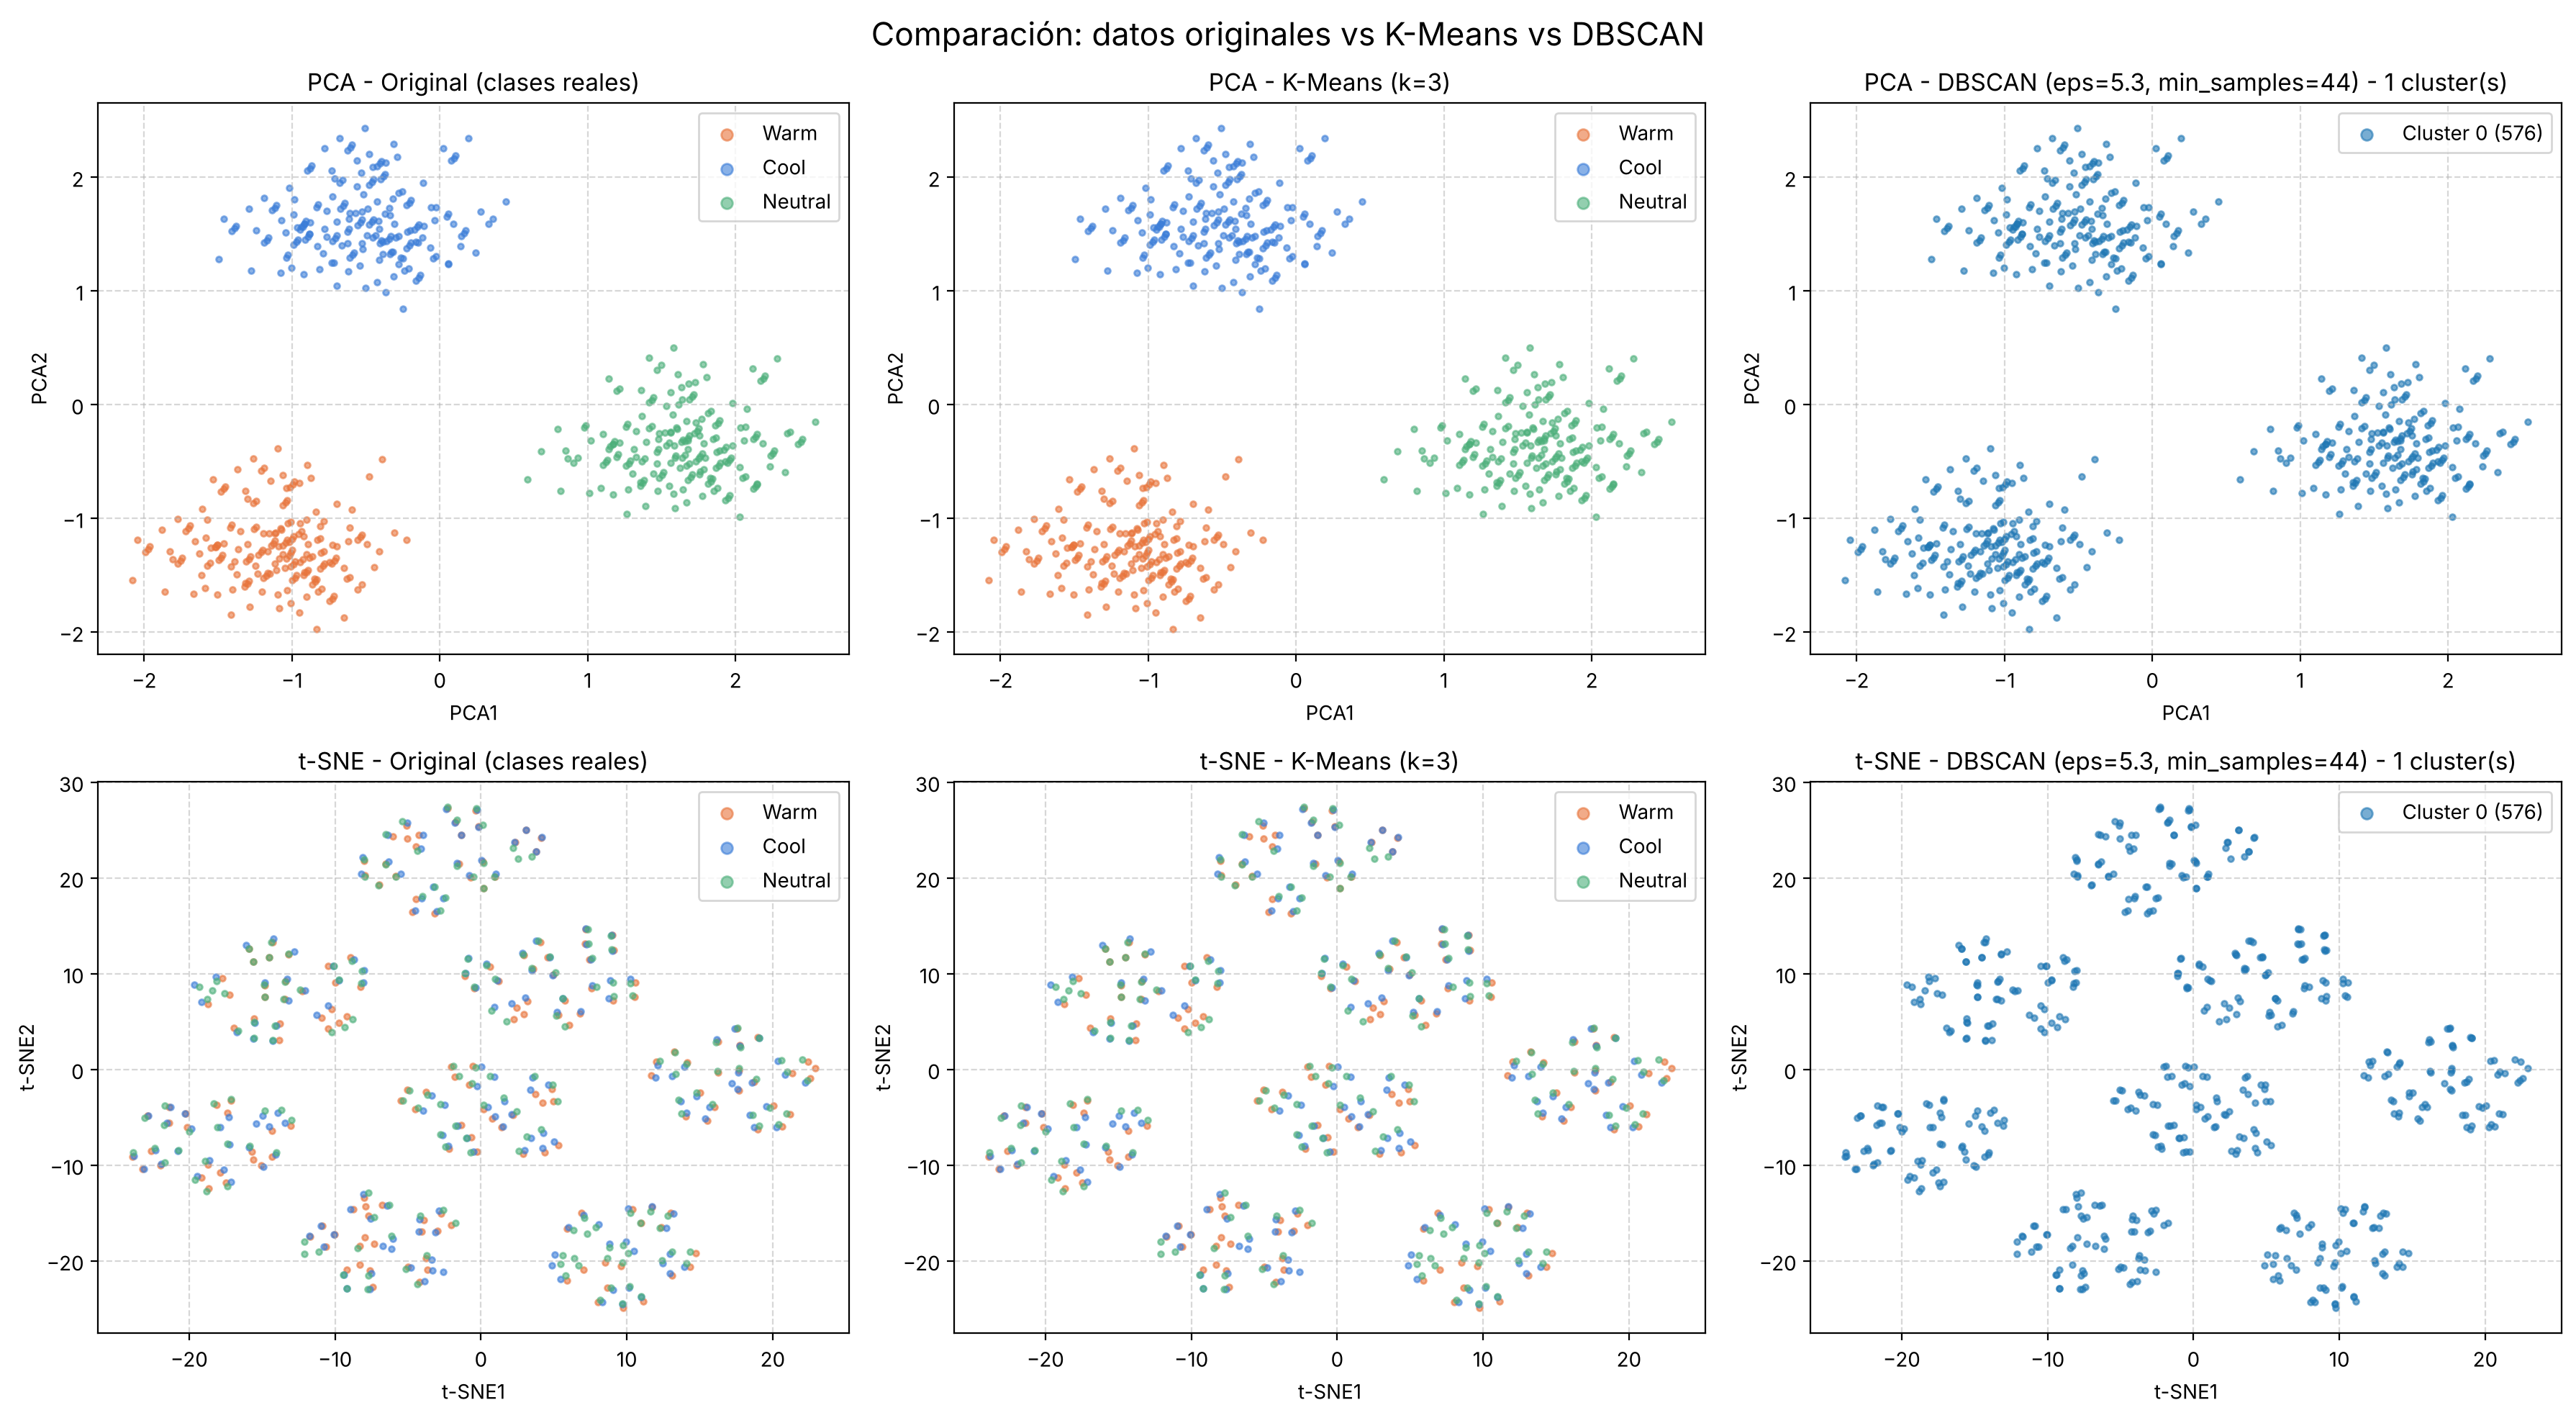

In [47]:
# Datos 2D de PCA (todo train) y de t-SNE (muestra con posiciones idx)
pca_xy = df_pca[['PCA1', 'PCA2']].values
tsne_xy = df_tsne[['TSNE1', 'TSNE2']].values

# Etiquetas: original, K-Means (renombrado para coincidir con los colores de las clases) y DBSCAN
etq_original = y_train
etq_kmeans = clusters_alineados
etq_dbscan = etiquetas_db

vistas = {
    'PCA':   (pca_xy,  etq_original,      etq_kmeans,      etq_dbscan),
    't-SNE': (tsne_xy, etq_original[idx], etq_kmeans[idx], etq_dbscan[idx]),
}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for fila, (nombre, (xy, orig, km, db)) in enumerate(vistas.items()):

    # 1. Original (clases reales)
    pintar_clases(axes[fila, 0], xy, orig)
    axes[fila, 0].set_title(f'{nombre} - Original (clases reales)')

    # 2. K-Means
    pintar_clases(axes[fila, 1], xy, km)
    axes[fila, 1].set_title(f'{nombre} - K-Means (k={n_clases})')

    # 3. DBSCAN (el ruido, etiqueta -1, se dibuja en negro)
    ruido = db == -1
    for j, c in enumerate(sorted(set(db) - {-1})):
        m = db == c
        axes[fila, 2].scatter(xy[m, 0], xy[m, 1], s=8, alpha=0.6, color=plt.cm.tab10(j % 10),
                              label=f'Cluster {c} ({m.sum()})')
    if ruido.any():
        axes[fila, 2].scatter(xy[ruido, 0], xy[ruido, 1], c='black', marker='x', s=15, label=f'Ruido ({ruido.sum()})')
    n_cl = len(set(db)) - (1 if -1 in db else 0)
    axes[fila, 2].set_title(f'{nombre} - DBSCAN (eps={EPS_FINAL}, min_samples={MIN_SAMPLES_FINAL}) - {n_cl} cluster(s)')
    axes[fila, 2].legend(loc='upper right', markerscale=2)

    for col in range(3):
        axes[fila, col].set_xlabel(f'{nombre}1')
        axes[fila, col].set_ylabel(f'{nombre}2')
        axes[fila, col].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Comparación: datos originales vs K-Means vs DBSCAN', fontsize=16)
plt.tight_layout()
plt.show()

### Cómo leer las gráficas

- **Original:** cada punto es una persona; el color es su paleta real (cálida, fría, neutra). En **PCA** se ven 3 grupos compactos, uno por color: el subtono es la variable que domina los dos componentes. En **t-SNE** los colores aparecen **mezclados**, porque t-SNE conserva vecindades en las 22 dimensiones y ahí los vecinos más cercanos difieren en una sola variable, que casi nunca es el subtono.
- **K-Means:** los colores son los de la paleta con la que cada cluster coincide. Como K-Means (con 100 inicios) recuperó exactamente las clases (ARI = 1), esta gráfica es idéntica a la original.
- **DBSCAN:** un solo cluster, sin ruido, porque en las 22 dimensiones los datos no tienen zonas densas separadas por vacíos (ver la explicación de `eps` y `min_samples`). Los 3 bloques de PCA no lo contradicen: son solo la proyección a 2D.

### Conclusiones de la tercera parte

1. **Escalado:** StandardScaler cambia los datos; MinMaxScaler no, porque el One-Hot ya está en [0, 1]. Las conclusiones finales son las mismas con los dos, pero con StandardScaler K-Means necesita muchos más inicios para encontrar el subtono.
2. **PCA/t-SNE:** 2 componentes explican solo ≈ 14 % de la varianza, porque las variables son independientes; los dos componentes se forman casi solo con `Under Tone` (la variable con menos categorías) y por eso PCA muestra 3 grupos, uno por subtono. Sirven para visualizar, no para resumir estos datos.
3. **K-Means (k = 3):** con 100 inicios recupera las clases (ARI = 1) y esa partición es la de menor inercia, pero con pocos inicios se queda en mínimos locales (ARI ≈ 0.11 con `n_init=10`).
4. **DBSCAN:** un solo cluster. Es el resultado correcto para una rejilla completa de combinaciones.
5. **Contraste con la parte supervisada:** los modelos supervisados aciertan el 100 % porque *se les da* el subtono y la etiqueta; el clustering, que no la ve, solo la recupera gracias a la estructura del dataset y probando muchos inicios. La información útil está en el subtono, y conseguirlo (p. ej. desde una foto) es el siguiente paso del proyecto.